# 03 - Abnormal-motion detection: temporal features, normal baseline, multi-signal abnormality
**Question answered: HAS THE CROWD'S MOVEMENT SUDDENLY CHANGED?**   Self-contained notebook.

| | |
|---|---|
| **Reads** | TUB CrowdFlow; `models/crowd_count_model.pth` (notebook 01); `models/flow_selection.json` (+ `motion_model.pth`) (notebook 02) |
| **Writes** | `models/abnormal_motion.json` (change model, detector, feature config, label rules, split), `outputs/predictions/risk_feature_dataset.csv`, figures / metrics |
| **Next** | `04_Risk_Analysis_and_Video_Inference` |

### Core principle: *high speed is not automatically abnormal*
Normal crowds can be slow, fast-but-steady, or change density gradually. Abnormality is a **sudden deviation from the crowd's own recent behaviour**, supported by **several independent signals**.

### Logic
1. **Windows:** `WINDOW_LEN` motion steps (default 20) with hop `HOP` (5). For each window the **predicted** flow (selected estimator) gives speed, acceleration, direction, counter-flow, scattering, compression, convergence ...; the **crowd-count model** gives count, density, occupancy, density-map statistics (`density_concentration`, `local_density_gradient`, `occupied_area_ratio`, `packed_density`, ...); flow-advected trajectories give track statistics.
2. **Normal-baseline / change model (fitted on TRAIN windows only):** for each feature
   `change_score = (value - median of the previous K=4 windows) / max(recent robust scale, TRAIN-fitted step scale)`,
   plus `*_delta`, `*_ratio`, `*_jump` (abrupt step vs typical recent step), `speed_zscore`, `speed_percentile`, `occupancy_zscore`. The TRAIN-fitted step scale stops quiet baselines from producing huge scores out of tiny fluctuations.
3. **Ten evidence signals** (`E_*` in 0..1): speed, acceleration, direction, occupancy, density, compression, scattering, counter-flow, convergence, temporal-change (abruptness). A signal is *active* when its robust deviation exceeds a threshold that is **tuned on VALIDATION** (default 3.0 kept unless tuning gains >= 0.02 F1).
4. **Independent-evidence combination:** `abnormality_score = 1 - prod(1 - reliability_i * E_i)` (noisy-OR). `reliability_i` = precision of signal *i* on TRAIN windows. `n_active_signals` and `n_active_groups` (5 independent groups: motion-magnitude, direction, crowd-size, interaction, dispersion) are exposed. Level: **1 weak signal / >= 2 related signals / >= 3 independent groups**; cut-offs tuned on validation.
5. **Tags:** `NORMAL, SUDDEN_SPEED_CHANGE, SUSTAINED_HIGH_SPEED, SUDDEN_ACCELERATION, SUDDEN_DIRECTION_CHANGE, DIRECTION_INSTABILITY, OCCUPANCY_INCREASE, OCCUPANCY_DROP, DENSITY_SURGE, DENSITY_COMPRESSION, SCATTERING, COUNTER_FLOW, CONVERGENCE, MULTI_SIGNAL_ABNORMAL`. A window can carry several. `SUSTAINED_HIGH_SPEED` alone is weak; sudden speed change + direction change + density change + compression activates several independent groups and is therefore much stronger.
6. **Derived (weak) labels** - NOT official: risk labels come from the original rule set on *ground-truth* flow / masks / trajectories (thresholds fitted on TRAIN scenes) plus **injected anomalies** (rush, scatter, converge, counter-flow, direction chaos, panic) with labels known by construction. Per-signal truth = the same robust change scores on the ground-truth windows (z >= 3) or by construction for injected windows. Used for fitting / tuning / evaluation only - never at inference.

## 0. Configuration

In [1]:
# ============================================================
# USER CONFIGURATION   (the only cell you normally need to edit)
# ============================================================
import os
NOTEBOOK_NAME = "03_Abnormal_Motion_Detection"
DATASET_ROOT = r"C:\main project\stampede-risk-estimation\data\raw"     # folder that CONTAINS 'tubcrowdflow' (and 'shanghaitech'); searched automatically (~4 levels deep)
OUTPUT_DIR = "./crowdrisk_outputs"      # USE THE SAME FOLDER IN ALL FOUR NOTEBOOKS: trained models / metrics are exchanged through <OUTPUT_DIR>/models and <OUTPUT_DIR>/outputs
SEED = 42
USE_GPU = True                          # True -> CUDA if available, otherwise CPU

WINDOW_LEN = 20              # motion steps per temporal window
HOP = 5                      # steps between consecutive windows
FPS = 25.0                   # ASSUMPTION about the TUB frame rate (only converts per-frame rates into per-second rates)
COUNT_STRIDE_TRAINING = 10   # the crowd-count model runs on every N-th frame of the TUB scenes while the training windows are built
# needs from the earlier notebooks:  models/crowd_count_model.pth (notebook 01)  and  models/flow_selection.json (+ motion_model.pth) (notebook 02)
SMOKE_TEST = os.environ.get("CROWDRISK_SMOKE", "0") == "1"   # True: tiny SYNTHETIC datasets + tiny models (checks the code path in minutes; metrics are meaningless)


In [2]:
# ---- SMOKE TEST mode (optional): everything below is replaced by tiny synthetic datasets / models so the WHOLE notebook runs in minutes ----
import tempfile
if SMOKE_TEST:
    _SMOKE_BASE = os.path.join(tempfile.gettempdir(), "crowdrisk_smoke")
    DATASET_ROOT = os.path.join(_SMOKE_BASE, "data", "raw"); NEGATIVE_DIR = os.path.join(_SMOKE_BASE, "shanghai_negative_sampling")
    if OUTPUT_DIR == "./crowdrisk_outputs": OUTPUT_DIR = os.path.join(_SMOKE_BASE, "outputs")
    WINDOW_LEN, HOP, FPS = 12, 4, 15.0; COUNT_PRESET = "smoke"; MOTION_WIDTHS = [96, 144, 192]; USE_RAFT = False; COUNT_STRIDE_TRAINING = 6; COUNT_EVERY = 3
    MOTION_TRAIN = dict(epochs=2, items_per_epoch=16, batch=4, crop=96, base=8, lr=1e-3); NEG_FRACTION = 0.3; VIDEO_PATH = None
    print("*** SMOKE TEST: synthetic data in", _SMOKE_BASE, "- code-path check only, all metrics are meaningless ***")


## 1. Environment and dependencies

In [3]:
# ---- dependency check: installs ONLY what is missing (a one-time `pip install torch torchvision` can be large) ---------------------
import sys, importlib, importlib.util, subprocess
_need = {"numpy": "numpy", "scipy": "scipy", "pandas": "pandas", "cv2": "opencv-python", "matplotlib": "matplotlib", "sklearn": "scikit-learn", "tqdm": "tqdm",
         "joblib": "joblib", "torch": "torch", "torchvision": "torchvision", "PIL": "pillow", "lightgbm": "lightgbm"}
if not NOTEBOOK_NAME.startswith("04"): _need.pop("lightgbm")                 # only the risk notebook needs the tree-model packages
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing:", _missing)
    try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
    except Exception as e: print(f"[WARNING] automatic install failed ({e}). Run in a terminal, then restart the kernel:\n    {sys.executable} -m pip install " + " ".join(_missing))
else: print("all required packages are installed")
for _opt, _why in ((("lightgbm", "LightGBM risk model (falls back to XGBoost / scikit-learn HistGradientBoosting)"), ("xgboost", "XGBoost fallback")) if NOTEBOOK_NAME.startswith("04") else ()):
    if importlib.util.find_spec(_opt) is None: print(f"[info] optional package '{_opt}' not installed -> {_why}")


all required packages are installed


In [4]:
# ---- from notebook 00 cell 4
# ============================================================================
# Imports, environment helpers (portable: Colab / VS Code / plain Jupyter)
# ============================================================================
import os, sys, io, math, time, json, glob, copy, random, shutil, hashlib, warnings, zipfile, tempfile
import numpy as np, pandas as pd, cv2, scipy.io as sio
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.ndimage import maximum_filter
import matplotlib
if os.environ.get("CC_HEADLESS"): matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from tqdm.auto import tqdm
warnings.filterwarnings("ignore"); cv2.setNumThreads(1)
IN_COLAB = "google.colab" in sys.modules

def pick_device(pref="auto"):
    """'auto' -> CUDA if available else CPU. Never hard-codes CUDA."""
    pref = (pref or "auto").lower()
    if pref == "cpu": return torch.device("cpu")
    if torch.cuda.is_available(): return torch.device("cuda")
    if pref in ("cuda", "gpu"): print("[warn] CUDA was requested but is not available -> using CPU.")
    return torch.device("cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def json_safe(o):
    """Recursively convert numpy / tuple / Path objects into JSON-compatible python types."""
    if isinstance(o, dict): return {str(k): json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [json_safe(v) for v in o]
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (str, int, float, bool)) or o is None: return o
    return str(o)

def save_atomic(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def torch_load_safe(path, device):
    try: return torch.load(path, map_location=device, weights_only=True)
    except Exception: return torch.load(path, map_location=device, weights_only=False)      # our own files only

def ceil_to(x, m=32): return int(math.ceil(x / m) * m)

try: from IPython.display import display, Markdown
except Exception:
    display = print
    def Markdown(x): return x

# ---------------------------------------------------------------- default inference / refinement settings (shared by both notebooks)
DEFAULT_REFINE = dict(
    enabled=True, region_size=128,      # px (original image) of the analysis grid cells
    min_region_density=6.0,             # ignore regions whose density estimate is below this many people
    abs_gap=3.0, rel_gap=0.30,          # flag if (density - accepted points) >= max(abs_gap, rel_gap*density)
    min_uncertain=3,                    # ... or if >= this many uncertain (yellow) points sit in the region
    crop_margin=32,                     # px of context added around the region (overlap with neighbours)
    scale=2.0, scale_growth=1.5, max_scale=3.0,   # effective-resolution multiplier on iteration 0, growth per iteration, hard cap
    max_iters=2, max_regions=12,        # max refinement iterations / max regions re-analysed per image
    max_crop_pixels=1.5e6,              # memory guard for the up-scaled crop
    policy="replace_if_more")           # 'union' | 'replace_if_more' | 'replace'  (see _merge_region)

DEFAULT_INFER = dict(
    density_scale=10.0, min_long=640, max_long=1536, max_pixels=2.0e6, tile=768, tile_overlap=128,
    exposure_norm=True, exposure_target=0.42, min_candidate_conf=0.05, peak_min_value=0.01, amp=False,
    conf_accept=0.5, uncertain_ratio=0.5, dup_radius=3.0, refine=copy.deepcopy(DEFAULT_REFINE))




# ---- extra imports used by the motion / risk parts --------------------------------------------------------------------------------
import re, struct, datetime, dataclasses
from dataclasses import dataclass, field
from collections import deque
from scipy.ndimage import gaussian_filter, binary_dilation
import joblib
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, average_precision_score, f1_score, roc_curve, precision_recall_curve, classification_report)


c:\main project\stampede-risk-estimation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# ---- run folders, seeds, device, reproducibility record (the SAME OUTPUT_DIR is used by all four notebooks) -----------------------------------------
import datetime
SEED = int(SEED); set_seed(SEED)
OUTPUT_DIR = os.path.abspath(OUTPUT_DIR)
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
OUTPUTS = os.path.join(OUTPUT_DIR, "outputs")
METRICS_DIR, FIG_DIR, VIDEO_DIR, PRED_DIR = (os.path.join(OUTPUTS, d) for d in ("metrics", "figures", "videos", "predictions"))
WORK_DIR = os.path.join(OUTPUT_DIR, "work")                        # caches / checkpoints / extracted files (safe to delete, will be rebuilt)
COUNT_OUT = os.path.join(WORK_DIR, "count")                        # crowd-count training work folder (checkpoints, caches, tables)
CACHE_DIR = os.path.join(WORK_DIR, "cache")                        # TUB work-resolution cache + count cache
VIDEO_IN_DIR = os.path.join(OUTPUT_DIR, "videos_in")
for _d in (MODELS_DIR, METRICS_DIR, FIG_DIR, VIDEO_DIR, PRED_DIR, WORK_DIR, COUNT_OUT, CACHE_DIR, VIDEO_IN_DIR): os.makedirs(_d, exist_ok=True)
DEVICE = pick_device("auto" if USE_GPU else "cpu")
if DEVICE.type == "cuda": torch.backends.cudnn.benchmark = True
RUN_META = dict(notebook=NOTEBOOK_NAME, created=datetime.datetime.now().isoformat(timespec="seconds"), seed=SEED, device=str(DEVICE), smoke_test=SMOKE_TEST, torch=torch.__version__)
print(f"[{NOTEBOOK_NAME}] seed {SEED} | device {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " (CPU only)") + f" | OUTPUT_DIR = {OUTPUT_DIR}")
print("trained models are exchanged between the notebooks through", MODELS_DIR)


[03_Abnormal_Motion_Detection] seed 42 | device cpu (CPU only) | OUTPUT_DIR = c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs
trained models are exchanged between the notebooks through c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models


## 2. Library code (TUB reader, flow estimators, features, labels, tracking, crowd-count inference)

In [6]:
def _is_dir(p) -> bool:
    try: return os.path.isdir(p)
    except OSError: return False


def _has_shanghai(d: str) -> bool:
    if not _is_dir(d): return False
    names = {n.lower() for n in os.listdir(d)}
    return any(n.startswith("part_a") for n in names) and any(n.startswith("part_b") for n in names)


def _has_tub(d: str) -> bool:
    if not _is_dir(d): return False
    names = {n.lower() for n in os.listdir(d)}
    return ("images" in names or "image" in names) and any(n in names for n in ("gt_flow", "flow", "flows"))


def _find_child(parent: str, names):
    if not _is_dir(parent): return None
    low = {n.lower(): n for n in os.listdir(parent)}
    for n in names:
        if n.lower() in low: return os.path.join(parent, low[n.lower()])
    return None


def _bounded_walk(base: str, max_depth: int, test, skip=("node_modules", ".git", "__pycache__", "site-packages")):
    """Return first directory below `base` (depth <= max_depth) for which test(dir) is true."""
    base = os.path.abspath(base)
    if not _is_dir(base): return None
    if test(base): return base
    queue = [(base, 0)]
    while queue:
        cur, depth = queue.pop(0)
        if depth >= max_depth: continue
        try: kids = sorted(os.listdir(cur))
        except OSError: continue
        for k in kids:
            if k in skip or k.startswith("."): continue
            p = os.path.join(cur, k)
            if not _is_dir(p): continue
            if test(p): return p
            queue.append((p, depth + 1))
    return None


In [7]:
TUB_IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

FLO_MAGIC = 202021.25


def read_flo(path):
    with open(path, "rb") as f:
        magic = struct.unpack("<f", f.read(4))[0]
        if abs(magic - FLO_MAGIC) > 1e-3: raise ValueError(f"{path}: not a valid .flo file (magic={magic})")
        w, h = struct.unpack("<ii", f.read(8))
        if not (0 < w < 20000 and 0 < h < 20000): raise ValueError(f"{path}: invalid size {w}x{h}")
        data = np.frombuffer(f.read(w * h * 2 * 4), dtype="<f4")
    if data.size != w * h * 2: raise ValueError(f"{path}: truncated .flo file")
    return data.reshape(h, w, 2).astype(np.float32)


def write_flo(path, flow):
    h, w = flow.shape[:2]
    with open(path, "wb") as f:
        f.write(struct.pack("<f", FLO_MAGIC)); f.write(struct.pack("<ii", w, h)); f.write(np.ascontiguousarray(flow, dtype="<f4").tobytes())


def _num_key(p):
    nums = re.findall(r"\d+", os.path.basename(p)); return (int(nums[-1]) if nums else -1, os.path.basename(p))


def _list(d, exts):
    if not d or not os.path.isdir(d): return []
    out = [os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(exts)]
    return sorted(out, key=_num_key)


def base_scene(name):
    """'IM03_hDyn' -> 'IM03'. A scene and its '_hDyn' variant are grouped together for splitting (they most likely share content)."""
    return re.sub(r"[_\-]?hdyn$", "", name, flags=re.I)


def work_size(orig_w, orig_h, work_width=320):
    w = int(work_width); h = int(round(orig_h * w / orig_w / 2.0) * 2); return w, max(h, 16)


class Scene:
    """One TUB CrowdFlow sequence. Pairs: flow j  <->  frames (j, j+1)."""
    def __init__(self, name, images, flows, masks, traj_file):
        self.name, self.group = name, base_scene(name)
        self.images, self.flows, self.masks, self.traj_file = images, flows, masks, traj_file
        n_img, n_flow = len(images), len(flows)
        self.n_pairs = min(n_flow, n_img - 1) if n_flow else max(n_img - 1, 0)
        self.has_flow = n_flow > 0
        self.pair_note = ("flows == frames-1 (standard)" if n_flow == n_img - 1 else
                          f"flows ({n_flow}) != frames-1 ({n_img - 1}): using the first {self.n_pairs} pairs; check the dataset" if n_flow else "no flow files")
        self._size = None

    def __repr__(self): return f"Scene({self.name}, frames={len(self.images)}, flows={len(self.flows)}, masks={len(self.masks)}, group={self.group})"

    @property
    def orig_size(self):
        if self._size is None:
            im = cv2.imread(self.images[0]); assert im is not None, f"cannot read {self.images[0]}"
            self._size = (im.shape[1], im.shape[0])
        return self._size

    def frame(self, i, wsize=None):
        im = cv2.imread(self.images[i], cv2.IMREAD_COLOR)
        if im is None: raise IOError(f"cannot read image {self.images[i]}")
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        return cv2.resize(im, wsize, interpolation=cv2.INTER_AREA) if wsize else im

    def gt_flow(self, j, wsize=None):
        """Ground-truth flow of pair j resized to `wsize`; the VECTORS are rescaled by the same factors (flow is in pixels)."""
        fl = read_flo(self.flows[j]); h, w = fl.shape[:2]
        if wsize and (wsize[0] != w or wsize[1] != h):
            fl = cv2.resize(fl, wsize, interpolation=cv2.INTER_AREA); fl[..., 0] *= wsize[0] / w; fl[..., 1] *= wsize[1] / h
        return fl

    def mask(self, j, wsize=None):
        if not self.masks: return None
        k = min(j, len(self.masks) - 1); m = cv2.imread(self.masks[k], cv2.IMREAD_UNCHANGED)
        if m is None: return None
        if m.ndim == 3: m = m.max(axis=2)
        m = (m > 0).astype(np.uint8)
        return cv2.resize(m, wsize, interpolation=cv2.INTER_NEAREST).astype(bool) if wsize else m.astype(bool)


def discover_scenes(paths, verbose=True):
    """Scenes found under <tub>/images/<scene>/ (same structure the original motion notebook used)."""
    if not paths.tub_images or not os.path.isdir(paths.tub_images): raise FileNotFoundError("TUB CrowdFlow images folder not found (see the startup path report).")
    scenes = []
    for name in sorted(os.listdir(paths.tub_images)):
        d = os.path.join(paths.tub_images, name)
        if not os.path.isdir(d): continue
        imgs = _list(d, TUB_IMG_EXT); flows = _list(os.path.join(paths.tub_flow, name), (".flo",)) if paths.tub_flow else []
        masks = _list(os.path.join(paths.tub_masks, name), TUB_IMG_EXT) if paths.tub_masks else []
        tf = None
        if paths.tub_traj and os.path.isdir(os.path.join(paths.tub_traj, name)):
            cands = sorted(glob.glob(os.path.join(paths.tub_traj, name, "*.mat")))
            pref = [c for c in cands if "dense" in os.path.basename(c).lower()]; tf = (pref or cands or [None])[0]
        if len(imgs) >= 2: scenes.append(Scene(name, imgs, flows, masks, tf))
    if not scenes: raise RuntimeError(f"No scenes with >= 2 images under {paths.tub_images}")
    if verbose:
        print(f"TUB CrowdFlow: {len(scenes)} scenes -> groups: {sorted({s.group for s in scenes})}")
        for s in scenes: print(f"  {s.name:<14} frames={len(s.images):4d} flows={len(s.flows):4d} masks={len(s.masks):4d} traj={'yes' if s.traj_file else 'no '} | {s.pair_note}")
    return scenes


# ------------------------------------------------------------------------------------------------ trajectories
def load_trajectories(scene, layout="auto", max_tracks=4000, seed=0):
    """Dense trajectories -> array (T, N, 2) in ORIGINAL image pixels, NaN where a track is not defined.
    The .mat variable is a (N_tracks, 2*T) matrix. Whether columns are interleaved (x0,y0,x1,y1,...) or blocked (x0..xT, y0..yT) is
    detected automatically (the layout with the smoother tracks wins) unless `layout` is given. Returns (tracks, info_dict)."""
    import scipy.io as sio
    if not scene.traj_file: return None, dict(note="no trajectory file")
    d = sio.loadmat(scene.traj_file)
    key = "matTrajectsCopy" if "matTrajectsCopy" in d else next((k for k, v in d.items() if not k.startswith("__") and isinstance(v, np.ndarray) and v.ndim == 2), None)
    if key is None: return None, dict(note="no 2-D array in the .mat file")
    M = np.asarray(d[key], dtype=np.float64)
    if M.shape[1] % 2 and M.shape[0] % 2 == 0: M = M.T
    N, C = M.shape; T = C // 2; W, H = scene.orig_size
    rng = np.random.default_rng(seed)
    if N > max_tracks: M = M[rng.choice(N, max_tracks, replace=False)]
    def build(lay):
        x, y = (M[:, 0::2], M[:, 1::2]) if lay == "interleaved" else (M[:, :T], M[:, T:2 * T])
        t = np.stack([x, y], -1).transpose(1, 0, 2).copy()           # (T, N, 2)
        bad = ~np.isfinite(t).all(-1) | ((t[..., 0] == 0) & (t[..., 1] == 0)) | (t[..., 0] < -W) | (t[..., 0] > 2 * W) | (t[..., 1] < -H) | (t[..., 1] > 2 * H)
        t[bad] = np.nan; return t
    cands = {l: build(l) for l in ("interleaved", "blocked")}
    def roughness(t):
        s = np.linalg.norm(np.diff(t, axis=0), axis=-1); s = s[np.isfinite(s)]
        return float(np.median(s)) if s.size else np.inf
    rough = {l: roughness(t) for l, t in cands.items()}
    chosen = layout if layout in cands else min(rough, key=rough.get)
    tr = cands[chosen]; valid = float(np.isfinite(tr[..., 0]).mean())
    return tr.astype(np.float32), dict(key=key, shape_mat=(N, C), T=T, layout=chosen, roughness=rough, valid_fraction=valid, frames_in_scene=len(scene.images),
                                      note=("trajectory length matches the number of frames" if T == len(scene.images) else f"trajectory length T={T} != frames {len(scene.images)}"))


# ------------------------------------------------------------------------------------------------ sequence-aware splitting
def split_groups(groups, seed=42, n_val=1, n_test=1):
    """Split SCENE GROUPS (never individual frames) into train / val / test. 'IM03' and 'IM03_hDyn' always stay together."""
    gs = sorted(set(groups)); rng = np.random.default_rng(seed); perm = list(rng.permutation(len(gs)))
    n_test = min(n_test, max(len(gs) - 2, 0)); n_val = min(n_val, max(len(gs) - n_test - 1, 0))
    test = [gs[i] for i in perm[:n_test]]; val = [gs[i] for i in perm[n_test:n_test + n_val]]; train = [gs[i] for i in perm[n_test + n_val:]]
    return dict(train=sorted(train), val=sorted(val), test=sorted(test))


def logo_folds(groups, seed=42):
    """Leave-one-scene-group-out: for each held-out group (test) one other group is validation, the rest train."""
    gs = sorted(set(groups)); rng = np.random.default_rng(seed); folds = []
    for g in gs:
        rest = [x for x in gs if x != g]; v = rest[int(rng.integers(len(rest)))] if len(rest) > 1 else None
        folds.append(dict(test=[g], val=[v] if v else [], train=[x for x in rest if x != v]))
    return folds


def print_split(split, scenes):
    by_g = {}
    for s in scenes: by_g.setdefault(s.group, []).append(s.name)
    print("SEQUENCE-LEVEL SPLIT (no frame of a scene appears in more than one subset):")
    for k in ("train", "val", "test"):
        names = [n for g in split.get(k, []) for n in by_g.get(g, [])]
        frames = sum(len(s.images) for s in scenes if s.group in split.get(k, []))
        print(f"  {k.upper():<6} groups={split.get(k, [])}  scenes={names}  frames={frames}")
    allg = [g for k in ("train", "val", "test") for g in split.get(k, [])]
    assert len(allg) == len(set(allg)), "LEAK: a scene group appears in more than one subset"


def scenes_of(scenes, groups): return [s for s in scenes if s.group in set(groups)]


def audit_tub(scenes, max_check=12):
    """Per-scene audit table (counts, sizes, readability of a sample of .flo files, NaNs, trajectory layout)."""
    import pandas as pd
    rows = []
    for s in scenes:
        r = dict(scene=s.name, group=s.group, frames=len(s.images), flows=len(s.flows), masks=len(s.masks), has_traj=bool(s.traj_file), pair_note=s.pair_note)
        try: r["width"], r["height"] = s.orig_size
        except Exception as e: r["issue_image"] = str(e)
        bad, nan, mags = 0, 0, []
        idx = np.linspace(0, max(len(s.flows) - 1, 0), min(max_check, len(s.flows))).astype(int) if s.flows else []
        for j in idx:
            try:
                f = read_flo(s.flows[j]); nan += int(~np.isfinite(f).all()); mags.append(float(np.nanmean(np.linalg.norm(f, axis=-1))))
            except Exception: bad += 1
        r.update(flo_unreadable_in_sample=bad, flo_with_nan_in_sample=nan, mean_flow_px_sample=float(np.mean(mags)) if mags else np.nan)
        if s.traj_file:
            try:
                tr, info = load_trajectories(s, max_tracks=500); r.update(traj_layout=info["layout"], traj_T=info["T"], traj_valid_fraction=info["valid_fraction"], traj_note=info["note"])
            except Exception as e: r["traj_note"] = f"failed: {e}"
        rows.append(r)
    return pd.DataFrame(rows)


In [8]:
"""Configuration objects that are saved next to every checkpoint, so inference can be reproduced exactly."""



@dataclass
class FeatureConfig:
    # ---- working resolution / time base --------------------------------------------------------------
    work_width: int = 512            # all flows / features are computed at this width (height keeps the aspect ratio). Chosen on validation in notebook 03.
    fps: float = 25.0                # ASSUMPTION about the TUB frame rate (the dataset folder has no fps field). Only used to express rates per second.
    frame_step: int = 1              # analysis step in frames (1 = every frame pair)
    # ---- temporal windows (configurable) -------------------------------------------------------------
    window_len: int = 20             # steps (frame pairs) per window.  Try 10 / 20 / 30.
    hop: int = 5                     # steps between consecutive windows
    multiscale: tuple = (5, 10)      # extra short-term summaries inside a window (last k steps)
    # ---- flow statistics ------------------------------------------------------------------------------
    min_flow: float = 0.02           # px/frame at work resolution: below this a pixel has no defined direction
    n_dir_bins: int = 16
    block: int = 8                   # block size for local variance statistics
    smooth_sigma: float = 1.5        # smoothing before divergence / curl
    min_region_pixels: int = 200
    compensate_ego: bool = True      # subtract the median motion of the non-crowd background (camera motion) when enough background exists
    region_mode: str = "auto"        # auto | density | flow | all | mask (mask = ground truth, labels/training-evaluation only)
    density_region_thr: float = 0.02 # people per density cell for the density-based crowd region
    region_dilate: int = 5
    # ---- tracks -----------------------------------------------------------------------------------------
    track_seeds: int = 600
    neigh_k: int = 5
    neigh_radius_frac: float = 0.06  # neighbour radius as a fraction of the image width
    # ---- reference scales (FITTED ON TRAINING SCENES ONLY; filled by features.fit_refs) -----------------
    refs: dict = field(default_factory=lambda: dict(speed_ref=0.2, density_ref=1.0, scat_ref=0.01, conv_ref=0.01, counter_ref=0.05, dirchange_ref=0.2))
    # ---- crowd regimes (people per 10k work-res pixels; refined from training data) ------------------------
    regime_edges: tuple = (0.5, 2.0, 6.0)   # sparse < e0 <= medium < e1 <= dense < e2 <= extreme

    def to_dict(self): return dataclasses.asdict(self)
    @classmethod
    def from_dict(cls, d):
        d = dict(d); known = {f.name for f in dataclasses.fields(cls)}
        out = cls(**{k: (tuple(v) if isinstance(v, list) and k in ("multiscale", "regime_edges") else v) for k, v in d.items() if k in known}); return out
    def save(self, path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True); json.dump(self.to_dict(), open(path, "w"), indent=2)
    @classmethod
    def load(cls, path): return cls.from_dict(json.load(open(path)))


RISK_LEVELS = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
STATES = ["NORMAL", "COHERENT_RUSH", "SCATTERING", "COUNTER_FLOW", "CONVERGENCE_COMPRESSION", "DIRECTION_INSTABILITY", "PANIC_LIKE_MOTION"]


@dataclass
class RiskConfig:
    level_edges: tuple = (25.0, 50.0, 75.0)   # LOW | MEDIUM | HIGH | CRITICAL  (configurable; validated in notebook 05, never assumed optimal)
    level_centers: tuple = (12.5, 37.5, 62.5, 87.5)
    smooth_alpha: float = 0.35                # EMA weight of the newest window in the risk smoother
    hysteresis: float = 3.0                   # score margin needed to leave the current level
    min_event_windows: int = 2                # an abnormal interval must last at least this many windows
    top_k_reasons: int = 4
    def to_dict(self): return dataclasses.asdict(self)
    @classmethod
    def from_dict(cls, d):
        known = {f.name for f in dataclasses.fields(cls)}
        return cls(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in d.items() if k in known})


In [9]:
# ============================================================================================================================
# TUB CrowdFlow discovery (notebook-local; no external package). Layout used by the original notebooks:
#     <tub>/images/<scene>/*.png   <tub>/gt_flow/<scene>/*.flo   <tub>/masks/<scene>/*.png   <tub>/gt_trajectories/<scene>/*.mat
# OFFICIAL ground truth: optical flow, masks, trajectories.  There are NO official stampede / abnormal-behaviour labels.
# ============================================================================================================================
TUB_DIRNAMES = ("tubcrowdflow", "TUBCrowdFlow", "tub_crowdflow", "TUB-CrowdFlow", "TUBCrowdFlow_full", "crowdflow")

@dataclass
class TubPaths:
    root: str
    tub_images: str
    tub_flow: str
    tub_masks: object = None
    tub_traj: object = None

def discover_tub_dataset(dataset_root, verbose=True):
    """Find the TUB CrowdFlow folder below `dataset_root` (or `dataset_root` itself) and its images / gt_flow / masks / gt_trajectories sub-folders."""
    if not dataset_root or not os.path.isdir(dataset_root): raise FileNotFoundError(f"DATASET_ROOT does not exist: {dataset_root!r}. Set DATASET_ROOT in the configuration cell to the folder that contains 'tubcrowdflow'.")
    hit = None
    if _has_tub(dataset_root): hit = dataset_root
    if hit is None:
        child = _find_child(dataset_root, TUB_DIRNAMES)
        if child and _has_tub(child): hit = child
    if hit is None: hit = _bounded_walk(dataset_root, 5, _has_tub)
    if hit is None:
        raise FileNotFoundError(f"TUB CrowdFlow not found below {dataset_root}.\nExpected a folder with sub-folders 'images' and 'gt_flow' (optionally 'masks', 'gt_trajectories'), e.g. {os.path.join(dataset_root, 'tubcrowdflow', 'images', '<scene>', '*.png')}")
    tp = TubPaths(root=hit, tub_images=_find_child(hit, ("images", "image")), tub_flow=_find_child(hit, ("gt_flow", "flow", "flows")), tub_masks=_find_child(hit, ("masks", "mask")),
                  tub_traj=_find_child(hit, ("gt_trajectories", "trajectories", "gt_trajectory")))
    if verbose:
        print("TUB CrowdFlow root :", tp.root)
        for k in ("tub_images", "tub_flow", "tub_masks", "tub_traj"): print(f"  {k:<11}:", getattr(tp, k), "" if getattr(tp, k) else "   [not found - optional]" if k in ("tub_masks", "tub_traj") else "")
    return tp

# ---- thin, explicit loaders (all work on a `Scene` object returned by discover_scenes / load_tub_scene) ----------------------------
def load_tub_scene(tub_paths, name):
    """One TUB scene by folder name (frames, flow files, masks, trajectory file)."""
    for s in discover_scenes(tub_paths, verbose=False):
        if s.name == name: return s
    raise KeyError(f"scene {name!r} not found under {tub_paths.tub_images}")
def load_frames(scene, indices=None, wsize=None):
    """RGB uint8 frames (optionally resized to wsize=(w,h))."""
    idx = range(len(scene.images)) if indices is None else indices; return [scene.frame(i, wsize) for i in idx]
def load_flow(scene, j, wsize=None):
    """Ground-truth flow of pair j (frames j -> j+1) in pixels; vectors are rescaled together with the image when `wsize` is given."""
    return scene.gt_flow(j, wsize)
def load_masks(scene, j, wsize=None):
    """Crowd mask (bool) of pair j or None."""
    return scene.mask(j, wsize)
# load_trajectories(scene) is defined with the TUB code below
def create_scene_groups(scenes):
    """'IM03' and 'IM03_hDyn' belong to ONE group (they share content) -> {group: [scene names]}. Splits are made on groups, never on frames."""
    g = {}
    for s in scenes: g.setdefault(s.group, []).append(s.name)
    return {k: sorted(v) for k, v in sorted(g.items())}


In [10]:
# ------------------------------------------------------------------------------------------------ work-resolution cache
class WorkCache:
    """Frames / GT flow / masks of every scene resized to the working width once and stored as .npy (memory-mapped afterwards).
    GT-flow vectors are rescaled with the image (a flow of 1 px at 1280 px width is 0.4 px at 512 px width)."""
    def __init__(self, cache_dir, work_width):

        self.dir = cache_dir; self.work_width = int(work_width); self.work_size_fn = work_size; os.makedirs(cache_dir, exist_ok=True)

    def _f(self, scene, kind): return os.path.join(self.dir, f"w{self.work_width}_{scene.name}_{kind}.npy")

    def wsize(self, scene):
        return self.work_size_fn(scene.orig_size[0], scene.orig_size[1], self.work_width)

    def build(self, scene, with_flow=True, with_mask=True, verbose=True):
        ws = self.wsize(scene); n = len(scene.images)
        if not os.path.exists(self._f(scene, "frames")):
            arr = np.lib.format.open_memmap(self._f(scene, "frames") + ".tmp.npy", mode="w+", dtype=np.uint8, shape=(n, ws[1], ws[0], 3))
            for i in range(n): arr[i] = scene.frame(i, ws)
            arr.flush(); del arr; os.replace(self._f(scene, "frames") + ".tmp.npy", self._f(scene, "frames"))
        if with_flow and scene.has_flow and not os.path.exists(self._f(scene, "flow")):
            m = scene.n_pairs; arr = np.lib.format.open_memmap(self._f(scene, "flow") + ".tmp.npy", mode="w+", dtype=np.float16, shape=(m, ws[1], ws[0], 2))
            for j in range(m): arr[j] = scene.gt_flow(j, ws).astype(np.float16)
            arr.flush(); del arr; os.replace(self._f(scene, "flow") + ".tmp.npy", self._f(scene, "flow"))
        if with_mask and scene.masks and not os.path.exists(self._f(scene, "mask")):
            m = max(scene.n_pairs, 1); arr = np.zeros((m, ws[1], ws[0]), bool)
            for j in range(m):
                mk = scene.mask(j, ws); arr[j] = mk if mk is not None else False
            np.save(self._f(scene, "mask"), arr)
        if verbose: print(f"  cache ready: {scene.name} ({n} frames @ {ws[0]}x{ws[1]})")

    def frames(self, scene): return np.load(self._f(scene, "frames"), mmap_mode="r")
    def flow(self, scene):
        p = self._f(scene, "flow"); return np.load(p, mmap_mode="r") if os.path.exists(p) else None
    def masks(self, scene):
        p = self._f(scene, "mask"); return np.load(p, mmap_mode="r") if os.path.exists(p) else None


# ------------------------------------------------------------------------------------------------ classical estimators
class ZeroFlow:
    name = "zero"
    def __call__(self, a, b): return np.zeros(a.shape[:2] + (2,), np.float32)


class Farneback:
    name = "farneback"
    def __init__(self, levels=4, winsize=21, iters=4, poly_n=7, poly_sigma=1.5):
        self.p = dict(pyr_scale=0.5, levels=levels, winsize=winsize, iterations=iters, poly_n=poly_n, poly_sigma=poly_sigma, flags=0)
    def __call__(self, a, b):
        g1, g2 = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), cv2.cvtColor(b, cv2.COLOR_RGB2GRAY)
        return cv2.calcOpticalFlowFarneback(g1, g2, None, **self.p).astype(np.float32)


class DIS:
    name = "dis"
    def __init__(self, preset="medium", finest_scale=0):
        pr = {"ultrafast": cv2.DISOPTICAL_FLOW_PRESET_ULTRAFAST, "fast": cv2.DISOPTICAL_FLOW_PRESET_FAST, "medium": cv2.DISOPTICAL_FLOW_PRESET_MEDIUM}[preset]
        self.d = cv2.DISOpticalFlow_create(pr)
        try: self.d.setFinestScale(int(finest_scale)); self.d.setUseSpatialPropagation(True)
        except Exception: pass
    def __call__(self, a, b):
        g1, g2 = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), cv2.cvtColor(b, cv2.COLOR_RGB2GRAY)
        return self.d.calc(g1, g2, None).astype(np.float32)


def classical_estimators(): return {"zero": ZeroFlow(), "farneback": Farneback(), "dis": DIS()}


# ------------------------------------------------------------------------------------------------ metrics
def flow_metrics(pred, gt, mask=None, move_thr=0.05):
    """All numbers in px/frame at the working resolution.
    EPE            mean endpoint error over all pixels (and over the crowd mask when given)
    MAE / RMSE     component-wise error on u and v
    angular_deg    mean angular error over pixels where the GT flow moves (> move_thr)
    dir_consistency mean cosine between predicted and GT flow on those pixels (1 = same direction)"""
    d = pred.astype(np.float64) - gt.astype(np.float64); epe = np.sqrt((d ** 2).sum(-1)); out = dict(EPE=float(epe.mean()), MAE=float(np.abs(d).mean()), RMSE=float(np.sqrt((d ** 2).mean())), GT_mag=float(np.linalg.norm(gt, axis=-1).mean()))
    if mask is not None and mask.any(): out["EPE_masked"] = float(epe[mask].mean()); out["GT_mag_masked"] = float(np.linalg.norm(gt, axis=-1)[mask].mean())
    else: out["EPE_masked"] = np.nan; out["GT_mag_masked"] = np.nan
    gm = np.linalg.norm(gt, axis=-1); mv = gm > move_thr
    if mv.sum() > 20:
        pm = np.linalg.norm(pred, axis=-1); cosv = (pred[mv] * gt[mv]).sum(-1) / (pm[mv] * gm[mv] + 1e-9)
        out["dir_consistency"] = float(np.clip(cosv, -1, 1).mean()); out["angular_deg"] = float(np.degrees(np.arccos(np.clip(cosv, -1, 1))).mean())
    else: out["dir_consistency"] = np.nan; out["angular_deg"] = np.nan
    return out


def evaluate_estimator(est, scenes, cache, max_pairs_per_scene=40, seed=0, log=None):
    """Mean metrics per scene (evenly spaced pairs). Returns a DataFrame (one row per scene)."""
    import pandas as pd
    rows = []
    for sc in scenes:
        fr, fl, mk = cache.frames(sc), cache.flow(sc), cache.masks(sc)
        if fl is None: continue
        idx = np.unique(np.linspace(0, len(fl) - 1, min(max_pairs_per_scene, len(fl))).astype(int)); ms = []
        for j in idx:
            pred = est(np.ascontiguousarray(fr[j]), np.ascontiguousarray(fr[j + 1])); ms.append(flow_metrics(pred, np.asarray(fl[j], np.float32), np.asarray(mk[min(j, len(mk) - 1)]) if mk is not None else None))
        r = {k: float(np.nanmean([m[k] for m in ms])) for k in ms[0]}; r.update(scene=sc.name, group=sc.group, estimator=getattr(est, "name", "?"), n_pairs=len(idx)); rows.append(r)
        if log: log(f"  {getattr(est, 'name', '?'):<12} {sc.name:<12} EPE {r['EPE']:.4f} (zero-flow would be {r['GT_mag']:.4f}) masked EPE {r['EPE_masked']:.4f}")
    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------------------------ torch part (lazy)
def _torch():
    import torch, torch.nn as nn, torch.nn.functional as F
    return torch, nn, F


def build_refine_net(use_prior=True, base=24):
    torch, nn, F = _torch()

    def block(i, o, s=1):
        return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

    class FlowRefineNet(nn.Module):
        """Two frames (+ optional classical prior flow) -> flow = prior + learned residual.  Multi-scale U-Net, zero-initialised head
        (so training starts exactly at the classical prior and can only improve on it)."""
        def __init__(self):
            super().__init__(); self.use_prior = use_prior; cin = 9 + (2 if use_prior else 0)
            self.e1, self.e2, self.e3, self.e4 = block(cin, base), block(base, base * 2, 2), block(base * 2, base * 4, 2), block(base * 4, base * 6, 2)
            self.d3, self.d2, self.d1 = block(base * 6 + base * 4, base * 4), block(base * 4 + base * 2, base * 2), block(base * 2 + base, base)
            self.head = nn.Conv2d(base, 2, 3, 1, 1); nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)
        def forward(self, x1, x2, prior=None):
            H, W = x1.shape[-2:]; ph, pw = (8 - H % 8) % 8, (8 - W % 8) % 8
            n1, n2 = (x1 - 0.5) / 0.25, (x2 - 0.5) / 0.25; parts = [n1, n2, (n1 - n2).abs()]
            if self.use_prior: parts.append(prior * 4.0)
            x = torch.cat(parts, 1)
            if ph or pw: x = F.pad(x, (0, pw, 0, ph), mode="replicate")
            e1 = self.e1(x); e2 = self.e2(e1); e3 = self.e3(e2); e4 = self.e4(e3)
            up = lambda t, ref: F.interpolate(t, size=ref.shape[-2:], mode="bilinear", align_corners=False)
            d3 = self.d3(torch.cat([up(e4, e3), e3], 1)); d2 = self.d2(torch.cat([up(d3, e2), e2], 1)); d1 = self.d1(torch.cat([up(d2, e1), e1], 1))
            res = self.head(d1)[..., :H, :W]
            return (prior + res) if self.use_prior else res

    return FlowRefineNet()


class MotionNetEstimator:
    """Callable wrapper around a trained FlowRefineNet checkpoint (written by train_motion_net)."""
    name = "motionnet_v2"
    def __init__(self, ckpt_path, device=None):
        torch, _, _ = _torch(); self.torch = torch
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False); self.meta = ck.get("meta", {})
        self.use_prior = bool(ck["use_prior"]); self.net = build_refine_net(self.use_prior, ck.get("base", 24)); self.net.load_state_dict(ck["state_dict"]); self.net.eval()
        self.dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu"); self.net.to(self.dev); self.prior = DIS() if self.use_prior else None
        self.work_width = ck.get("work_width")
    def __call__(self, a, b):
        torch = self.torch
        with torch.no_grad():
            t = lambda im: torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1)[None].float().div(255.0).to(self.dev)
            pr = None
            if self.use_prior: pr = torch.from_numpy(self.prior(a, b)).permute(2, 0, 1)[None].float().to(self.dev)
            out = self.net(t(a), t(b), pr)
        return out[0].permute(1, 2, 0).cpu().numpy().astype(np.float32)


class RAFTSmall:
    """Optional pretrained RAFT-small (torchvision). Downloads weights on first use; returns None from `create` if unavailable."""
    name = "raft_small"
    @staticmethod
    def create(device=None):
        try:
            torch, _, F = _torch(); from torchvision.models.optical_flow import raft_small, Raft_Small_Weights
            self = RAFTSmall(); self.torch, self.F = torch, F; self.dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
            self.model = raft_small(weights=Raft_Small_Weights.DEFAULT, progress=False).eval().to(self.dev); return self
        except Exception as e:
            print(f"[info] RAFT-small unavailable ({type(e).__name__}: {str(e)[:80]}). Skipping it."); return None
    def __call__(self, a, b):
        torch, F = self.torch, self.F; H, W = a.shape[:2]; ph, pw = (8 - H % 8) % 8, (8 - W % 8) % 8
        with torch.no_grad():
            t = lambda im: F.pad(torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1)[None].float().div(255.0).mul(2).sub(1), (0, pw, 0, ph), mode="replicate").to(self.dev)
            out = self.model(t(a), t(b))[-1]
        return out[0, :, :H, :W].permute(1, 2, 0).cpu().numpy().astype(np.float32)


# ------------------------------------------------------------------------------------------------ training MotionNetV2
class _PairDataset:
    def __init__(self, scenes, cache, crop, train, items_per_epoch, use_prior, seed=0):
        self.cache, self.crop, self.train, self.n, self.use_prior = cache, crop, train, items_per_epoch, use_prior
        self.data = []
        for sc in scenes:
            fl = cache.flow(sc)
            if fl is None: continue
            self.data.append((cache.frames(sc), fl, cache.masks(sc)))
        assert self.data, "no scene with ground-truth flow in the training/validation list"
        self.idx = [(k, j) for k, d in enumerate(self.data) for j in range(len(d[1]))]; self.prior = DIS() if use_prior else None; self.epoch = 0; self.seed = seed
    def set_epoch(self, e): self.epoch = e
    def __len__(self): return self.n
    def __getitem__(self, i):
        rng = np.random.default_rng(self.seed * 1_000_003 + self.epoch * 7919 + i)
        k, j = self.idx[int(rng.integers(len(self.idx)))] if self.train else self.idx[int(i * len(self.idx) / max(self.n, 1)) % len(self.idx)]
        fr, fl, mk = self.data[k]; a, b = np.ascontiguousarray(fr[j]), np.ascontiguousarray(fr[j + 1]); g = np.asarray(fl[j], np.float32)
        m = np.asarray(mk[min(j, len(mk) - 1)]) if mk is not None else np.zeros(a.shape[:2], bool)
        pr = self.prior(a, b) if self.use_prior else np.zeros_like(g)
        if self.train:
            H, W = a.shape[:2]; c = min(self.crop, H, W)
            if m.any() and rng.random() < 0.7: ys, xs = np.nonzero(m); q = int(rng.integers(len(ys))); y0 = int(np.clip(ys[q] - c // 2, 0, H - c)); x0 = int(np.clip(xs[q] - c // 2, 0, W - c))
            else: y0 = int(rng.integers(0, H - c + 1)); x0 = int(rng.integers(0, W - c + 1))
            sl = (slice(y0, y0 + c), slice(x0, x0 + c)); a, b, g, pr, m = a[sl], b[sl], g[sl], pr[sl], m[sl]
            if rng.random() < 0.5: a, b, g, pr, m = a[:, ::-1], b[:, ::-1], g[:, ::-1].copy(), pr[:, ::-1].copy(), m[:, ::-1]; g[..., 0] *= -1; pr[..., 0] *= -1
            if rng.random() < 0.5: gain = rng.uniform(0.85, 1.15); a = np.clip(a * gain, 0, 255).astype(np.uint8); b = np.clip(b * gain, 0, 255).astype(np.uint8)
        return (np.ascontiguousarray(a), np.ascontiguousarray(b), np.ascontiguousarray(g), np.ascontiguousarray(pr), np.ascontiguousarray(m))


def _collate(batch):
    torch, _, _ = _torch(); a, b, g, p, m = zip(*batch)
    T = lambda xs, cf: torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).float() / (255.0 if cf else 1.0)
    return T(a, True), T(b, True), T(g, False), T(p, False), torch.from_numpy(np.stack(m)).float()


def train_motion_net(train_scenes, val_scenes, cache, out_path, device=None, epochs=12, items_per_epoch=800, batch=8, crop=192, lr=1e-3, use_prior=True, base=24,
                     mask_weight=4.0, patience=5, seed=42, resume=True, workers=0, log=print, extra_meta=None, time_budget_min=None):
    """Train the DIS-refinement U-Net on TUB ground-truth flow. Scenes are split by sequence GROUP by the caller (no leakage).
    Model selection uses VALIDATION masked EPE only. Saves best + last checkpoints (resumable)."""
    torch, nn, F = _torch(); from torch.utils.data import DataLoader
    dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu"); random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    net = build_refine_net(use_prior, base).to(dev); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    tr = _PairDataset(train_scenes, cache, crop, True, items_per_epoch, use_prior, seed); va = _PairDataset(val_scenes or train_scenes[:1], cache, crop, False, 120, use_prior, seed)
    tl = DataLoader(tr, batch_size=batch, shuffle=False, num_workers=workers, collate_fn=_collate, drop_last=True)
    vl = DataLoader(va, batch_size=1, shuffle=False, num_workers=0, collate_fn=_collate)
    last_p = out_path.replace(".pth", "_last.pth"); hist, best, bad, start = [], float("inf"), 0, 0; total_steps = epochs * len(tl); step = 0
    if resume and os.path.exists(last_p):
        try:
            ck = torch.load(last_p, map_location=dev, weights_only=False); net.load_state_dict(ck["net"]); opt.load_state_dict(ck["opt"]); hist, best, bad, start = ck["hist"], ck["best"], ck["bad"], ck["epoch"] + 1; step = start * len(tl)
            log(f"RESUMED motion-net training at epoch {start + 1}/{epochs}")
        except Exception as e: log(f"could not resume ({e}); starting fresh")
    def epe_loss(pred, gt, m):
        e = ((pred - gt) ** 2).sum(1).add(1e-6).sqrt(); w = 1.0 + mask_weight * m; return (e * w).sum() / w.sum()
    @torch.no_grad()
    def validate():
        net.eval(); tot, totm, base_e, n = 0.0, 0.0, 0.0, 0
        for a, b, g, p, m in vl:
            a, b, g, p, m = (t.to(dev) for t in (a, b, g, p, m)); out = net(a, b, p if use_prior else None)
            e = ((out - g) ** 2).sum(1).sqrt(); e0 = ((p - g) ** 2).sum(1).sqrt() if use_prior else ((g) ** 2).sum(1).sqrt()
            tot += float(e.mean()); base_e += float(e0.mean()); mm = m > 0.5; totm += float(e[mm].mean()) if mm.any() else float(e.mean()); n += 1
        return tot / max(n, 1), totm / max(n, 1), base_e / max(n, 1)
    t0 = time.time(); meta = dict(extra_meta or {}, seed=seed, device=str(dev), epochs=epochs, items_per_epoch=items_per_epoch, batch=batch, crop=crop, lr=lr, mask_weight=mask_weight,
                                   train_scenes=[s.name for s in train_scenes], val_scenes=[s.name for s in val_scenes], work_width=cache.work_width, use_prior=use_prior)
    for ep in range(start, epochs):
        net.train(); tr.set_epoch(ep); run, nb = 0.0, 0; te = time.time()
        for a, b, g, p, m in tl:
            for gp in opt.param_groups: gp["lr"] = lr * (0.05 + 0.95 * 0.5 * (1 + np.cos(np.pi * step / max(total_steps, 1))))
            a, b, g, p, m = (t.to(dev) for t in (a, b, g, p, m)); loss = epe_loss(net(a, b, p if use_prior else None), g, m)
            if not torch.isfinite(loss): opt.zero_grad(); step += 1; continue
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); run += float(loss); nb += 1; step += 1
        v_epe, v_epe_m, v_prior = validate(); row = dict(epoch=ep + 1, train_loss=run / max(nb, 1), val_EPE=v_epe, val_EPE_masked=v_epe_m, val_EPE_prior_or_zero=v_prior, time_s=time.time() - te); hist.append(row)
        if v_epe_m < best - 1e-5:
            best, bad = v_epe_m, 0; torch.save(dict(state_dict={k: v.cpu() for k, v in net.state_dict().items()}, use_prior=use_prior, base=base, work_width=cache.work_width, meta=meta, val=row, epoch=ep + 1), out_path); row["is_best"] = True
        else: bad += 1
        torch.save(dict(net=net.state_dict(), opt=opt.state_dict(), hist=hist, best=best, bad=bad, epoch=ep), last_p)
        log(f"[motion-net] ep {ep + 1:2d}/{epochs} train {row['train_loss']:.4f} | val EPE {v_epe:.4f} masked {v_epe_m:.4f} (prior/zero baseline {v_prior:.4f}) | {row['time_s']:.0f}s" + (" *best*" if row.get("is_best") else ""))
        if bad >= patience: log("early stopping"); break
        if time_budget_min and (time.time() - t0) / 60 > time_budget_min: log(f"time budget of {time_budget_min} min reached; stopping."); break
    if not os.path.exists(out_path): torch.save(dict(state_dict={k: v.cpu() for k, v in net.state_dict().items()}, use_prior=use_prior, base=base, work_width=cache.work_width, meta=meta, val=hist[-1] if hist else {}, epoch=len(hist)), out_path)
    import pandas as pd
    return pd.DataFrame(hist)


In [11]:
EPS = 1e-6


def _wrap(a): return (a + np.pi) % (2 * np.pi) - np.pi


# ------------------------------------------------------------------------------------------------ region / ego-motion
def crowd_region(flow, shape_hw, cfg: FeatureConfig, density=None, mask=None, points=None):
    """Boolean crowd region (H, W) at working resolution.
      mask    -> ground-truth mask (labels only)         density -> count-model density map (people per cell) resized
      flow    -> moving pixels (fallback when no count model is available)                       all -> every pixel"""
    H, W = shape_hw; mode = cfg.region_mode
    if mode == "auto": mode = "density" if density is not None else "flow"
    reg = None
    if mode == "mask" and mask is not None: reg = mask.astype(bool)
    elif mode == "density" and density is not None:
        d = cv2.resize(np.asarray(density, np.float32), (W, H), interpolation=cv2.INTER_LINEAR); reg = d > cfg.density_region_thr
        if points is not None and len(points):
            pm = np.zeros((H, W), np.uint8); pts = np.round(np.asarray(points)).astype(int); ok = (pts[:, 0] >= 0) & (pts[:, 0] < W) & (pts[:, 1] >= 0) & (pts[:, 1] < H)
            pm[pts[ok, 1], pts[ok, 0]] = 1; reg = reg | (cv2.dilate(pm, np.ones((9, 9), np.uint8)) > 0)
    elif mode == "flow" or reg is None:
        s = np.linalg.norm(flow, axis=-1) if flow is not None else np.zeros((H, W), np.float32)
        thr = max(cfg.min_flow * 2, 2.5 * float(np.median(s))); reg = s > thr
    if mode == "all": reg = np.ones((H, W), bool)
    if cfg.region_dilate and mode != "all" and reg is not None and reg.any(): reg = binary_dilation(reg, iterations=int(cfg.region_dilate))
    return reg


def compensate_ego(flow, region, cfg: FeatureConfig):
    """Remove global (camera) translation: subtract the median flow of the non-crowd background when enough background exists."""
    if not cfg.compensate_ego or region is None: return flow, np.zeros(2, np.float32)
    bg = ~binary_dilation(region, iterations=6)
    if bg.mean() < 0.15: return flow, np.zeros(2, np.float32)
    med = np.array([np.median(flow[..., 0][bg]), np.median(flow[..., 1][bg])], np.float32)
    return flow - med, med


# ------------------------------------------------------------------------------------------------ level 1
STEP_COLS = ["mean_speed", "median_speed", "std_speed", "p90_speed", "p95_speed", "max_speed", "moving_fraction", "dominant_dir", "coherence", "circ_var", "counter_flow_ratio", "counter_flow_mass",
             "n_clusters", "motion_entropy", "mean_div", "scattering_div", "convergence_div", "curl_abs", "local_speed_var", "local_dir_var", "motion_inconsistency", "flow_energy",
             "field_accel_mean", "field_accel_p90", "occupancy", "count", "density", "scattering_proxy", "compression_proxy", "ego_speed", "region_fallback", "region_area", "packed_density", "density_concentration", "local_density_gradient", "occupied_area_ratio"]


def step_features(flow, region, cfg: FeatureConfig, prev_flow=None, count=None, ego=None, density=None):
    """Statistics of one flow field inside `region` (bool HxW)."""
    H, W = flow.shape[:2]; f = {c: np.nan for c in STEP_COLS}
    fallback = region is None or int(region.sum()) < cfg.min_region_pixels
    sel = np.ones((H, W), bool) if fallback else region; f["region_fallback"] = float(fallback); f["occupancy"] = float(sel.mean()); f["ego_speed"] = float(np.linalg.norm(ego)) if ego is not None else 0.0
    u, v = flow[..., 0].astype(np.float32), flow[..., 1].astype(np.float32); s = np.hypot(u, v); sv = s[sel]
    f.update(mean_speed=float(sv.mean()), median_speed=float(np.median(sv)), std_speed=float(sv.std()), p90_speed=float(np.percentile(sv, 90)), p95_speed=float(np.percentile(sv, 95)), max_speed=float(sv.max()), flow_energy=float((sv ** 2).mean()))
    mov = sel & (s > cfg.min_flow); f["moving_fraction"] = float(mov.sum() / max(sel.sum(), 1))
    if mov.sum() >= 15:
        th = np.arctan2(v[mov], u[mov]); w = s[mov]; sw = w.sum() + EPS; cx, sx = (w * np.cos(th)).sum(), (w * np.sin(th)).sum(); R = float(np.hypot(cx, sx) / sw); dom = float(np.arctan2(sx, cx))
        f.update(dominant_dir=dom, coherence=R, circ_var=float(1 - np.hypot(np.cos(th).mean(), np.sin(th).mean())))
        d = np.abs(_wrap(th - dom)); al, op = w[d < np.pi / 4].sum(), w[d > 3 * np.pi / 4].sum(); f["counter_flow_ratio"] = float(op / (al + op + EPS)) if (al + op) > 0 else 0.0; f["counter_flow_mass"] = float(op / sw)
        nb = cfg.n_dir_bins; h, _ = np.histogram((th + np.pi) % (2 * np.pi), bins=nb, range=(0, 2 * np.pi), weights=w); h = h / (h.sum() + EPS); hs = 0.25 * np.roll(h, 1) + 0.5 * h + 0.25 * np.roll(h, -1)
        f["n_clusters"] = float(((hs > np.roll(hs, 1)) & (hs >= np.roll(hs, -1)) & (hs >= 0.12)).sum()); pe = h[h > 0]; f["motion_entropy"] = float(-(pe * np.log(pe)).sum() / np.log(nb))
    us, vs = gaussian_filter(u, cfg.smooth_sigma), gaussian_filter(v, cfg.smooth_sigma); uy, ux = np.gradient(us); vy, vx = np.gradient(vs)
    div, curl = ux + vy, vx - uy; f.update(mean_div=float(div[sel].mean()), scattering_div=float(np.maximum(div, 0)[sel].mean()), convergence_div=float(np.maximum(-div, 0)[sel].mean()), curl_abs=float(np.abs(curl)[sel].mean()))
    grad = np.sqrt(ux ** 2 + uy ** 2 + vx ** 2 + vy ** 2); f["motion_inconsistency"] = float(grad[sel].mean() / (f["mean_speed"] + 1e-3))
    B = cfg.block; hb, wb = H // B, W // B
    if hb > 0 and wb > 0:                                               # local (block) variance of speed and direction
        crop = lambda a: a[:hb * B, :wb * B].reshape(hb, B, wb, B)
        m = crop(mov & sel).astype(np.float32); n = m.sum((1, 3)); ok = n >= 8
        if ok.any():
            sb = crop(s) * m; mu = sb.sum((1, 3)) / np.maximum(n, 1); var = (sb ** 2).sum((1, 3)) / np.maximum(n, 1) - mu ** 2; f["local_speed_var"] = float(np.maximum(var, 0)[ok].mean())
            th_all = np.arctan2(v, u); cb = (crop(np.cos(th_all)) * m).sum((1, 3)) / np.maximum(n, 1); sb2 = (crop(np.sin(th_all)) * m).sum((1, 3)) / np.maximum(n, 1); f["local_dir_var"] = float((1 - np.hypot(cb, sb2))[ok].mean())
    if prev_flow is not None:
        a = np.hypot(u - prev_flow[..., 0], v - prev_flow[..., 1])[sel]; f["field_accel_mean"] = float(a.mean()); f["field_accel_p90"] = float(np.percentile(a, 90))
    if count is not None:
        f["count"] = float(count); f["density"] = float(count) / (H * W) * 1e4
        co = f["coherence"] if np.isfinite(f["coherence"]) else 1.0; f["scattering_proxy"] = f["scattering_div"] * (1 - co); f["compression_proxy"] = f["convergence_div"] * (1 + f["density"] / max(cfg.refs.get("density_ref", 1.0), 1e-3))
    else: f["scattering_proxy"] = f["scattering_div"] * (1 - (f["coherence"] if np.isfinite(f["coherence"]) else 1.0)); f["compression_proxy"] = f["convergence_div"]
    # ---- NEW: occupancy / density-map statistics (need the crowd-count model's density map; NaN when it is not available) ----
    f["region_area"] = float(sel.sum()) / 1e4
    if count is not None and f["region_area"] > 0: f["packed_density"] = float(count) / f["region_area"]          # people per 10k px of crowd region
    if density is not None and getattr(density, "size", 0) > 1:
        dm = np.asarray(density, np.float32); tot = float(dm.sum())
        if tot > 1e-6:
            flat = np.sort(dm.ravel())[::-1]; kk = max(1, int(np.ceil(0.1 * flat.size))); f["density_concentration"] = float(flat[:kk].sum() / tot)       # share of the crowd inside the densest 10% of cells
            dn = dm / (float(dm.mean()) + 1e-9); gy, gx = np.gradient(dn) if min(dn.shape) > 1 else (np.zeros_like(dn), np.zeros_like(dn)); f["local_density_gradient"] = float(np.hypot(gx, gy).mean())
            f["occupied_area_ratio"] = float((dm > cfg.density_region_thr).mean())
    return f


# ------------------------------------------------------------------------------------------------ tracks
def _bilinear(field, pts):
    H, W = field.shape[:2]; x = np.clip(pts[:, 0], 0, W - 1.001); y = np.clip(pts[:, 1], 0, H - 1.001); x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int); ax, ay = (x - x0)[:, None], (y - y0)[:, None]
    return (field[y0, x0] * (1 - ax) * (1 - ay) + field[y0, x0 + 1] * ax * (1 - ay) + field[y0 + 1, x0] * (1 - ax) * ay + field[y0 + 1, x0 + 1] * ax * ay)


def advect_tracks(flows, region, cfg: FeatureConfig, n_seeds=None, seed=0):
    """Pseudo-trajectories: seeds sampled inside the crowd region are moved through the flow fields of one window.
    flows: list of W flow fields (H,W,2).  Returns (W+1, N, 2) positions (NaN once a track leaves the image). Works at ANY density (no identities needed)."""
    H, W = flows[0].shape[:2]; n_seeds = n_seeds or cfg.track_seeds; rng = np.random.default_rng(seed)
    ys, xs = np.nonzero(region if region is not None and region.sum() >= cfg.min_region_pixels else np.ones((H, W), bool))
    k = min(n_seeds, len(ys)); idx = rng.choice(len(ys), k, replace=False); pos = np.stack([xs[idx], ys[idx]], 1).astype(np.float32)
    out = np.full((len(flows) + 1, k, 2), np.nan, np.float32); out[0] = pos; cur = pos.copy(); alive = np.ones(k, bool)
    for t, fl in enumerate(flows):
        cur = cur + _bilinear(fl.astype(np.float32), np.where(alive[:, None], cur, 0.0))
        alive &= np.isfinite(cur).all(1) & (cur[:, 0] >= 0) & (cur[:, 0] <= W - 1) & (cur[:, 1] >= 0) & (cur[:, 1] <= H - 1)     # a track that left the image never comes back
        out[t + 1] = np.where(alive[:, None], cur, np.nan)
    return out


def _seg_intersect(p1, p2, q1, q2):
    d = lambda a, b, c: (c[:, 1] - a[:, 1]) * (b[:, 0] - a[:, 0]) - (b[:, 1] - a[:, 1]) * (c[:, 0] - a[:, 0])
    return (d(p1, q1, q2) * d(p2, q1, q2) < 0) & (d(p1, p2, q1) * d(p1, p2, q2) < 0)


TRACK_COLS = ["n_tracks", "track_survival", "trajectory_density", "track_speed", "turn_rate", "traj_dispersion", "traj_dispersion_ratio", "relative_speed", "relative_speed_norm", "relative_direction", "track_approach_fraction", "track_closing_rate", "track_crossing_rate"]


def track_features(tracks, shape_hw, cfg: FeatureConfig, max_tracks=1500):
    """tracks: (T, N, 2) positions in working-resolution pixels (NaN = undefined).  Interaction / compression motion SIGNATURES:
    relative velocity, approach (closing) rate, trajectory crossing, heading change. They are indirect signatures, not proof of pushing."""
    H, W = shape_hw; f = {c: np.nan for c in TRACK_COLS}
    if tracks is None or tracks.ndim != 3 or tracks.shape[0] < 3: f["n_tracks"] = 0.0; return f
    ok = np.isfinite(tracks[..., 0]).sum(0) >= max(3, int(0.6 * tracks.shape[0])); tr = tracks[:, ok]; f["n_tracks"] = float(tr.shape[1]); f["track_survival"] = float(ok.mean())
    if tr.shape[1] < 8: return f
    if tr.shape[1] > max_tracks: tr = tr[:, np.random.default_rng(0).choice(tr.shape[1], max_tracks, replace=False)]
    T, N, _ = tr.shape; f["trajectory_density"] = tr.shape[1] / (H * W) * 1e4
    vel = np.diff(tr, axis=0); sp = np.linalg.norm(vel, axis=-1); f["track_speed"] = float(np.nanmean(sp))
    head = np.arctan2(vel[..., 1], vel[..., 0]); dth = np.abs(_wrap(np.diff(head, axis=0))); okm = (sp[:-1] > cfg.min_flow) & (sp[1:] > cfg.min_flow); f["turn_rate"] = float(np.nanmean(np.where(okm, dth, np.nan))) if okm.any() else np.nan
    first = np.array([tr[np.argmax(np.isfinite(tr[:, i, 0])), i] for i in range(N)]); last = np.array([tr[T - 1 - np.argmax(np.isfinite(tr[::-1, i, 0])), i] for i in range(N)])
    sd = lambda p: float(np.sqrt(np.nanvar(p[:, 0]) + np.nanvar(p[:, 1]))); f["traj_dispersion"] = sd(last) / np.sqrt(H * W); f["traj_dispersion_ratio"] = sd(last) / (sd(first) + EPS)
    mv = np.nanmean(vel, axis=0); mid = tr[T // 2]; good = np.isfinite(mid).all(1) & np.isfinite(mv).all(1) & np.isfinite(first).all(1) & np.isfinite(last).all(1)
    if good.sum() >= 8:
        P, V, F0, F1 = mid[good], mv[good], first[good], last[good]; tree = cKDTree(P); k = min(cfg.neigh_k + 1, len(P)); dist, nb = tree.query(P, k=k); rad = cfg.neigh_radius_frac * W
        ii = np.repeat(np.arange(len(P)), k - 1); jj = nb[:, 1:].reshape(-1); keep = dist[:, 1:].reshape(-1) < rad; ii, jj = ii[keep], jj[keep]
        if len(ii) >= 10:
            rv = np.linalg.norm(V[ii] - V[jj], axis=1); f["relative_speed"] = float(rv.mean()); f["relative_speed_norm"] = float(rv.mean() / (np.linalg.norm(V, axis=1).mean() + 1e-3))
            si, sj = np.linalg.norm(V[ii], axis=1), np.linalg.norm(V[jj], axis=1); mm = (si > cfg.min_flow) & (sj > cfg.min_flow)
            if mm.any(): cosv = (V[ii][mm] * V[jj][mm]).sum(1) / (si[mm] * sj[mm] + EPS); f["relative_direction"] = float(np.arccos(np.clip(cosv, -1, 1)).mean())
            d0 = np.linalg.norm(F0[ii] - F0[jj], axis=1); d1 = np.linalg.norm(F1[ii] - F1[jj], axis=1); f["track_approach_fraction"] = float((d1 < 0.9 * d0).mean()); f["track_closing_rate"] = float(np.mean((d0 - d1) / (T - 1)))
            moved = (np.linalg.norm(F1[ii] - F0[ii], axis=1) > 0.5) & (np.linalg.norm(F1[jj] - F0[jj], axis=1) > 0.5); f["track_crossing_rate"] = float(_seg_intersect(F0[ii], F1[ii], F0[jj], F1[jj])[moved].mean()) if moved.any() else 0.0
    return f


# ------------------------------------------------------------------------------------------------ reference scales (training scenes only)
def fit_refs(step_rows, cfg: FeatureConfig):
    """Reference scales used by the transition features. FIT ON TRAINING SCENES ONLY; saved in the feature config."""
    import pandas as pd
    d = pd.DataFrame(step_rows); med = lambda c, floor: float(max(np.nanmedian(d[c].values) if c in d and np.isfinite(d[c].values).any() else floor, floor))
    return dict(speed_ref=med("mean_speed", 0.02), density_ref=med("density", 0.1), scat_ref=med("scattering_proxy", 1e-4), conv_ref=med("convergence_div", 1e-4), counter_ref=0.05,
                dirchange_ref=0.2)


# ------------------------------------------------------------------------------------------------ level 2
WINDOW_COLS = None            # filled lazily (for documentation / column order)


def _thirds(x):
    n = len(x); k = max(1, n // 3); return x[:k], x[-k:]


def _slope(y):
    y = np.asarray(y, float); ok = np.isfinite(y)
    if ok.sum() < 3: return np.nan
    return float(np.polyfit(np.arange(len(y))[ok], y[ok], 1)[0])


def window_features(step_rows, cfg: FeatureConfig, tracks=None, shape_hw=None):
    """step_rows: list of W dicts from step_features (consecutive steps).  Returns one dict (one row of motion_feature_dataset.csv)."""
    import pandas as pd
    d = pd.DataFrame(step_rows); W = len(d); refs = cfg.refs; col = lambda c: d[c].values.astype(float) if c in d else np.full(W, np.nan)
    nm = lambda x: float(np.nanmean(x)) if np.isfinite(x).any() else np.nan
    f = {}; ms = col("mean_speed"); a_t = np.diff(ms) if W > 1 else np.array([np.nan]); a_f, a_l = _thirds(ms); sF, sL = nm(a_f), nm(a_l)
    f.update(mean_speed=nm(ms), median_speed=nm(col("median_speed")), speed_std=nm(col("std_speed")), speed_std_time=float(np.nanstd(ms)), p90_speed=nm(col("p90_speed")), p95_speed=nm(col("p95_speed")),
             max_speed=float(np.nanmax(col("max_speed"))), speed_change=sL - sF)
    eps_s = max(0.05 * refs["speed_ref"], 1e-3); rate = cfg.fps / max(cfg.frame_step, 1)
    f.update(mean_acceleration=nm(a_t), mean_abs_acceleration=nm(np.abs(a_t)), acceleration_std=float(np.nanstd(a_t)), p90_acceleration=float(np.nanpercentile(np.abs(a_t), 90)) if np.isfinite(a_t).any() else np.nan,
             field_accel_mean=nm(col("field_accel_mean")), field_accel_p90=nm(col("field_accel_p90")), crowd_acceleration_ratio=(sL + eps_s) / (sF + eps_s),
             jerk=nm(np.abs(np.diff(a_t))) if len(a_t) > 1 else np.nan, acceleration_change_rate=_slope(np.abs(a_t)) if len(a_t) > 2 else np.nan, mean_acceleration_per_s2=nm(a_t) * rate ** 2)
    dom = col("dominant_dir"); okd = np.isfinite(dom); coh = col("coherence")
    if okd.sum() >= 2:
        w = np.where(np.isfinite(coh[okd]), coh[okd], 0.5); cx, sx = (w * np.cos(dom[okd])).sum(), (w * np.sin(dom[okd])).sum(); f["dominant_direction_deg"] = float(np.degrees(np.arctan2(sx, cx)) % 360)
        f["dominant_dir_stability"] = float(np.hypot(np.cos(dom[okd]).mean(), np.sin(dom[okd]).mean())); dch = np.abs(_wrap(np.diff(dom[okd]))); f["direction_change_rate"] = float(dch.mean())
    else: f.update(dominant_direction_deg=np.nan, dominant_dir_stability=np.nan, direction_change_rate=np.nan)
    f.update(direction_coherence=nm(coh), direction_variance=nm(col("circ_var")), counter_flow_ratio=nm(col("counter_flow_ratio")), counter_flow_mass=nm(col("counter_flow_mass")), n_direction_clusters=nm(col("n_clusters")),
             max_direction_clusters=float(np.nanmax(col("n_clusters"))) if np.isfinite(col("n_clusters")).any() else np.nan, moving_fraction=nm(col("moving_fraction")))
    mi = nm(col("motion_inconsistency"))
    f.update(divergence=nm(col("mean_div")), scattering_div=nm(col("scattering_div")), convergence=nm(col("convergence_div")), curl=nm(col("curl_abs")), local_speed_variance=nm(col("local_speed_var")),
             local_direction_variance=nm(col("local_dir_var")), flow_coherence=1.0 / (1.0 + mi) if np.isfinite(mi) else np.nan, motion_entropy=nm(col("motion_entropy")), motion_inconsistency=mi, flow_energy=nm(col("flow_energy")),
             scattering_score=nm(col("scattering_proxy")), compression_score=nm(col("compression_proxy")), ego_speed=nm(col("ego_speed")), region_fallback_fraction=nm(col("region_fallback")))
    dens = col("density"); dF, dL = _thirds(dens); f.update(crowd_count=nm(col("count")), density=nm(dens), occupancy=nm(col("occupancy")), density_change=nm(dL) - nm(dF), density_change_rate=_slope(dens) * rate if np.isfinite(dens).any() else np.nan)
    h = W // 2; f["density_acceleration"] = (_slope(dens[h:]) - _slope(dens[:h])) * rate ** 2 if W >= 8 and np.isfinite(dens).sum() >= 8 else np.nan
    # ---- NEW window-level occupancy / density-map / motion-spread features ----
    cnt_ = col("count"); occ_ = col("occupancy"); sd_ = col("std_speed")
    f.update(density_variance=float(np.nanvar(dens)) if np.isfinite(dens).any() else np.nan, crowd_count_rate=_slope(cnt_) * rate if np.isfinite(cnt_).any() else np.nan, occupancy_rate=_slope(occ_) * rate if np.isfinite(occ_).any() else np.nan,
             density_rate=f["density_change_rate"], flow_magnitude_variance=nm(sd_) ** 2 if np.isfinite(sd_).any() else np.nan, direction_entropy=f["motion_entropy"], local_density_gradient=nm(col("local_density_gradient")),
             density_concentration=nm(col("density_concentration")), crowd_region_area=nm(col("region_area")), occupied_area_ratio=nm(col("occupied_area_ratio")), packed_density=nm(col("packed_density")))
    # temporal transitions (first third -> last third); scales come from training-scene reference statistics
    lg = np.log((sL + eps_s) / (sF + eps_s)); sr = refs["speed_ref"]; cF, cL = (nm(x) for x in _thirds(coh)); scF, scL = (nm(x) for x in _thirds(col("scattering_proxy"))); coF, coL = (nm(x) for x in _thirds(col("counter_flow_ratio")))
    cvF, cvL = (nm(x) for x in _thirds(col("convergence_div"))); r0 = lambda x: max(x, 0.0) if np.isfinite(x) else 0.0
    f.update(trans_stop_to_move=r0(lg) * float(sF < 0.5 * sr), trans_move_to_rapid=r0(lg) * float(sL > 1.5 * sr), trans_normal_to_accel=r0(f["crowd_acceleration_ratio"] - 1.0),
             trans_coherent_to_scatter=r0(cF - cL) * min(r0(scL - scF) / (refs["scat_ref"] + EPS), 5.0), trans_coherent_to_counter=r0(cF - cL) * min(r0(coL - coF) / (refs["counter_ref"] + EPS), 5.0),
             trans_lowdens_to_compression=min(r0(cvL - cvF) / (refs["conv_ref"] + EPS), 5.0) / (1.0 + (nm(dF) if np.isfinite(nm(dF)) else 0.0) / refs["density_ref"]), trans_dir_instability=np.nan)
    if okd.sum() >= 6:
        dc = np.abs(_wrap(np.diff(dom[okd]))); a, b = _thirds(dc); f["trans_dir_instability"] = min(r0(nm(b) - nm(a)) / (refs["dirchange_ref"] + EPS), 5.0)
    for k in cfg.multiscale:                                                            # short-term summaries of the last k steps
        if W >= k: f[f"speed_last{k}"] = nm(ms[-k:]); f[f"field_accel_last{k}"] = nm(col("field_accel_mean")[-k:])
        else: f[f"speed_last{k}"] = np.nan; f[f"field_accel_last{k}"] = np.nan
    f.update(track_features(tracks, shape_hw, cfg) if (tracks is not None and shape_hw is not None) else {c: np.nan for c in TRACK_COLS})
    return f


def crowd_regime(density, cfg: FeatureConfig):
    """sparse / medium / dense / extreme from the density feature (people per 10k work-res pixels). Edges are configurable and refined on training data."""
    if not np.isfinite(density): return "unknown"
    e = cfg.regime_edges; return "sparse" if density < e[0] else "medium" if density < e[1] else "dense" if density < e[2] else "extreme"


def window_starts(n_steps, cfg: FeatureConfig):
    return list(range(0, max(n_steps - cfg.window_len + 1, 0), cfg.hop))


In [12]:
EVIDENCE = ["speed", "accel", "counter", "scatter", "compress", "dirinstab"]


def fit_label_rules(train_windows: pd.DataFrame, pct=90.0, coherent_pct=50.0):
    """Thresholds from TRAINING windows (derived from ground-truth flow): high-side percentiles per evidence signal."""
    d = train_windows; q = lambda c, p: float(np.nanpercentile(d[c].values, p)) if c in d and np.isfinite(d[c].values).any() else np.inf
    return dict(pct=pct, coherent_pct=coherent_pct, p95_speed=q("p95_speed", pct), accel=q("p90_acceleration", pct), counter=q("counter_flow_ratio", pct), scatter=q("scattering_score", pct),
                compress=q("compression_score", pct), dirinstab=q("direction_change_rate", pct), coherence_min=q("direction_coherence", coherent_pct),
                ratio=q("crowd_acceleration_ratio", pct), note="percentile thresholds fitted on training-scene windows only (derived labels, not official)")


def evidence(row_or_df, rules):
    """Boolean evidence signals (DataFrame) from window features."""
    d = row_or_df if isinstance(row_or_df, pd.DataFrame) else pd.DataFrame([row_or_df]); g = lambda c: d[c].values.astype(float) if c in d else np.full(len(d), np.nan)
    ev = pd.DataFrame(index=d.index)
    ev["speed"] = g("p95_speed") >= rules["p95_speed"]; ev["accel"] = (g("p90_acceleration") >= rules["accel"]) | (g("crowd_acceleration_ratio") >= max(rules["ratio"], 1.3))
    ev["counter"] = g("counter_flow_ratio") >= rules["counter"]; ev["scatter"] = g("scattering_score") >= rules["scatter"]; ev["compress"] = g("compression_score") >= rules["compress"]
    ev["dirinstab"] = g("direction_change_rate") >= rules["dirinstab"]
    return ev.fillna(False).astype(bool)


def derive_labels(windows: pd.DataFrame, rules):
    """windows -> (motion_state, risk_level 0..3, n_evidence).
    risk_level: 0 LOW = no evidence | 1 MEDIUM = one signal | 2 HIGH = two signals | 3 CRITICAL = three or more signals.
    motion_state priority: PANIC_LIKE (>=3 signals incl. speed) > COUNTER_FLOW > CONVERGENCE_COMPRESSION > SCATTERING > COHERENT_RUSH > DIRECTION_INSTABILITY > NORMAL."""
    ev = evidence(windows, rules); n = ev.sum(1).values; coh = windows["direction_coherence"].values.astype(float) if "direction_coherence" in windows else np.full(len(windows), np.nan)
    coherent = np.nan_to_num(coh, nan=0.0) >= rules["coherence_min"]; st = []
    for i in range(len(windows)):
        e = ev.iloc[i]
        if n[i] >= 3 and e["speed"]: st.append("PANIC_LIKE_MOTION")
        elif e["counter"]: st.append("COUNTER_FLOW")
        elif e["compress"]: st.append("CONVERGENCE_COMPRESSION")
        elif e["scatter"] and not coherent[i]: st.append("SCATTERING")
        elif e["speed"] and coherent[i]: st.append("COHERENT_RUSH")
        elif e["dirinstab"]: st.append("DIRECTION_INSTABILITY")
        else: st.append("NORMAL")
    return np.array(st), np.minimum(n, 3).astype(int), n


# ------------------------------------------------------------------------------------------------ synthetic anomaly injection (flow space)
INJECTION_KINDS = ["rush", "scatter", "converge", "counter_flow", "direction_chaos", "panic"]


def inject_flow(flows, region, kind, severity, speed_ref, seed=0):
    """Perturb a window of flow fields (list of HxWx2) INSIDE the crowd region and return (new_flows, density_multiplier_per_step).
    severity 1..3 scales the perturbation (known by construction).  The perturbation grows during the window so the transition is visible.
      rush            coherent acceleration along the dominant direction      scatter   radial outward motion from the crowd centroid
      converge        radial inward motion (+ density rise)                   counter_flow  half of the crowd (left/right) reverses direction
      direction_chaos random heading changes (varying per step)               panic     rush + scatter + chaos together"""
    rng = np.random.default_rng(seed); H, W = flows[0].shape[:2]; n = len(flows); reg = region.astype(np.float32)[..., None]
    ys, xs = np.nonzero(region) if region.any() else (np.array([H // 2]), np.array([W // 2])); cx, cy = xs.mean(), ys.mean()
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32); rx, ry = xx - cx, yy - cy; rn = np.sqrt(rx ** 2 + ry ** 2) + 1.0; radial = np.stack([rx / rn, ry / rn], -1)
    mean_flow = np.mean([f[region].mean(0) if region.any() else np.zeros(2) for f in flows], axis=0); dn = np.linalg.norm(mean_flow); dirv = mean_flow / dn if dn > 1e-3 else np.array([1.0, 0.0], np.float32)
    amp = speed_ref * (0.8 + 1.2 * severity); out, dm = [], []; left = (xx < cx)[..., None]
    for t, f in enumerate(flows):
        g = (t + 1) / n; f = f.astype(np.float32).copy(); mult = 1.0
        if kind in ("rush", "panic"): f = f * (1 + 1.5 * severity * g) + (dirv * amp * g * 2.0).astype(np.float32) * reg
        if kind in ("scatter", "panic"): f = f + radial * (amp * (2.0 if kind == "scatter" else 1.2) * g) * reg
        if kind == "converge": f = f - radial * (amp * 2.0 * g) * reg; mult = 1 + 0.35 * severity * g
        if kind == "counter_flow": f = np.where(left & (reg > 0), -f - dirv * amp * g, f + dirv * amp * g * 0.5)
        if kind in ("direction_chaos", "panic"):
            ang = rng.normal(0, 0.9 * severity * g * (1.0 if kind == "direction_chaos" else 0.7)); c, s = np.cos(ang), np.sin(ang); rot = np.stack([f[..., 0] * c - f[..., 1] * s, f[..., 0] * s + f[..., 1] * c], -1)
            f = np.where(reg > 0, rot + rng.normal(0, 0.15 * amp * severity * g, f.shape).astype(np.float32), f)
        out.append(f.astype(np.float32)); dm.append(mult)
    return out, dm


def injection_label(kind, severity):
    """(motion_state, risk_level) of an injected window - known by construction."""
    state = dict(rush="COHERENT_RUSH", scatter="SCATTERING", converge="CONVERGENCE_COMPRESSION", counter_flow="COUNTER_FLOW", direction_chaos="DIRECTION_INSTABILITY", panic="PANIC_LIKE_MOTION")[kind]
    risk = min(3, severity) if kind != "panic" else 3; return state, int(risk)


In [13]:
MODEL_FEATURES = [
    # crowd
    "crowd_count", "density", "occupancy", "density_change", "density_change_rate", "density_acceleration",
    # speed
    "mean_speed", "median_speed", "speed_std", "p90_speed", "p95_speed", "max_speed", "speed_change", "speed_std_time",
    # acceleration
    "mean_acceleration", "mean_abs_acceleration", "acceleration_std", "p90_acceleration", "field_accel_mean", "field_accel_p90", "crowd_acceleration_ratio", "jerk", "acceleration_change_rate",
    # direction
    "dominant_dir_stability", "direction_change_rate", "direction_coherence", "direction_variance", "counter_flow_ratio", "counter_flow_mass", "n_direction_clusters", "max_direction_clusters", "moving_fraction",
    # spatial
    "divergence", "scattering_div", "convergence", "curl", "local_speed_variance", "local_direction_variance", "flow_coherence", "motion_entropy", "motion_inconsistency", "flow_energy",
    "scattering_score", "compression_score",
    # transitions
    "trans_stop_to_move", "trans_move_to_rapid", "trans_normal_to_accel", "trans_coherent_to_scatter", "trans_coherent_to_counter", "trans_lowdens_to_compression", "trans_dir_instability",
    # multi-scale
    "speed_last5", "field_accel_last5", "speed_last10", "field_accel_last10",
    # trajectories
    "trajectory_density", "track_survival", "track_speed", "turn_rate", "traj_dispersion", "traj_dispersion_ratio", "relative_speed", "relative_speed_norm", "relative_direction",
    "track_approach_fraction", "track_closing_rate", "track_crossing_rate",
    # temporal context (previous window) - 'waves'
    "d_speed_prev", "d_accel_prev", "d_density_prev", "d_coherence_prev", "d_counter_prev", "d_compression_prev",
]
def resolve_features(df):
    """MODEL_FEATURES that exist in df, plus the multi-scale columns (speed_last{k}, field_accel_last{k}) for whatever window sizes were configured."""
    import re
    pat = re.compile(r"^(speed|field_accel)_last\d+$"); ms = sorted(c for c in df.columns if pat.match(c))
    return [f for f in MODEL_FEATURES if not pat.match(f) and f in df.columns] + ms


NOT_FOR_MODEL = ["ego_speed", "region_fallback_fraction", "dominant_direction_deg", "n_tracks"]       # kept in the CSV; excluded from models (camera / scene-identity proxies)

FACTORS = {      # human-readable factor -> (representative feature, phrase when elevated, features it groups for the occlusion explanation)
    "crowd acceleration": ("crowd_acceleration_ratio", "sudden crowd acceleration", ["crowd_acceleration_ratio", "mean_acceleration", "mean_abs_acceleration", "p90_acceleration", "field_accel_mean", "field_accel_p90", "jerk", "acceleration_change_rate", "trans_normal_to_accel", "d_accel_prev", "speed_change"]),
    "speed": ("p95_speed", "high crowd speed", ["mean_speed", "median_speed", "p90_speed", "p95_speed", "max_speed", "flow_energy", "speed_last5", "speed_last10", "trans_move_to_rapid", "trans_stop_to_move", "d_speed_prev"]),
    "density increase": ("density_change", "increasing crowd density", ["density", "density_change", "density_change_rate", "density_acceleration", "d_density_prev", "crowd_count", "occupancy"]),
    "directional coherence": ("direction_coherence", "loss of directional coherence", ["direction_coherence", "direction_variance", "dominant_dir_stability", "moving_fraction", "flow_coherence"]),
    "counter-flow": ("counter_flow_ratio", "counter-flow (opposing directions)", ["counter_flow_ratio", "counter_flow_mass", "n_direction_clusters", "max_direction_clusters", "trans_coherent_to_counter", "d_counter_prev"]),
    "scattering": ("scattering_score", "scattering / outward motion", ["scattering_score", "scattering_div", "divergence", "traj_dispersion_ratio", "trans_coherent_to_scatter"]),
    "local compression": ("compression_score", "local compression / convergence", ["compression_score", "convergence", "trans_lowdens_to_compression", "track_approach_fraction", "track_closing_rate", "d_compression_prev"]),
    "motion instability": ("direction_change_rate", "increasing motion instability", ["direction_change_rate", "motion_inconsistency", "motion_entropy", "local_speed_variance", "local_direction_variance", "curl", "turn_rate", "trans_dir_instability", "speed_std_time", "acceleration_std"]),
    "interaction signatures": ("relative_speed_norm", "strong relative motion between neighbours", ["relative_speed", "relative_speed_norm", "relative_direction", "track_crossing_rate"]),
}


# ------------------------------------------------------------------------------------------------ preparation
def add_temporal_context(df):
    """'Waves' = change of key measurements w.r.t. the previous window of the same scene (observable features only - no label leakage)."""
    key = "series" if "series" in df else "scene"; df = df.sort_values([key, "start_frame"]).copy(); g = df.groupby(key, sort=False)
    for new, c in (("d_speed_prev", "mean_speed"), ("d_accel_prev", "mean_abs_acceleration"), ("d_density_prev", "density"), ("d_coherence_prev", "direction_coherence"),
                   ("d_counter_prev", "counter_flow_ratio"), ("d_compression_prev", "compression_score")):
        df[new] = (df[c] - g[c].shift(1)).fillna(0.0) if c in df else 0.0
    return df


class FeatureScaler:
    """Median imputation + clipping to training percentiles + standardisation. FIT ON TRAINING DATA ONLY."""
    def __init__(self, features): self.features = list(features); self.fitted = False
    def fit(self, df):
        import warnings; warnings.filterwarnings('ignore', message='All-NaN slice')
        X = df.reindex(columns=self.features).astype(float).values; self.median = np.where(np.isfinite(np.nanmedian(X, 0)), np.nanmedian(X, 0), 0.0)
        Xi = np.where(np.isfinite(X), X, self.median); self.lo, self.hi = np.percentile(Xi, 0.5, 0), np.percentile(Xi, 99.5, 0); Xc = np.clip(Xi, self.lo, self.hi)
        self.mean, self.std = Xc.mean(0), Xc.std(0) + 1e-9; self.quant = np.percentile(Xi, np.linspace(0, 100, 101), axis=0).T; self.fitted = True; return self
    def raw(self, df): X = df.reindex(columns=self.features).astype(float).values; return np.where(np.isfinite(X), X, self.median)
    def transform(self, df): return ((np.clip(self.raw(df), self.lo, self.hi) - self.mean) / self.std).astype(np.float32)
    def percentile_of(self, feature, value):
        j = self.features.index(feature); return float(np.searchsorted(self.quant[j], value, side="right") - 1)
    def to_dict(self): return dict(features=self.features, median=self.median.tolist(), lo=self.lo.tolist(), hi=self.hi.tolist(), mean=self.mean.tolist(), std=self.std.tolist())


def make_classifier(n_classes, seed=42, kind="auto", n_estimators=300):
    """Returns (estimator, name). Preference order: LightGBM, XGBoost, sklearn HistGradientBoosting."""
    if kind in ("auto", "lightgbm"):
        try:
            import lightgbm as lgb
            return lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.05, num_leaves=15, min_child_samples=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                      class_weight="balanced", random_state=seed, verbose=-1, n_jobs=-1), "lightgbm"
        except Exception: pass
    if kind in ("auto", "xgboost"):
        try:
            import xgboost as xgb
            return xgb.XGBClassifier(n_estimators=n_estimators, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=-1, eval_metric="mlogloss"), "xgboost"
        except Exception: pass
    from sklearn.ensemble import HistGradientBoostingClassifier
    return HistGradientBoostingClassifier(max_iter=n_estimators, learning_rate=0.06, max_leaf_nodes=15, class_weight="balanced", random_state=seed, early_stopping=False), "hist_gradient_boosting"


class _Wrap:
    """Maps arbitrary label values to contiguous classes and always returns probabilities for ALL n_classes columns."""
    def __init__(self, n_classes, seed, kind="auto", n_estimators=300): self.n = n_classes; self.seed = seed; self.kind = kind; self.n_estimators = n_estimators
    def fit(self, X, y, sample_weight=None):
        y = np.asarray(y).astype(int); self.classes_ = np.unique(y); self.clf, self.name = make_classifier(len(self.classes_), self.seed, self.kind, self.n_estimators); m = {c: i for i, c in enumerate(self.classes_)}
        yy = np.array([m[v] for v in y])
        if len(self.classes_) < 2: self.const = int(self.classes_[0]); return self
        self.const = None
        try: self.clf.fit(X, yy, sample_weight=sample_weight)
        except TypeError: self.clf.fit(X, yy)
        return self
    def predict_proba(self, X):
        P = np.zeros((len(X), self.n))
        if self.const is not None: P[:, self.const] = 1.0; return P
        p = self.clf.predict_proba(X)
        for k, c in enumerate(self.classes_): P[:, int(c)] = p[:, k]
        return P


class RiskModel:
    """risk level model (4 classes) + motion-state model (7 classes) on scaled window features."""
    def __init__(self, features=None, risk_cfg: RiskConfig | None = None, seed=42, kind="auto"):
        self.features = list(features or MODEL_FEATURES); self.cfg = risk_cfg or RiskConfig(); self.seed = seed; self.kind = kind; self.scaler = FeatureScaler(self.features); self.meta = {}

    def fit(self, train_df, level_col="risk_label", state_col="motion_state", weight_col=None, n_estimators=300):
        self.scaler.fit(train_df); X = self.scaler.transform(train_df); w = train_df[weight_col].values if weight_col and weight_col in train_df else None
        self.level_model = _Wrap(4, self.seed, self.kind, n_estimators).fit(X, train_df[level_col].values, w)
        yS = train_df[state_col].map({s: i for i, s in enumerate(STATES)}).values.astype(int); self.state_model = _Wrap(len(STATES), self.seed, self.kind, n_estimators).fit(X, yS, w)
        self.algorithm = self.level_model.name if hasattr(self.level_model, "name") else "constant"; return self

    def predict(self, df):
        X = self.scaler.transform(df); P = self.level_model.predict_proba(X); S = self.state_model.predict_proba(X)
        score = P @ np.asarray(self.cfg.level_centers); e = self.cfg.level_edges; level = np.digitize(score, e)
        return dict(proba=P, score=score, level=level, level_name=np.array([RISK_LEVELS[i] for i in level]), state_proba=S, state=np.array([STATES[i] for i in S.argmax(1)]))

    # ---- explanation -------------------------------------------------------------------------------------
    def factor_levels(self, row):
        """HIGH / MODERATE / LOW for each factor = percentile of its representative feature among TRAINING windows (measured, not invented)."""
        out = {}
        for name, (rep, phrase, _) in FACTORS.items():
            if rep in self.features and np.isfinite(row.get(rep, np.nan)):
                pct = self.scaler.percentile_of(rep, float(row[rep])); out[name] = dict(feature=rep, value=float(row[rep]), percentile=pct, level="HIGH" if pct >= 85 else "MODERATE" if pct >= 60 else "LOW")
        return out

    def explain(self, row, top_k=None):
        """Occlusion explanation: replace one factor group by its training median and measure the drop of the risk score (works for every model type)."""
        top_k = top_k or self.cfg.top_k_reasons; df = pd.DataFrame([row]); base = float(self.predict(df)["score"][0]); contrib = {}
        for name, (_, _, feats) in FACTORS.items():
            d2 = df.copy()
            for f in feats:
                if f in self.features: d2[f] = self.scaler.median[self.features.index(f)]
            contrib[name] = base - float(self.predict(d2)["score"][0])
        fl = self.factor_levels(row); ranked = sorted(contrib.items(), key=lambda kv: -kv[1]); reasons = []
        for name, c in ranked[:top_k]:
            if c > 0.1 and fl.get(name, {}).get("level", "LOW") != "LOW": reasons.append(dict(factor=name, phrase=FACTORS[name][1], contribution=float(c), level=fl[name]["level"]))
        if not reasons and ranked and ranked[0][1] > 0.1: n0, c0 = ranked[0]; reasons.append(dict(factor=n0, phrase=FACTORS[n0][1], contribution=float(c0), level=fl.get(n0, {}).get("level", "n/a")))
        return dict(score=base, contributions=contrib, factor_levels=fl, reasons=reasons)

    def save(self, path):
        import joblib; os.makedirs(os.path.dirname(path) or ".", exist_ok=True); joblib.dump(self, path)
    @staticmethod
    def load(path):
        import joblib; return joblib.load(path)


# ------------------------------------------------------------------------------------------------ description for overlays (all from measured features)
def compass(deg):
    names = ["right (east)", "down-right", "down (south)", "down-left", "left (west)", "up-left", "up (north)", "up-right"]
    return names[int(((deg % 360) + 22.5) // 45) % 8]


def describe_motion(row, model: RiskModel):
    fl = model.factor_levels(row); lev = lambda n: fl.get(n, {}).get("level", "n/a"); coh = lev("directional coherence"); sp = lev("speed")
    if sp == "HIGH" and coh == "HIGH": motion = "High-speed coherent movement"
    elif sp == "HIGH": motion = "High-speed disordered movement"
    elif sp == "LOW" and lev("crowd acceleration") != "HIGH": motion = "Slow / near-static movement"
    else: motion = "Moderate movement"
    stab = row.get("dominant_dir_stability", np.nan); dd = row.get("dominant_direction_deg", np.nan)
    direction = "Mixed directions" if (not np.isfinite(stab) or stab < 0.6 or not np.isfinite(dd)) else f"Mostly {compass(dd)}"
    dens = row.get("density", np.nan); dpct = model.scaler.percentile_of("density", float(dens)) if np.isfinite(dens) else np.nan
    dlev = "n/a" if not np.isfinite(dpct) else ("HIGH" if dpct >= 85 else "MODERATE" if dpct >= 60 else "LOW")
    return dict(motion=motion, direction=direction, acceleration=lev("crowd acceleration"), scattering=lev("scattering"), counter_flow=lev("counter-flow"), density=dlev, compression=lev("local compression"))


# ------------------------------------------------------------------------------------------------ smoothing and intervals
class RiskSmoother:
    """EMA on the score + hysteresis on the level (a level change needs `hysteresis` points of margin) -> stable overlay, fewer flickers."""
    def __init__(self, cfg: RiskConfig): self.cfg = cfg; self.s = None; self.level = None; self.prev = None
    def update(self, score):
        a = self.cfg.smooth_alpha; self.s = score if self.s is None else a * score + (1 - a) * self.s; e, h = self.cfg.level_edges, self.cfg.hysteresis; raw = int(np.digitize(self.s, e))
        if self.level is None: self.level = raw
        elif raw > self.level and self.s >= e[self.level] + h: self.level = raw           # leave the current level upwards only with a margin
        elif raw < self.level and self.s <= e[self.level - 1] - h: self.level = raw       # ... and downwards likewise
        change = 0.0 if self.prev is None else self.s - self.prev; self.prev = self.s; return float(self.s), int(self.level), float(change)


def smooth_series(scores, cfg: RiskConfig):
    sm = RiskSmoother(cfg); out = [sm.update(s) for s in scores]; return np.array([o[0] for o in out]), np.array([o[1] for o in out]), np.array([o[2] for o in out])


INTERVAL_NAMES = {0: "NORMAL", 1: "WARNING", 2: "HIGH RISK", 3: "CRITICAL"}
INTERVAL_COLORS = {0: "#2e7d32", 1: "#f9a825", 2: "#ef6c00", 3: "#c62828"}


def intervals_from_levels(levels, min_len=2, min_level=1):
    """Contiguous runs with level >= min_level lasting >= min_len windows -> list of (start_idx, end_idx, peak_level)."""
    out, i, n = [], 0, len(levels)
    while i < n:
        if levels[i] >= min_level:
            j = i
            while j + 1 < n and levels[j + 1] >= min_level: j += 1
            if j - i + 1 >= min_len: out.append((i, j, int(max(levels[i:j + 1]))))
            i = j + 1
        else: i += 1
    return out


def event_metrics(true_levels, pred_levels, min_len=2, min_level=2, iou_thr=0.3):
    """Event-level detection: intervals with level>=min_level in truth vs prediction, matched by temporal IoU."""
    T = intervals_from_levels(true_levels, min_len, min_level); P = intervals_from_levels(pred_levels, min_len, min_level); used, tp = set(), 0
    for (a, b, _) in T:
        for k, (c, d, _) in enumerate(P):
            if k in used: continue
            inter = max(0, min(b, d) - max(a, c) + 1); union = (b - a + 1) + (d - c + 1) - inter
            if union and inter / union >= iou_thr: used.add(k); tp += 1; break
    return dict(true_events=len(T), pred_events=len(P), tp=tp, precision=tp / max(len(P), 1), recall=tp / max(len(T), 1))


# ------------------------------------------------------------------------------------------------ evaluation
def level_metrics(y_true, y_pred, proba=None, abnormal_from=2):
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, average_precision_score
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int); labels = [0, 1, 2, 3]
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    pc, rc, fc, sc = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    out = dict(n=len(y_true), accuracy=float(accuracy_score(y_true, y_pred)), macro_precision=float(p), macro_recall=float(r), macro_f1=float(f), confusion=confusion_matrix(y_true, y_pred, labels=labels).tolist(),
               per_class={RISK_LEVELS[i]: dict(precision=float(pc[i]), recall=float(rc[i]), f1=float(fc[i]), support=int(sc[i])) for i in range(4)}, roc_auc_abnormal=np.nan, pr_auc_abnormal=np.nan, abnormal_prevalence=float((y_true >= abnormal_from).mean()))
    if proba is not None:
        yb = (y_true >= abnormal_from).astype(int); pb = np.asarray(proba)[:, abnormal_from:].sum(1)
        if 0 < yb.sum() < len(yb): out["roc_auc_abnormal"] = float(roc_auc_score(yb, pb)); out["pr_auc_abnormal"] = float(average_precision_score(yb, pb))
    return out


def tune_level_edges(score, y_true, default=(25.0, 50.0, 75.0), grid=None, min_gain=0.01):
    """Choose the three score cut-points on VALIDATION data (maximise macro-F1). The default is kept unless the gain is >= min_gain."""
    from sklearn.metrics import f1_score
    grid = grid if grid is not None else np.arange(10, 91, 2.5); y_true = np.asarray(y_true).astype(int)
    f0 = f1_score(y_true, np.digitize(score, default), labels=[0, 1, 2, 3], average="macro", zero_division=0); best, bf = tuple(default), f0; cur = list(default)
    for _ in range(2):
        for k in range(3):
            for g in grid:
                c = cur.copy(); c[k] = g
                if not (c[0] < c[1] < c[2]): continue
                f = f1_score(y_true, np.digitize(score, c), labels=[0, 1, 2, 3], average="macro", zero_division=0)
                if f > bf + 1e-9: bf, best, cur = f, tuple(c), c
    return (best if bf >= f0 + min_gain else tuple(default)), dict(default_macro_f1=float(f0), tuned_macro_f1=float(bf), used_tuned=bool(bf >= f0 + min_gain), edges=best)


def evaluate_by(df, pred_level, proba, group_col):
    rows = []
    for g, sub in df.groupby(group_col):
        idx = df.index.get_indexer(sub.index); m = level_metrics(sub["risk_label"].values, np.asarray(pred_level)[idx], np.asarray(proba)[idx]); rows.append(dict(**{group_col: g}, n=m["n"], accuracy=m["accuracy"], macro_f1=m["macro_f1"], roc_auc_abnormal=m["roc_auc_abnormal"], pr_auc_abnormal=m["pr_auc_abnormal"]))
    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------------------------ GRU (temporal comparison model)
def make_sequences(df, scaler, L=6, level_col="risk_label"):
    """Sequences of the last L windows (scaled features) of the same scene, ending at each window. Rows are returned in df order."""
    X = scaler.transform(df); out = np.zeros((len(df), L, X.shape[1]), np.float32); pos = {ix: k for k, ix in enumerate(df.index)}
    for scene, sub in df.groupby("scene", sort=False):
        order = sub.sort_values("start_frame").index.tolist()
        for t, ix in enumerate(order):
            k = pos[ix]; lo = max(0, t - L + 1); seq = [X[pos[j]] for j in order[lo:t + 1]]; seq = [seq[0]] * (L - len(seq)) + seq; out[k] = np.stack(seq)
    return out, (df[level_col].values.astype(int) if level_col in df else None)


def train_gru(Xtr, ytr, Xva=None, yva=None, hidden=64, epochs=60, lr=2e-3, batch=64, seed=42, patience=10, device=None, log=print):
    import torch, torch.nn as nn
    torch.manual_seed(seed); np.random.seed(seed); dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    class Net(nn.Module):
        def __init__(s, d): super().__init__(); s.g = nn.GRU(d, hidden, batch_first=True); s.o = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden, 4))
        def forward(s, x): h, _ = s.g(x); return s.o(h[:, -1])
    net = Net(Xtr.shape[-1]).to(dev); cnt = np.bincount(ytr, minlength=4).astype(float); w = torch.tensor(np.where(cnt > 0, cnt.sum() / (4 * np.maximum(cnt, 1)), 0.0), dtype=torch.float32, device=dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-3); lossf = nn.CrossEntropyLoss(weight=w); Xt, yt = torch.tensor(Xtr), torch.tensor(ytr); best, bad, state = 1e9, 0, None
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]; opt.zero_grad(); l = lossf(net(Xt[b].to(dev)), yt[b].to(dev)); l.backward(); opt.step()
        if Xva is not None:
            net.eval()
            with torch.no_grad(): vl = float(lossf(net(torch.tensor(Xva).to(dev)), torch.tensor(yva).to(dev)))
            if vl < best - 1e-4: best, bad, state = vl, 0, copy.deepcopy(net.state_dict())
            else: bad += 1
            if bad >= patience: log(f"GRU early stop at epoch {ep + 1}"); break
    if state is not None: net.load_state_dict(state)
    net.eval(); net.predict_proba = lambda X: torch.softmax(net(torch.tensor(X).to(dev)), -1).detach().cpu().numpy(); return net


In [14]:
class HeadTracker:
    def __init__(self, max_dist=18.0, max_missed=3, min_hits=2, history=60):
        self.max_dist, self.max_missed, self.min_hits, self.history = max_dist, max_missed, min_hits, history
        self.tracks = {}; self.next_id = 0; self.frame = -1; self.last_match_rate = np.nan

    def update(self, points, flow=None, frame_index=None):
        """points: (N,2) head points in the SAME coordinates as `flow` (working resolution). flow: flow from the previous frame to this one is
        NOT needed - we pass the flow estimated between previous and current frame to predict the previous positions forward."""
        self.frame = self.frame + 1 if frame_index is None else frame_index; pts = np.asarray(points, np.float32).reshape(-1, 2)
        ids = list(self.tracks); pred = []
        for i in ids:
            p = self.tracks[i]["pos"][-1].copy()
            if flow is not None: p = p + _bilinear(flow.astype(np.float32), p[None])[0]
            pred.append(p)
        matched_t, matched_d = {}, set()
        if ids and len(pts):
            cost = cdist(np.asarray(pred), pts); cost[cost > self.max_dist] = 1e6; r, c = linear_sum_assignment(cost)
            for a, b in zip(r, c):
                if cost[a, b] < 1e5: matched_t[ids[a]] = b; matched_d.add(b)
        for i in ids:
            t = self.tracks[i]
            if i in matched_t: t["pos"].append(pts[matched_t[i]]); t["frames"].append(self.frame); t["missed"] = 0; t["hits"] += 1
            else: t["missed"] += 1
            if len(t["pos"]) > self.history: t["pos"] = t["pos"][-self.history:]; t["frames"] = t["frames"][-self.history:]
        for i in [i for i, t in self.tracks.items() if t["missed"] > self.max_missed]: del self.tracks[i]
        for b in range(len(pts)):
            if b not in matched_d: self.tracks[self.next_id] = dict(pos=[pts[b]], frames=[self.frame], missed=0, hits=1); self.next_id += 1
        self.last_match_rate = len(matched_t) / max(len(ids), 1) if ids else np.nan
        return self.active()

    def active(self):
        return {i: t for i, t in self.tracks.items() if t["hits"] >= self.min_hits and t["missed"] == 0}

    @property
    def identity_ok(self):
        """Identity tracking is considered reliable only when most previous heads were re-found."""
        return bool(np.isfinite(self.last_match_rate) and self.last_match_rate >= 0.6)

    def as_array(self, n_frames):
        """Recent trajectories as (n_frames, N, 2) (NaN where undefined), ending at the current frame."""
        act = self.active(); out = np.full((n_frames, len(act), 2), np.nan, np.float32)
        for k, t in enumerate(act.values()):
            for f, p in zip(t["frames"], t["pos"]):
                r = n_frames - 1 - (self.frame - f)
                if 0 <= r < n_frames: out[r, k] = p
        return out


In [15]:
LEVEL_BGR = {0: (80, 160, 46), 1: (37, 168, 249), 2: (0, 108, 239), 3: (40, 40, 198)}


def flow_to_color(flow, max_mag=None):
    mag, ang = cv2.cartToPolar(flow[..., 0].astype(np.float32), flow[..., 1].astype(np.float32)); mm = max_mag or max(float(np.percentile(mag, 99)), 1e-3)
    hsv = np.zeros(flow.shape[:2] + (3,), np.uint8); hsv[..., 0] = (ang * 90 / np.pi).astype(np.uint8); hsv[..., 1] = 255; hsv[..., 2] = np.clip(mag / mm * 255, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


def draw_points(img, pts, conf=None, color=(255, 40, 40), r=3):
    out = img.copy()
    for k, (x, y) in enumerate(np.asarray(pts).reshape(-1, 2)): cv2.circle(out, (int(x), int(y)), r, color if conf is None or conf[k] >= 0.5 else (255, 200, 0), -1); cv2.circle(out, (int(x), int(y)), r + 1, (255, 255, 255), 1)
    return out


def draw_flow_arrows(img, flow, region=None, step=16, scale=None):
    out = img.copy(); H, W = flow.shape[:2]; mag = np.linalg.norm(flow, axis=-1); sc = scale or (step * 0.9 / max(float(np.percentile(mag, 98)), 1e-3))
    for y in range(step // 2, H, step):
        for x in range(step // 2, W, step):
            if region is not None and not region[y, x]: continue
            dx, dy = flow[y, x] * sc; 
            if abs(dx) + abs(dy) < 0.5: continue
            cv2.arrowedLine(out, (x, y), (int(x + dx), int(y + dy)), (255, 255, 0), 1, tipLength=0.35)
    return out


def draw_tracks(img, tracks, color=(0, 255, 255), max_tracks=150):
    out = img.copy()
    if tracks is None: return out
    idx = np.random.default_rng(0).permutation(tracks.shape[1])[:max_tracks]
    for i in idx:
        p = tracks[:, i]; ok = np.isfinite(p[:, 0]); q = p[ok]
        if len(q) >= 2: cv2.polylines(out, [np.round(q).astype(np.int32).reshape(-1, 1, 2)], False, color, 1, cv2.LINE_AA); cv2.circle(out, tuple(np.round(q[-1]).astype(int)), 2, (255, 0, 255), -1)
    return out


def speed_heatmap(flow, img=None, alpha=0.55):
    mag = np.linalg.norm(flow, axis=-1); m = np.clip(mag / max(float(np.percentile(mag, 99)), 1e-3), 0, 1); hm = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return hm if img is None else cv2.addWeighted(img, 1 - alpha, hm, alpha, 0)


def viz_density_overlay(img, density, alpha=0.5):
    if density is None: return img
    d = cv2.resize(np.asarray(density, np.float32), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_CUBIC); d = np.clip(d / max(float(d.max()), 1e-6), 0, 1)
    hm = cv2.applyColorMap((d * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]; return cv2.addWeighted(img, 1 - alpha, hm, alpha, 0)


def show_grid(images, titles, ncols=3, figsize=None, save=None):
    n = len(images); nr = int(np.ceil(n / ncols)); fig, axes = plt.subplots(nr, ncols, figsize=figsize or (5 * ncols, 3.6 * nr)); axes = np.atleast_1d(axes).reshape(-1)
    for a, im, t in zip(axes, images, titles): a.imshow(im); a.set_title(t, fontsize=10); a.axis("off")
    for a in axes[n:]: a.axis("off")
    plt.tight_layout()
    if save: fig.savefig(save, dpi=110, bbox_inches="tight")
    return fig


def shade_intervals(ax, levels, x=None, min_len=1):
    x = np.arange(len(levels)) if x is None else np.asarray(x)
    for lv in (1, 2, 3):
        for (a, b, _) in intervals_from_levels(np.where(np.asarray(levels) == lv, lv, 0), min_len, lv): ax.axvspan(x[a] - 0.5 * (x[1] - x[0] if len(x) > 1 else 1), x[b] + 0.5 * (x[1] - x[0] if len(x) > 1 else 1), color=INTERVAL_COLORS[lv], alpha=0.18, lw=0)


def plot_timeline(df, levels=None, x_col="time_s", save=None, title=""):
    """density / speed / acceleration / risk over time + motion-state strip + abnormal intervals (NORMAL / WARNING / HIGH RISK / CRITICAL)."""
    x = df[x_col].values if x_col in df else np.arange(len(df)); lev = levels if levels is not None else (df["risk_level_idx"].values if "risk_level_idx" in df else np.zeros(len(df), int))
    fig, ax = plt.subplots(5, 1, figsize=(12, 11), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, 1.2, 0.5]))
    for a, c, t in zip(ax[:3], ["density", "mean_speed", "mean_acceleration"], ["Crowd density (people / 10k px)", "Mean speed (px/frame, working resolution)", "Mean acceleration (px/frame^2)"]):
        if c in df: a.plot(x, df[c].values, lw=1.6)
        a.set_ylabel(t, fontsize=8); shade_intervals(a, lev, x); a.grid(alpha=0.3)
    ax[3].plot(x, df["risk_score_raw"].values if "risk_score_raw" in df else df["risk_score"].values, lw=1, alpha=0.5, label="raw"); ax[3].plot(x, df["risk_score"].values, lw=2, label="smoothed")
    for e in (25, 50, 75): ax[3].axhline(e, color="gray", ls="--", lw=0.7)
    ax[3].set_ylim(0, 100); ax[3].set_ylabel("Risk score (0-100)"); shade_intervals(ax[3], lev, x); ax[3].legend(loc="upper left", fontsize=8); ax[3].grid(alpha=0.3)
    if "motion_state" in df:
        states = sorted(df["motion_state"].unique()); cmap = plt.get_cmap("tab10")
        for i, s in enumerate(states):
            m = (df["motion_state"] == s).values; ax[4].fill_between(x, 0, 1, where=m, step="mid", color=cmap(i % 10), label=s, alpha=0.85)
        ax[4].set_yticks([]); ax[4].set_ylabel("state"); ax[4].legend(ncol=4, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.35))
    ax[-1].set_xlabel(x_col)
    from matplotlib.patches import Patch
    ax[0].legend(handles=[Patch(color=INTERVAL_COLORS[k], alpha=0.4, label=v) for k, v in INTERVAL_NAMES.items() if k > 0], loc="upper right", fontsize=7, ncol=3)
    fig.suptitle(title or "Crowd motion timeline"); plt.tight_layout()
    if save: fig.savefig(save, dpi=110, bbox_inches="tight")
    return fig


def confusion_plot(cm, labels, title="", save=None):
    cm = np.asarray(cm); fig, a = plt.subplots(figsize=(4.8, 4.2)); a.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]): a.text(j, i, int(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(len(labels))); a.set_xticklabels(labels, rotation=30, fontsize=8); a.set_yticks(range(len(labels))); a.set_yticklabels(labels, fontsize=8); a.set_xlabel("predicted"); a.set_ylabel("derived label"); a.set_title(title)
    plt.tight_layout()
    if save: fig.savefig(save, dpi=110)
    return fig


def draw_hud(frame_bgr, info, width_frac=0.34):
    """Overlay of measured values: COUNT / MOTION / DIRECTION / ACCELERATION / SCATTERING / COUNTER-FLOW / DENSITY / RISK / REASONS.  info keys are produced by the pipeline from real features."""
    out = frame_bgr.copy(); H, W = out.shape[:2]; pw = int(W * width_frac); sc = max(0.4, W / 1400); lines = []
    lv = info.get("level_idx", 0); col = LEVEL_BGR.get(lv, (200, 200, 200))
    lines += [(f"COUNT: {info['count']}" if info.get("count") is not None else "COUNT: n/a", (255, 255, 255)), (f"MOTION: {info.get('motion', '-')}", (255, 255, 255)), (f"DIRECTION: {info.get('direction', '-')}", (255, 255, 255)),
              (f"ACCELERATION: {info.get('acceleration', '-')}", (255, 255, 255)), (f"SCATTERING: {info.get('scattering', '-')}", (255, 255, 255)), (f"COUNTER-FLOW: {info.get('counter_flow', '-')}", (255, 255, 255)),
              (f"DENSITY: {info.get('density', '-')}", (255, 255, 255)), (f"RISK: {info.get('level', '-')}  {info.get('score', 0):.0f}/100", col)]
    reasons = info.get("reasons", [])
    if reasons: lines.append(("REASONS:", (255, 255, 255))); lines += [(f"- {r}", (210, 210, 255)) for r in reasons[:4]]
    lh = int(26 * sc * 1.6); ph = lh * len(lines) + 14; ov = out.copy(); cv2.rectangle(ov, (6, 6), (6 + pw, 6 + ph), (0, 0, 0), -1); out = cv2.addWeighted(ov, 0.55, out, 0.45, 0)
    for k, (t, c) in enumerate(lines): cv2.putText(out, t, (14, 6 + lh * (k + 1) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * sc * 1.6 if W < 900 else 0.55 * sc, c, 1 if W < 900 else 2, cv2.LINE_AA)
    cv2.rectangle(out, (0, 0), (W - 1, H - 1), col, 4); return out


In [16]:
import numpy as np, pandas as pd





class StreamExtractor:
    """push(frame, ...) one frame at a time; yields step info and, every `hop` steps once `window_len` steps exist, a window feature row."""
    def __init__(self, estimator, cfg: FeatureConfig):
        self.est, self.cfg = estimator, cfg; self.compute_windows = True; self.reset()
    def reset(self):
        c = self.cfg; self.prev_frame = None; self.prev_flow = None; self.n = 0; self.steps = deque(maxlen=c.window_len); self.flows = deque(maxlen=c.window_len); self.regions = deque(maxlen=c.window_len)
        self.counts = deque(maxlen=c.window_len); self.shape = None

    def push(self, frame, count=None, density=None, points=None, gt_flow=None, mask=None):
        cfg = self.cfg
        if self.prev_frame is None: self.prev_frame = frame; self.shape = frame.shape[:2]; return None
        flow = gt_flow if gt_flow is not None else self.est(self.prev_frame, frame)
        region = crowd_region(flow, self.shape, cfg, density=density, mask=mask, points=points); flow_c, ego = compensate_ego(flow, region, cfg)
        sf = step_features(flow_c, region, cfg, self.prev_flow, count, ego, density); self.steps.append(sf); self.flows.append(flow_c); self.regions.append(region); self.prev_flow = flow_c; self.prev_frame = frame; self.n += 1
        info = dict(step_index=self.n - 1, flow=flow_c, region=region, step=sf, window=None)
        if self.compute_windows and len(self.steps) >= cfg.window_len and (self.n - cfg.window_len) % cfg.hop == 0:
            tracks = advect_tracks(list(self.flows), self.regions[0], cfg, seed=self.n); row = window_features(list(self.steps), cfg, tracks, self.shape)
            row.update(start_frame=self.n - cfg.window_len, end_frame=self.n, regime=crowd_regime(row.get("density", np.nan), cfg)); info["window"] = row; info["tracks"] = tracks
        return info

    def injected_window(self, kind, severity, seed=0):
        """Window features of the CURRENT window after injecting a synthetic anomaly into its flow fields (labels known by construction)."""
        cfg = self.cfg; flows = list(self.flows); region = self.regions[0]; new, dm = inject_flow(flows, region, kind, severity, cfg.refs["speed_ref"], seed)
        steps, prev = [], None
        for fl, reg, st, m in zip(new, self.regions, self.steps, dm):
            cnt = st["count"] * m if np.isfinite(st.get("count", np.nan)) else None; steps.append(step_features(fl, reg, cfg, prev, cnt, None)); prev = fl
        tracks = advect_tracks(new, region, cfg, seed=seed); row = window_features(steps, cfg, tracks, self.shape); row.update(start_frame=self.n - cfg.window_len, end_frame=self.n, regime=crowd_regime(row.get("density", np.nan), cfg))
        st_name, risk = injection_label(kind, severity); row.update(motion_state=st_name, risk_label=risk, label_source="injected", injection_kind=kind, severity=severity); return row


# ------------------------------------------------------------------------------------------------ count providers
class CountProvider:
    """count_fn(frame_index) -> dict(count, density, points) for a scene; implementations below."""
    def __call__(self, scene, i): raise NotImplementedError


class NoCount(CountProvider):
    available = False
    def __call__(self, scene, i): return dict(count=None, density=None, points=None)


class FunctionCount(CountProvider):
    """Wrap any callable (scene_name, frame_index) -> count. Used by the smoke tests (known synthetic counts)."""
    available = True
    def __init__(self, fn): self.fn = fn
    def __call__(self, scene, i): return dict(count=self.fn(scene.name, i), density=None, points=None)


class CachedCount(CountProvider):
    """Counts produced by the crowd-count model, cached per scene (npz) at `stride`; in-between frames reuse the nearest cached frame
    (crowd size changes slowly; this keeps CPU runs short). Run `cache_counts_with_model` once."""
    available = True
    def __init__(self, cache_dir): self.dir = cache_dir; self.mem = {}
    def _load(self, scene):
        if scene.name not in self.mem:
            z = np.load(os.path.join(self.dir, f"counts_{scene.name}.npz"), allow_pickle=True); self.mem[scene.name] = (z["frames"], z["counts"], z["density"])
        return self.mem[scene.name]
    def __call__(self, scene, i):
        fr, cn, dn = self._load(scene); k = int(np.abs(fr - i).argmin()); return dict(count=float(cn[k]), density=np.asarray(dn[k], np.float32), points=None)


def cache_counts_with_model(count_model, scenes, cache, cache_dir, stride=10, log=print):
    """Run the crowd-count model on every `stride`-th working-resolution frame of each scene and store counts + coarse density maps."""
    os.makedirs(cache_dir, exist_ok=True)
    for sc in scenes:
        out = os.path.join(cache_dir, f"counts_{sc.name}.npz")
        if os.path.exists(out): log(f"  counts cached: {sc.name}"); continue
        fr = cache.frames(sc); idx = list(range(0, len(fr), stride)); cn, dn = [], []
        for k, i in enumerate(idx):
            r = count_model.predict(np.ascontiguousarray(fr[i]), frame_id=i); cn.append(r["count"]); dn.append(r["density_map"].astype(np.float16) if r["density_map"] is not None else np.zeros((1, 1), np.float16))
            if k % 10 == 0: log(f"  {sc.name}: counted frame {i}/{len(fr)} -> {r['count']}")
        shp = max(d.shape for d in dn); dn = [np.pad(d, ((0, shp[0] - d.shape[0]), (0, shp[1] - d.shape[1]))) for d in dn]
        np.savez_compressed(out, frames=np.array(idx), counts=np.array(cn, np.float32), density=np.stack(dn))


# ------------------------------------------------------------------------------------------------ scene extraction
def extract_scene(scene, cache, estimator, cfg: FeatureConfig, count_provider: CountProvider = None, inject=None, max_steps=None, log=None, steps_only=False):
    """Predicted-flow features for one scene (what inference would see). inject = dict(kinds=[...], severities=(1,2,3), every=K) adds injected windows."""
    count_provider = count_provider or NoCount(); fr = cache.frames(scene); n = len(fr) if max_steps is None else min(len(fr), max_steps + 1); ex = StreamExtractor(estimator, cfg); ex.compute_windows = not steps_only; rows, steps = [], []
    rng = np.random.default_rng(abs(hash(scene.name)) % (2 ** 31)); k_inj = 0
    for i in range(n):
        ci = count_provider(scene, i); info = ex.push(np.ascontiguousarray(fr[i]), count=ci["count"], density=ci["density"], points=ci["points"])
        if info is None: continue
        steps.append(info["step"])
        if info["window"] is not None:
            w = dict(info["window"]); w.update(scene=scene.name, series=scene.name, group=scene.group, label_source="natural_derived", injection_kind="", severity=0); rows.append(w)
            if inject and (len(rows) % inject.get("every", 3) == 0):
                kind = inject["kinds"][k_inj % len(inject["kinds"])]; sev = inject["severities"][(k_inj // len(inject["kinds"])) % len(inject["severities"])]; k_inj += 1
                try:
                    iw = ex.injected_window(kind, sev, seed=int(rng.integers(1 << 30))); iw.update(scene=scene.name, series=f"{scene.name}#inj", group=scene.group); rows.append(iw)
                except Exception as e:
                    if log: log(f"injection failed ({kind}): {e}")
    if log: log(f"  {scene.name}: {len(steps)} steps -> {len(rows)} windows")
    return pd.DataFrame(steps), pd.DataFrame(rows)


def extract_gt_windows(scene, cache, cfg: FeatureConfig, max_steps=None):
    """GROUND-TRUTH features (GT flow + GT masks + GT trajectories) of the same windows -> used ONLY to derive labels."""
    fr_flow, masks = cache.flow(scene), cache.masks(scene)
    if fr_flow is None: raise RuntimeError(f"{scene.name}: no ground-truth flow available")

    tr_all, info = load_trajectories(scene) if scene.traj_file else (None, {})
    if tr_all is not None: sx = cache.wsize(scene)[0] / scene.orig_size[0]; sy = cache.wsize(scene)[1] / scene.orig_size[1]; tr_all = tr_all * np.array([sx, sy], np.float32)
    gcfg = FeatureConfig.from_dict({**cfg.to_dict(), "region_mode": "mask", "compensate_ego": cfg.compensate_ego}); n = len(fr_flow) if max_steps is None else min(len(fr_flow), max_steps)
    steps, flows, regions, rows, prev = [], [], [], [], None; hw = fr_flow.shape[1:3]
    for j in range(n):
        fl = np.asarray(fr_flow[j], np.float32); mk = np.asarray(masks[min(j, len(masks) - 1)]) if masks is not None else None
        reg = crowd_region(fl, hw, gcfg, mask=mk); flc, ego = compensate_ego(fl, reg, gcfg); sf = step_features(flc, reg, gcfg, prev, None, ego); prev = flc
        steps.append(sf); flows.append(flc); regions.append(reg)
        if len(steps) >= cfg.window_len and (j + 1 - cfg.window_len) % cfg.hop == 0:
            s0 = j + 1 - cfg.window_len; tr = tr_all[s0:s0 + cfg.window_len + 1] if tr_all is not None and len(tr_all) >= s0 + cfg.window_len + 1 else advect_tracks(flows[s0:], regions[s0], gcfg)
            w = window_features(steps[s0:], gcfg, tr, hw); w.update(scene=scene.name, group=scene.group, start_frame=s0, end_frame=j + 1); rows.append(w)
    return pd.DataFrame(rows)


def assign_derived_labels(pred_windows: pd.DataFrame, gt_windows: pd.DataFrame, rules, derive_fn):
    """Attach labels derived from the GT windows to the predicted-feature windows (matched on scene + start_frame)."""
    lab = gt_windows[["scene", "start_frame"]].copy(); st, rk, ne = derive_fn(gt_windows, rules); lab["motion_state"], lab["risk_label"], lab["n_evidence"] = st, rk, ne
    base = pred_windows.drop(columns=[c for c in ("motion_state", "risk_label", "n_evidence") if c in pred_windows]); return base.merge(lab, on=["scene", "start_frame"], how="left")


def label_natural(df, gt_windows, rules, derive_fn):
    """Natural windows get labels derived from the ground-truth windows; injected windows keep their by-construction labels."""
    nat = df[df["label_source"] == "natural_derived"]; inj = df[df["label_source"] == "injected"]
    nat = assign_derived_labels(nat, gt_windows, rules, derive_fn); nat = nat[nat["risk_label"].notna()].copy(); nat["risk_label"] = nat["risk_label"].astype(int)
    return pd.concat([nat, inj], ignore_index=True)


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    def conv(o):
        if isinstance(o, (np.floating, np.integer)): return o.item()
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    json.dump(obj, open(path, "w"), indent=2, default=conv)


In [17]:
# ============================================================================================================================
# CONFIGURATION (taken from notebook 00 cells 6 and 8; wider threshold grids, an extra long CPU preset and a training time budget added)
# configure() fills these module-level objects IN PLACE, because the functions below read them as globals.
# ============================================================================================================================
VARIANTS = {
    "A_density_only":        dict(kind="density", point=False, density=True,  point_stride=8, desc="ResNet-18 density model (baseline). Count = density sum; localisation only via density peaks."),
    "B_point_only":          dict(kind="point",   point=True,  density=False, point_stride=8, desc="P2PNet-inspired point proposals on stride-8 features, no density branch."),
    "C_point_density":       dict(kind="point",   point=True,  density=True,  point_stride=8, desc="point branch + density branch on a shared ResNet-18 trunk (multi-task)."),
    "D_point_density_hires": dict(kind="point",   point=True,  density=True,  point_stride=4, desc="as C, but the point head reads stride-4 features that fuse layer1 (higher-resolution path for small heads)."),
}
BASE_CFG = dict(
    val_fraction=0.15, max_long_side_train=2048, scale_range=(0.55, 2.2), p_flip=0.5, p_rot=0.4, rot_deg=12, p_persp=0.3, persp=0.08, p_head_centered=0.35,
    photometric=True, exposure_norm=True, exposure_norm_skip_p=0.15, exposure_target=0.42,
    stride=8, density_scale=10.0, min_sigma=1.0, max_sigma=6.0, knn_k=3, knn_beta=0.3, sparse_sigma=2.0,
    pretrained=True, fuse=128, freeze_stem=True, anchor_spacing=4, cls_prior=0.02,
    match_w_dist=0.05, match_w_cls=1.0, match_max_dist=24.0,
    w_fp=0.5, w_miss=1.0, w_coord=2.0, w_density=1.0, w_count=1.0, neg_norm_min=8, dens_w_pix=5.0, dens_w_loc=1.0, local_windows=(2, 4, 8),
    wd=1e-4, grad_clip=2.0, warmup_epochs=1, lr_backbone=1e-4, lr_head=5e-4, ema_decay=0.99, min_delta=1e-4, select_w_nae=0.25,
    tol_frac=0.5, tol_min=3.0, tol_max=16.0, tol_fixed=8.0, density_bins=(100, 400), nae_floor=10,
    # WIDER grids than the original notebooks (the original optimum sat on the edge of the grid: dup_radius 6.0 / conf 0.2)
    conf_grid=(0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9), dup_grid=(0.0, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 12.0), peak_conf_grid=(0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2, 0.3),
    refine_grid=dict(policy=("replace_if_more", "union"), scale=(1.5, 2.0), rel_gap=(0.25, 0.45)), refine_min_gain=0.002,
    eval_max_images=None, keep_last_ckpt=False, pr_max_images=150, save_all_vis=True, panel_w=800, n_comparison=12, n_failure=8, time_budget_min=None,
)
_workers = 0 if (os.name == "nt" or (os.cpu_count() or 1) <= 4) else 2
PRESETS = dict(
    cpu=dict(crop=224, batch=8, samples_per_epoch=256, epochs=14, workers=_workers, amp=False, patience=5, val_every=2, val_stride=4, val_loss_items=24, tune_images=40, refine_tune_images=16),
    cpu_long=dict(crop=256, batch=8, samples_per_epoch=640, epochs=40, workers=_workers, amp=False, patience=8, val_every=2, val_stride=3, val_loss_items=32, tune_images=100, refine_tune_images=24),
    gpu=dict(crop=384, batch=16, samples_per_epoch=3200, epochs=60, workers=2 if os.name != "nt" else 0, amp=True, patience=12, val_every=1, val_stride=2, val_loss_items=96, tune_images=None, refine_tune_images=40),
    smoke=dict(crop=128, batch=2, samples_per_epoch=6, epochs=2, workers=0, amp=False, patience=2, val_every=1, val_stride=1, val_loss_items=4, tune_images=4, refine_tune_images=3, pretrained=False,
               conf_grid=(0.3, 0.5, 0.7), dup_grid=(0.0, 3.0), refine_grid=dict(policy=("replace_if_more",), scale=(2.0,), rel_gap=(0.3,)), n_comparison=3, n_failure=2),
)
SMOKE_INFER = dict(min_long=256, max_long=512, max_pixels=0.12e6, tile=256, tile_overlap=64)

CFG, INFER = {}, {}
S, STRIDE = 10.0, 8
OUT_DIR = "."
DEVICE = None
PRESET = None
VARIANT_NAMES = list(VARIANTS)


def spec_for(name):
    v = VARIANTS[name]; return dict(point=v["point"], density=v["density"], point_stride=v["point_stride"], anchor_spacing=CFG["anchor_spacing"], fuse=CFG["fuse"], cls_prior=CFG["cls_prior"], kind=v["kind"])


def configure(out_dir, preset="auto", device="auto", seed=42, variants=None, overrides=None, infer_overrides=None, resume=True, verbose=True):
    """Fill CFG / INFER / OUT_DIR / DEVICE ... (module globals) exactly like notebook 00 did. Returns the device."""
    global S, STRIDE, OUT_DIR, DEVICE, PRESET, VARIANT_NAMES
    DEVICE = pick_device(device); set_seed(seed)
    if DEVICE.type == "cuda": torch.backends.cudnn.benchmark = True
    PRESET = preset if preset != "auto" else ("gpu" if DEVICE.type == "cuda" else "cpu_long")
    assert PRESET in PRESETS, f"unknown preset '{PRESET}' (use auto | cpu | cpu_long | gpu | smoke)"
    if PRESET == "gpu" and DEVICE.type != "cuda": print("[warn] preset 'gpu' on a CPU-only machine will be extremely slow -> use 'cpu_long' or 'cpu'.")
    OUT_DIR = out_dir
    for sub in ("ckpt", "eval_cache", "figures", "tables", "visualisations", "final"): os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
    CFG.clear(); CFG.update({**copy.deepcopy(BASE_CFG), **copy.deepcopy(PRESETS[PRESET]), **copy.deepcopy(overrides or {})})
    CFG["seed"] = seed; CFG["resume"] = resume; CFG["amp"] = bool(CFG["amp"] and DEVICE.type == "cuda")
    for k in ("tune_images", "eval_max_images"): CFG.setdefault(k, None)
    assert CFG["crop"] % 32 == 0, "crop must be a multiple of 32"
    INFER.clear(); INFER.update(copy.deepcopy(DEFAULT_INFER)); INFER["amp"] = CFG["amp"]; INFER["density_scale"] = CFG["density_scale"]; INFER["exposure_norm"] = CFG["exposure_norm"]; INFER["exposure_target"] = CFG["exposure_target"]
    if PRESET == "smoke": INFER.update(SMOKE_INFER)
    for k, v in (infer_overrides or {}).items(): INFER[k] = {**INFER[k], **v} if isinstance(v, dict) else v
    S = CFG["density_scale"]; STRIDE = CFG["stride"]; VARIANT_NAMES = list(variants or ["D_point_density_hires"])
    for v in VARIANT_NAMES: assert v in VARIANTS, f"unknown variant '{v}'. Available: {list(VARIANTS)}"
    if verbose:
        print(f"torch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " (CPU only)") + f" | seed {seed}")
        print("preset:", PRESET, {k: CFG[k] for k in ("crop", "batch", "samples_per_epoch", "epochs", "workers", "amp", "patience")}); print("variants:", VARIANT_NAMES, "| outputs ->", os.path.abspath(OUT_DIR))
    return DEVICE


In [18]:
# ---- from notebook 00 cell 10
# ============================================================================
# Image I/O, exposure normalisation (retained from notebook 12), synthetic data
# ============================================================================
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
VIDEO_EXT = (".mp4", ".avi", ".mov", ".mkv", ".webm", ".m4v")
IMNET_MEAN = np.array([0.485, 0.456, 0.406], np.float32); IMNET_STD = np.array([0.229, 0.224, 0.225], np.float32)

def read_image_rgb(path):
    """Robust loader: EXIF rotation, grayscale, RGBA/palette, 16-bit -> uint8 RGB. Raises IOError with a clear message."""
    try:
        im = ImageOps.exif_transpose(Image.open(path))
        if im.mode in ("I;16", "I", "F"):
            a = np.array(im).astype(np.float32); im = Image.fromarray((a / max(float(a.max()), 1.0) * 255).astype(np.uint8))
        if im.mode in ("RGBA", "LA", "P"):
            im = im.convert("RGBA"); bg = Image.new("RGB", im.size, (127, 127, 127)); bg.paste(im, mask=im.split()[-1]); im = bg
        return np.ascontiguousarray(np.array(im.convert("RGB")))
    except Exception as e:
        raise IOError(f"Cannot read image '{path}': {e}") from e

def _f(img): return img.astype(np.float32) / 255.0
def _u8(x): return np.ascontiguousarray(np.clip(x * 255.0 + 0.5, 0, 255).astype(np.uint8))

def normalize_exposure(img, target=0.42):
    """Gamma + percentile stretch so dark / bright photos reach the network in a similar range.
    Applied in training (with a small skip probability) AND in every inference path."""
    x = _f(img); lum = 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]; m = float(lum[::2, ::2].mean())
    if m < 0.30 or m > 0.62:
        g = float(np.clip(np.log(target) / np.log(np.clip(m, 1e-3, 0.999)), 0.35, 2.5))
        x = np.power(x, g); lum = 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]
    lo, hi = np.percentile(lum[::2, ::2], (0.5, 99.5))
    if hi - lo > 0.08: x = 0.5 * x + 0.5 * np.clip((x - lo) / (hi - lo), 0, 1)
    return _u8(x)

def to_tensor(img): return torch.from_numpy(((_f(img) - IMNET_MEAN) / IMNET_STD).transpose(2, 0, 1).copy())

# ---------------------------------------------------------------- synthetic data (SMOKE TESTS / demos only)
def make_synthetic_crowd_image(w, h, n, rng):
    """Procedural 'crowd': dark head blobs with lighter bodies on a noisy background.
    ONLY used to smoke-test the code path. Counts/metrics on it are meaningless."""
    yy, xx = np.mgrid[0:h, 0:w]
    bg = np.stack([120 + 40 * np.sin(xx / 37.0), 130 + 30 * np.cos(yy / 41.0), 110 + 0 * xx], -1).astype(np.float32)
    img = np.clip(bg + rng.normal(0, 6, (h, w, 3)), 0, 255).astype(np.uint8)
    pts, tries = [], 0
    while len(pts) < n and tries < n * 50:
        tries += 1; x, y = rng.uniform(12, w - 12), rng.uniform(12, h - 24)
        if all((x - a) ** 2 + (y - b) ** 2 > 14 ** 2 for a, b in pts): pts.append((x, y))
    for x, y in pts:
        col = tuple(int(c) for c in rng.integers(20, 90, 3))
        cv2.ellipse(img, (int(x), int(y) + 14), (7, 11), 0, 0, 360, tuple(int(c) for c in rng.integers(90, 220, 3)), -1)
        cv2.circle(img, (int(x), int(y)), 5, col, -1)
    return img, np.asarray(pts, np.float32).reshape(-1, 2)

def save_gt_mat(path, pts):
    """Write a ShanghaiTech-style ground-truth file: image_info{1,1}{1,1}.location (Nx2) and .number."""
    st = np.zeros((1, 1), dtype=[("location", "O"), ("number", "O")])
    st[0, 0]["location"] = np.asarray(pts, np.float64).reshape(-1, 2); st[0, 0]["number"] = np.array([[len(pts)]], np.uint16)
    inner = np.empty((1, 1), dtype=object); inner[0, 0] = st
    outer = np.empty((1, 1), dtype=object); outer[0, 0] = inner
    sio.savemat(path, {"image_info": outer})

def write_synthetic_shanghaitech(root, n_train=(8, 10), n_test=(5, 6), seed=0):
    """Create a tiny dataset with the real ShanghaiTech folder layout (part_X_final/{train,test}_data/{images,ground_truth})."""
    rng = np.random.default_rng(seed)
    for pi, part in enumerate(("A", "B")):
        for si, split in enumerate(("train", "test")):
            n_img = (n_train, n_test)[si][pi]
            d_img = os.path.join(root, f"part_{part}_final", f"{split}_data", "images"); d_gt = os.path.join(root, f"part_{part}_final", f"{split}_data", "ground_truth")
            os.makedirs(d_img, exist_ok=True); os.makedirs(d_gt, exist_ok=True)
            for i in range(1, n_img + 1):
                w, h = (400, 300) if part == "A" else (448, 320)
                n = int(rng.integers(15, 70)) if part == "A" else int(rng.integers(5, 30))
                img, pts = make_synthetic_crowd_image(w, h, n, rng)
                cv2.imwrite(os.path.join(d_img, f"IMG_{i}.jpg"), img[..., ::-1]); save_gt_mat(os.path.join(d_gt, f"GT_IMG_{i}.mat"), pts)
    return root


In [19]:
# ---- from notebook 00 cell 16
# ============================================================================
# DENSITY TARGETS + AUGMENTATION (points are transformed with the image; counts are recomputed from points that survive the crop)
# ============================================================================
def make_density(pts, h, w, cfg):
    """(N,2) points of an h x w image -> (h/stride, w/stride) map that sums to #points inside. Adaptive Gaussians (kNN distance), sub-pixel splatting (nb12)."""
    st = cfg["stride"]; mh, mw = h // st, w // st; out = np.zeros((mh, mw), np.float32)
    if len(pts) == 0: return out
    p = np.asarray(pts, np.float64) / st; p = p[(p[:, 0] >= 0) & (p[:, 0] < mw) & (p[:, 1] >= 0) & (p[:, 1] < mh)]; n = len(p)
    if n == 0: return out
    if n >= cfg["knn_k"] + 1:
        d, _ = cKDTree(p).query(p, k=cfg["knn_k"] + 1); sig = np.clip(cfg["knn_beta"] * d[:, 1:].mean(1), cfg["min_sigma"], cfg["max_sigma"])
    else: sig = np.full(n, cfg["sparse_sigma"])
    sig = np.round(sig * 2) / 2; fx, fy = p[:, 0] - 0.5, p[:, 1] - 0.5; ix, iy = np.floor(fx).astype(int), np.floor(fy).astype(int); dx, dy = fx - ix, fy - iy
    for s_ in np.unique(sig):
        m = sig == s_; tmp = np.zeros((mh, mw), np.float32)
        for oy, ox, wt in ((0, 0, (1 - dy) * (1 - dx)), (0, 1, (1 - dy) * dx), (1, 0, dy * (1 - dx)), (1, 1, dy * dx)):
            np.add.at(tmp, (np.clip(iy[m] + oy, 0, mh - 1), np.clip(ix[m] + ox, 0, mw - 1)), wt[m].astype(np.float32))
        out += cv2.GaussianBlur(tmp, (0, 0), float(s_), borderType=cv2.BORDER_CONSTANT)
    return out

def op_gray(img): g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY); return np.ascontiguousarray(np.repeat(g[..., None], 3, 2))
def op_gamma_gain(img, gamma, gain): return _u8(gain * np.power(_f(img), gamma))
def op_contrast(img, f): x = _f(img); m = x.mean(); return _u8((x - m) * f + m)
def op_saturation(img, f):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32); hsv[..., 1] = np.clip(hsv[..., 1] * f, 0, 255); return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
def op_color_cast(img, gains): return _u8(_f(img) * np.asarray(gains, np.float32)[None, None, :])
def op_noise(img, sigma, rng): x = _f(img); return _u8(x + sigma * rng.normal(0, 1, x.shape).astype(np.float32))
def op_blur(img, sigma): return cv2.GaussianBlur(img, (0, 0), sigma)
def op_jpeg(img, q):
    ok, enc = cv2.imencode(".jpg", np.ascontiguousarray(img[..., ::-1]), [cv2.IMWRITE_JPEG_QUALITY, int(q)]); return np.ascontiguousarray(cv2.imdecode(enc, cv2.IMREAD_COLOR)[..., ::-1])
def op_lowres(img, f):
    h, w = img.shape[:2]; small = cv2.resize(img, (max(8, int(w * f)), max(8, int(h * f))), interpolation=cv2.INTER_AREA); return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def random_photometric(img, rng):
    """Colour / exposure / sensor augmentation. Never moves pixels, so point labels stay exact."""
    U = rng.uniform
    if rng.random() < 0.15: img = op_gray(img)
    else:
        if rng.random() < 0.30: img = op_color_cast(img, [U(.75, 1.25), U(.88, 1.12), U(.75, 1.25)])
        if rng.random() < 0.40: img = op_saturation(img, U(0.3, 1.8))
    r = rng.random()
    if r < 0.15: img = op_noise(op_gamma_gain(img, U(1.4, 2.6), U(0.3, 0.8)), U(0.01, 0.04), rng)      # low light + noise
    elif r < 0.22: img = op_gamma_gain(img, U(0.5, 0.8), U(1.0, 1.5))                                  # over-exposure
    elif r < 0.80: img = op_contrast(op_gamma_gain(img, U(0.8, 1.25), U(0.75, 1.25)), U(0.75, 1.3))
    if rng.random() < 0.15: img = op_lowres(img, U(0.4, 0.8))
    if rng.random() < 0.15: img = op_blur(img, U(0.5, 1.8))
    if rng.random() < 0.25: img = op_noise(img, U(0.005, 0.03), rng)
    if rng.random() < 0.30: img = op_jpeg(img, U(30, 90))
    return img

def _hom(m23): return np.vstack([m23, [0, 0, 1]])
def sample_view(img, pts, ow, oh, rng, cfg):
    """Random geometric view (scale / flip / rotation / perspective / crop) of (img, pts) as an (oh, ow) window.
    ONE 3x3 matrix is applied to image and points; points outside the window are dropped, so len(points_out) is the true count."""
    H0, W0 = img.shape[:2]; s = float(np.exp(rng.uniform(np.log(cfg["scale_range"][0]), np.log(cfg["scale_range"][1]))))
    if s < 0.9:
        nw, nh = max(8, int(round(W0 * s))), max(8, int(round(H0 * s))); img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
        if len(pts): pts = pts * np.array([nw / W0, nh / H0], np.float32)
        s_rem = 1.0
    else: s_rem = s
    H, W = img.shape[:2]; M = np.eye(3)
    if rng.random() < cfg["p_flip"]: M = np.array([[-1, 0, W], [0, 1, 0], [0, 0, 1.0]]) @ M
    if rng.random() < cfg["p_rot"]: M = _hom(cv2.getRotationMatrix2D((W / 2, H / 2), rng.uniform(-cfg["rot_deg"], cfg["rot_deg"]), 1.0)) @ M
    if rng.random() < cfg["p_persp"]:
        j = cfg["persp"]; src = np.float32([[0, 0], [W, 0], [W, H], [0, H]]); dst = (src + rng.uniform(-j, j, (4, 2)).astype(np.float32) * np.float32([W, H])).astype(np.float32)
        if cv2.isContourConvex(dst.reshape(-1, 1, 2)) and cv2.contourArea(dst) > 0.5 * W * H: M = cv2.getPerspectiveTransform(src, dst).astype(np.float64) @ M
    M = np.diag([s_rem, s_rem, 1.0]) @ M
    corners = cv2.perspectiveTransform(np.float32([[0, 0], [W, 0], [W, H], [0, H]])[None], M)[0]; minx, miny = corners.min(0); maxx, maxy = corners.max(0)
    tp = cv2.perspectiveTransform(pts.astype(np.float32)[None], M)[0] if len(pts) else np.zeros((0, 2), np.float32); cx = cy = None
    if len(tp) and rng.random() < cfg["p_head_centered"]: cx, cy = tp[rng.integers(len(tp))]
    def pick(lo, hi, size, center):
        if hi - lo <= size: return (lo + hi - size) / 2
        x0 = rng.uniform(lo, hi - size) if center is None else center - size / 2 + rng.uniform(-.3, .3) * size
        return float(np.clip(x0, lo, hi - size))
    x0, y0 = pick(minx, maxx, ow, cx), pick(miny, maxy, oh, cy); M2 = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1.0]]) @ M
    border = tuple(int(v) for v in img[::8, ::8].reshape(-1, 3).mean(0))
    out = cv2.warpPerspective(img, M2, (ow, oh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=border)
    if len(pts):
        q = cv2.perspectiveTransform(pts.astype(np.float32)[None], M2)[0]; q = q[(q[:, 0] >= 0) & (q[:, 0] < ow) & (q[:, 1] >= 0) & (q[:, 1] < oh)]
    else: q = np.zeros((0, 2), np.float32)
    return np.ascontiguousarray(out), q.astype(np.float32)

class CrowdTrainSet(Dataset):
    """Unlimited fresh random views (`samples_per_epoch` items/epoch) with count-balanced sampling.
    train=False -> deterministic, un-augmented crops (used only for the validation LOSS). Each item:
      image (3,c,c), density (1,c/8,c/8)*S, points (N,2) in crop pixels, count = number of points inside THIS crop."""
    def __init__(self, samples, cfg, train=True, n_items=None):
        self.s, self.cfg, self.train, self.epoch = samples, cfg, train, 0; self.n = n_items or cfg["samples_per_epoch"]
        counts = np.array([x["count"] for x in samples]); bin_of = np.digitize(counts, np.quantile(counts, [0.2, 0.4, 0.6, 0.8]))
        self.bins = [np.where(bin_of == b)[0] for b in range(5) if (bin_of == b).any()]
        self.cfg_v = {**cfg, "scale_range": (1.0, 1.0), "p_flip": 0.0, "p_rot": 0.0, "p_persp": 0.0, "p_head_centered": 0.5}
    def set_epoch(self, ep): self.epoch = ep
    def __len__(self): return self.n
    def __getitem__(self, idx):
        cfg, c = (self.cfg if self.train else self.cfg_v), self.cfg["crop"]
        rng = np.random.default_rng([self.cfg["seed"], self.epoch if self.train else 0, idx, int(self.train)])      # reproducible, worker-safe
        if self.train: b = self.bins[rng.integers(len(self.bins))]; smp = self.s[b[rng.integers(len(b))]]
        else: smp = self.s[idx % len(self.s)]
        img = read_image_rgb(smp["img"]); pts = smp["pts"].copy(); L = max(img.shape[:2])
        if L > cfg["max_long_side_train"]:
            f = cfg["max_long_side_train"] / L; img = cv2.resize(img, (int(img.shape[1] * f), int(img.shape[0] * f)), interpolation=cv2.INTER_AREA); pts = pts * f
        v, q = sample_view(img, pts, c, c, rng, cfg)
        if self.train and cfg["photometric"]: v = random_photometric(v, rng)
        if cfg["exposure_norm"] and (not self.train or rng.random() >= cfg["exposure_norm_skip_p"]): v = normalize_exposure(v, cfg["exposure_target"])
        den = make_density(q, c, c, cfg)
        return dict(image=to_tensor(v), density=torch.from_numpy(den * cfg["density_scale"]).unsqueeze(0), points=torch.from_numpy(q), count=torch.tensor(float(len(q))))

def collate(batch):
    return dict(image=torch.stack([b["image"] for b in batch]), density=torch.stack([b["density"] for b in batch]), points=[b["points"] for b in batch], count=torch.stack([b["count"] for b in batch]))


In [20]:
# ---- from notebook 00 cell 18
# ============================================================================
# MODEL: ResNet-18 shared trunk  ->  Branch A (point proposals)  +  Branch B (density)
#
# NOT a reproduction of P2PNet. What is borrowed / changed:
#   borrowed : dense grid of point proposals, each with (head-confidence, offset), trained with one-to-one Hungarian matching
#   changed  : ResNet-18 trunk with L2/L3/L4 fusion + dilated context (from notebook 12) instead of VGG16-FPN;
#              optional stride-4 path that fuses layer1 (high-res) features for tiny heads;
#              an extra density branch that shares the trunk and is only used as a *supporting* signal.
# ============================================================================
def conv_bn(i, o, k=3, d=1):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=d * (k // 2), dilation=d, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def make_anchors(h, w, stride, spacing, device="cpu"):
    """Anchor (x, y) pixel coordinates, ordering (row i, col j, sub-anchor k) -> (h*w*K, 2).
    Each feature cell holds K=(stride/spacing)^2 anchors on a regular grid with `spacing` pixels between them."""
    na = stride // spacing
    sub = (torch.arange(na, dtype=torch.float32, device=device) + 0.5) * spacing
    sy, sx = torch.meshgrid(sub, sub, indexing="ij"); oy, ox = sy.reshape(-1), sx.reshape(-1); K = na * na
    cy = torch.arange(h, dtype=torch.float32, device=device) * stride; cx = torch.arange(w, dtype=torch.float32, device=device) * stride
    Y = (cy[:, None, None] + oy[None, None, :]).expand(h, w, K); X = (cx[None, :, None] + ox[None, None, :]).expand(h, w, K)
    return torch.stack([X, Y], -1).reshape(-1, 2)

MODEL_SPEC_KEYS = ("point", "density", "point_stride", "anchor_spacing", "fuse", "cls_prior")

class CrowdPointNet(nn.Module):
    """forward(x) -> dict:
         'density' : (B,1,H/8,W/8)  non-negative map, sum/density_scale = count          (if density branch on)
         'logits'  : (B,A,2)        [background, head] logits for every anchor           (if point branch on)
         'offsets' : (B,A,2)        (dx,dy) in units of `point_stride` pixels
         'anchors' : (A,2)          anchor pixel coordinates in the network-input frame
       predicted head centre = anchor + offset * point_stride."""
    def __init__(self, point=True, density=True, point_stride=8, anchor_spacing=4, fuse=128, pretrained=True, freeze_stem=True, cls_prior=0.02):
        super().__init__()
        assert point or density, "at least one branch is required"
        assert point_stride in (4, 8) and point_stride % anchor_spacing == 0, "point_stride must be 4 or 8 and a multiple of anchor_spacing"
        self.point, self.density, self.point_stride, self.anchor_spacing, self.fuse_ch, self.cls_prior = bool(point), bool(density), point_stride, anchor_spacing, fuse, cls_prior
        try: r = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        except Exception as e:
            print("[warn] ImageNet weights unavailable -> RANDOM init (training will be much worse):", repr(e)[:120]); r = torchvision.models.resnet18(weights=None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.p1, self.p2, self.p3, self.p4 = nn.Conv2d(64, fuse, 1), nn.Conv2d(128, fuse, 1), nn.Conv2d(256, fuse, 1), nn.Conv2d(512, fuse, 1)
        # shared multi-scale fusion at stride 8 (layers 2,3,4) + dilated context block (from notebook 12)
        self.fuse8 = nn.Sequential(conv_bn(fuse * 3, fuse), conv_bn(fuse, fuse))
        self.ctx = nn.ModuleList([conv_bn(fuse, fuse // 2, 3, d) for d in (1, 2, 4)]); self.ctx_merge = conv_bn(fuse // 2 * 3, fuse, 1)
        if self.density:
            self.den_head = nn.Sequential(conv_bn(fuse, 64), conv_bn(64, 32), nn.Conv2d(32, 1, 1)); nn.init.constant_(self.den_head[-1].bias, -5.0)
        if self.point:
            if point_stride == 4: self.fuse4 = nn.Sequential(conv_bn(fuse * 2, fuse), conv_bn(fuse, fuse))   # high-resolution path: up(F8) + layer1
            self.K = (point_stride // anchor_spacing) ** 2
            self.cls_tower = nn.Sequential(conv_bn(fuse, fuse), conv_bn(fuse, fuse)); self.reg_tower = nn.Sequential(conv_bn(fuse, fuse), conv_bn(fuse, fuse))
            self.cls_out = nn.Conv2d(fuse, self.K * 2, 3, padding=1); self.reg_out = nn.Conv2d(fuse, self.K * 2, 3, padding=1)
            nn.init.normal_(self.reg_out.weight, std=0.01); nn.init.zeros_(self.reg_out.bias)
            nn.init.normal_(self.cls_out.weight, std=0.01)
            b = torch.zeros(self.K, 2); b[:, 1] = math.log(cls_prior / (1 - cls_prior)); self.cls_out.bias.data = b.reshape(-1)   # start with p(head)=cls_prior
        self.freeze_stem = freeze_stem
        if freeze_stem:
            for m in (self.stem, self.layer1):
                for p in m.parameters(): p.requires_grad = False
    def train(self, mode=True):
        super().train(mode)
        if mode and self.freeze_stem:
            for m in (self.stem, self.layer1): m.eval()
        return self
    def forward(self, x):
        f1 = self.layer1(self.stem(x)); f2 = self.layer2(f1); f3 = self.layer3(f2); f4 = self.layer4(f3); hw = f2.shape[-2:]
        up = lambda t, s: F.interpolate(t, size=s, mode="bilinear", align_corners=False)
        z = self.fuse8(torch.cat([self.p2(f2), up(self.p3(f3), hw), up(self.p4(f4), hw)], 1))
        z = z + self.ctx_merge(torch.cat([c(z) for c in self.ctx], 1)); out = {}
        if self.density: out["density"] = F.softplus(self.den_head(z))
        if self.point:
            zp = self.fuse4(torch.cat([up(z, f1.shape[-2:]), self.p1(f1)], 1)) if self.point_stride == 4 else z
            cls = self.cls_out(self.cls_tower(zp)); reg = self.reg_out(self.reg_tower(zp)); B, _, h, w = cls.shape
            out["logits"] = cls.view(B, self.K, 2, h, w).permute(0, 3, 4, 1, 2).reshape(B, h * w * self.K, 2)
            out["offsets"] = reg.view(B, self.K, 2, h, w).permute(0, 3, 4, 1, 2).reshape(B, h * w * self.K, 2)
            out["anchors"] = make_anchors(h, w, self.point_stride, self.anchor_spacing, x.device)
        return out

def build_model(spec, pretrained=True, freeze_stem=True):
    return CrowdPointNet(pretrained=pretrained, freeze_stem=freeze_stem, **{k: spec[k] for k in MODEL_SPEC_KEYS if k in spec})

def count_params(m): return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)


In [21]:
# ---- from notebook 00 cell 21
# ============================================================================
# Point post-processing: duplicate removal, accept / uncertain split, density peaks (baseline only)
# ============================================================================
def point_nms(pts, scores, radius):
    """Greedy, confidence-ordered, distance-based duplicate removal.
    A point is removed iff it lies within `radius` pixels of a higher-confidence point that was kept.
    radius<=0 disables it. Complexity O(N log N) with a KD-tree. Returns indices of kept points."""
    n = len(pts)
    if n == 0 or radius <= 0: return np.arange(n)
    order = np.argsort(-scores, kind="stable"); nbrs = cKDTree(pts).query_ball_point(pts, r=radius)
    alive = np.ones(n, bool); keep = []
    for i in order:
        if alive[i]: keep.append(i); alive[nbrs[i]] = False
    return np.asarray(keep, dtype=int)

def finalize_points(pts, scores, conf_accept=0.5, uncertain_ratio=0.5, dup_radius=3.0):
    """Candidate pool -> final structure.  accepted: score>=conf_accept (these ARE the count);
    uncertain: conf_accept*uncertain_ratio <= score < conf_accept (shown, never counted)."""
    pts = np.asarray(pts, np.float32).reshape(-1, 2); scores = np.asarray(scores, np.float32).reshape(-1)
    sel = scores >= conf_accept * uncertain_ratio; pts, scores = pts[sel], scores[sel]
    k = point_nms(pts, scores, dup_radius); pts, scores = pts[k], scores[k]; acc = scores >= conf_accept
    return dict(accepted=pts[acc], acc_scores=scores[acc], uncertain=pts[~acc], unc_scores=scores[~acc], count=int(acc.sum()))

def density_peaks(den, cell_xy, min_value=0.01):
    """Local maxima of a density map (counts per cell) -> (pts, scores). Used ONLY as the localisation baseline for the
    density-only model; the point models never use it. Sub-cell position = centroid of the 3x3 neighbourhood."""
    if den is None or den.size == 0: return np.zeros((0, 2), np.float32), np.zeros(0, np.float32)
    mx = maximum_filter(den, size=3, mode="constant"); ys, xs = np.nonzero((den == mx) & (den >= min_value))
    if len(ys) == 0: return np.zeros((0, 2), np.float32), np.zeros(0, np.float32)
    pad = np.pad(den, 1); sw = sx = sy = np.zeros(len(ys), np.float64)
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            w = pad[ys + 1 + dy, xs + 1 + dx].astype(np.float64); sw = sw + w; sx = sx + w * (xs + dx); sy = sy + w * (ys + dy)
    cx, cy = sx / np.maximum(sw, 1e-12), sy / np.maximum(sw, 1e-12)
    pts = np.stack([(cx + 0.5) * cell_xy[0], (cy + 0.5) * cell_xy[1]], 1).astype(np.float32)
    return pts, np.clip(den[ys, xs], 0, 1).astype(np.float32)

def region_count(den, cell_xy, box):
    """Sum of density (people) whose cell centre lies in box=(x0,y0,x1,y1) given in ORIGINAL image pixels."""
    if den is None: return float("nan")
    hd, wd = den.shape; cx = (np.arange(wd) + 0.5) * cell_xy[0]; cy = (np.arange(hd) + 0.5) * cell_xy[1]
    j0, j1 = np.searchsorted(cx, box[0], "left"), np.searchsorted(cx, box[2], "left"); i0, i1 = np.searchsorted(cy, box[1], "left"), np.searchsorted(cy, box[3], "left")
    return float(den[i0:i1, j0:j1].sum())

def inside_box(pts, box):
    if len(pts) == 0: return np.zeros(0, bool)
    return (pts[:, 0] >= box[0]) & (pts[:, 0] < box[2]) & (pts[:, 1] >= box[1]) & (pts[:, 1] < box[3])

def crop_to_original(pts_crop, crop_x0, crop_y0, sx, sy):
    """Crop-local (resized) coordinates -> original-image coordinates.  The crop was cut at (crop_x0,crop_y0)
    and resized by (sx,sy) = (new_w/crop_w, new_h/crop_h), so  x_orig = x_crop / sx + crop_x0."""
    pts_crop = np.asarray(pts_crop, np.float32).reshape(-1, 2)
    return pts_crop / np.array([sx, sy], np.float32) + np.array([crop_x0, crop_y0], np.float32)

def tile_axis(L, tile, overlap):
    """1-D tiling of a length-L axis. Returns (start, end, core_start, core_end); the cores partition [0, L) exactly."""
    if L <= tile: return [(0, L, 0, L)]
    step = tile - overlap; starts = list(range(0, L - tile + 1, step))
    if starts[-1] + tile < L: starts.append(L - tile)
    segs = []
    for i, s in enumerate(starts):
        e = s + tile; c0 = 0 if i == 0 else (starts[i - 1] + tile + s) // 2; c1 = L if i == len(starts) - 1 else (e + starts[i + 1]) // 2
        segs.append((s, e, c0, c1))
    return segs


In [22]:
# ---- from notebook 00 cell 22
# ============================================================================
# INFERENCE ENGINE: prediction -> candidate pool -> regional discrepancy -> high-res re-analysis -> merge -> final points
# The density map is only ever used to (1) decide WHICH regions to look at again and (2) draw heat-maps.
# It never creates a point. Every point in the final count is a model-predicted head centre.
# ============================================================================
def regional_discrepancy(density, cell_xy, final, W, H, rc):
    """Compare density-estimated people with ACCEPTED points per region; flag suspicious regions.
    A gap is only a *hint to look again* (density may be wrong, objects may be partially visible) - it never adds people."""
    R = int(rc["region_size"]); out = []
    for iy in range(int(math.ceil(H / R))):
        for ix in range(int(math.ceil(W / R))):
            box = (ix * R, iy * R, min((ix + 1) * R, W), min((iy + 1) * R, H))
            dens = region_count(density, cell_xy, box); n_acc = int(inside_box(final["accepted"], box).sum()); n_unc = int(inside_box(final["uncertain"], box).sum())
            gap = dens - n_acc; reasons = []
            if dens >= rc["min_region_density"] and gap >= max(rc["abs_gap"], rc["rel_gap"] * dens): reasons.append("density>points")
            if n_unc >= rc["min_uncertain"]: reasons.append("many-uncertain")
            if reasons: out.append(dict(key=(ix, iy), box=box, dens=dens, n_acc=n_acc, n_unc=n_unc, gap=gap, reason="+".join(reasons)))
    out.sort(key=lambda r: -max(r["gap"], r["n_unc"])); return out

class CrowdPredictor:
    def __init__(self, model, infer_cfg, device):
        self.model = model.to(device).eval(); self.cfg = copy.deepcopy(infer_cfg); self.dev = device
        self.kind = "point" if model.point else "density"; self.has_density = bool(model.density)
    # ------------------------------------------------------------------ low level
    def _amp(self): return torch.autocast(device_type=self.dev.type, enabled=bool(self.cfg["amp"]) and self.dev.type == "cuda")
    @torch.no_grad()
    def _block(self, x):
        """One forward pass on a padded (1,3,Hb,Wb) tensor -> candidate points / scores (block coords) + density (counts per cell)."""
        with self._amp(): out = self.model(x.to(self.dev))
        den = out["density"][0, 0].float().cpu().numpy() / self.cfg["density_scale"] if "density" in out else None
        if "logits" in out:
            prob = torch.softmax(out["logits"][0].float(), -1)[:, 1]
            pred = out["anchors"].float() + out["offsets"][0].float() * self.model.point_stride; m = prob >= self.cfg["min_candidate_conf"]
            return pred[m].cpu().numpy().astype(np.float32), prob[m].cpu().numpy().astype(np.float32), den
        p, s = density_peaks(den, (8.0, 8.0), self.cfg["peak_min_value"]); return p, s, den
    @torch.no_grad()
    def _run(self, im):
        """im: uint8 RGB image (already resized / normalised). Returns pts (N,2), scores, density in THIS image's pixel frame."""
        h, w = im.shape[:2]; ph, pw = ceil_to(h), ceil_to(w); x = F.pad(to_tensor(im)[None], (0, pw - w, 0, ph - h)); cfg = self.cfg
        if ph * pw <= cfg["max_pixels"]: p, s, d = self._block(x)
        else:                                            # tiled inference: every tile keeps only the points / density cells of its own 'core'
            T, OV = ceil_to(cfg["tile"]), ceil_to(cfg["tile_overlap"]); d = np.zeros((ph // 8, pw // 8), np.float32) if self.has_density else None; P, S = [], []
            for (y0, y1, cy0, cy1) in tile_axis(ph, T, OV):
                for (x0, x1, cx0, cx1) in tile_axis(pw, T, OV):
                    pp, ss, dd = self._block(x[..., y0:y1, x0:x1]); pp = pp + np.array([x0, y0], np.float32)
                    k = (pp[:, 0] >= cx0) & (pp[:, 0] < cx1) & (pp[:, 1] >= cy0) & (pp[:, 1] < cy1); P.append(pp[k]); S.append(ss[k])
                    if d is not None: d[cy0 // 8:cy1 // 8, cx0 // 8:cx1 // 8] = dd[(cy0 - y0) // 8:(cy1 - y0) // 8, (cx0 - x0) // 8:(cx1 - x0) // 8]
            p, s = np.concatenate(P, 0), np.concatenate(S, 0)
        k = (p[:, 0] >= 0) & (p[:, 0] < w) & (p[:, 1] >= 0) & (p[:, 1] < h)            # drop anything predicted in the padding
        if d is not None: d = d[:int(math.ceil(h / 8)), :int(math.ceil(w / 8))]
        return p[k], s[k], d
    def _prep(self, img, f):
        h, w = img.shape[:2]
        if abs(f - 1) > 1e-6: img = cv2.resize(img, (max(8, int(round(w * f))), max(8, int(round(h * f)))), interpolation=cv2.INTER_AREA if f < 1 else cv2.INTER_CUBIC)
        return normalize_exposure(img, self.cfg["exposure_target"]) if self.cfg["exposure_norm"] else img
    # ------------------------------------------------------------------ public API
    @torch.no_grad()
    def predict_raw(self, img):
        """Whole-image prediction. All coordinates are returned in ORIGINAL image pixels.
        Returns dict(pts, scores, density (counts/cell or None), cell_xy (original px per density cell), W, H, scale_xy)."""
        H, W = img.shape[:2]; L = max(H, W); f = self.cfg["max_long"] / L if L > self.cfg["max_long"] else (self.cfg["min_long"] / L if L < self.cfg["min_long"] else 1.0)
        im = self._prep(img, f); sx, sy = im.shape[1] / W, im.shape[0] / H; p, s, d = self._run(im)
        return dict(pts=(p / np.array([sx, sy], np.float32)).astype(np.float32), scores=s, density=d, cell_xy=np.array([8.0 / sx, 8.0 / sy], np.float32), W=W, H=H, scale_xy=np.array([sx, sy], np.float32))
    def finalize(self, raw, post=None):
        p = {**{k: self.cfg[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}, **(post or {})}
        return finalize_points(raw["pts"], raw["scores"], p["conf_accept"], p["uncertain_ratio"], p["dup_radius"])
    def refine(self, img, raw, post=None, rcfg=None):
        """Regional refinement. Returns (raw2, info). raw2 has an updated candidate pool; `info` lists every region re-analysed."""
        rc = {**self.cfg["refine"], **(rcfg or {})}; p = {**{k: self.cfg[k] for k in ("conf_accept", "uncertain_ratio", "dup_radius")}, **(post or {})}
        pool_p, pool_s, info, done = raw["pts"].copy(), raw["scores"].copy(), [], {}
        if (not rc["enabled"]) or raw.get("density") is None: return dict(raw), info
        for it in range(int(rc["max_iters"])):
            cur = finalize_points(pool_p, pool_s, p["conf_accept"], p["uncertain_ratio"], p["dup_radius"])
            regs = regional_discrepancy(raw["density"], raw["cell_xy"], cur, raw["W"], raw["H"], rc); sc_it = min(rc["scale"] * rc["scale_growth"] ** it, rc["max_scale"])
            todo = [r for r in regs if done.get(r["key"], 0.0) < sc_it - 1e-6][:int(rc["max_regions"])]
            if not todo: break
            for r in todo:
                new_p, new_s, scale_eff = self._reanalyse(img, raw, r, sc_it, rc)
                pool_p, pool_s, action, n_new = self._merge_region(pool_p, pool_s, new_p, new_s, r, p, rc["policy"]); done[r["key"]] = sc_it
                info.append(dict(iteration=it, key=r["key"], box=r["box"], reason=r["reason"], density=r["dens"], n_before=r["n_acc"], n_highres=n_new, action=action, scale=scale_eff))
        return dict(raw, pts=pool_p, scores=pool_s), info
    # ------------------------------------------------------------------ refinement helpers
    def _reanalyse(self, img, raw, r, scale_it, rc):
        """Crop (region + margin) from the ORIGINAL image, up-scale, run the SAME model, map back to original coordinates."""
        x0, y0, x1, y1 = r["box"]; m = int(rc["crop_margin"]); H, W = img.shape[:2]
        cx0, cy0, cx1, cy1 = max(0, x0 - m), max(0, y0 - m), min(W, x1 + m), min(H, y1 + m); cw, ch = cx1 - cx0, cy1 - cy0
        s_tot = float(raw["scale_xy"].mean()) * scale_it; s_tot = min(s_tot, math.sqrt(rc["max_crop_pixels"] / max(cw * ch, 1)))
        nw, nh = max(32, int(round(cw * s_tot))), max(32, int(round(ch * s_tot))); crop = img[cy0:cy1, cx0:cx1]
        crop = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_CUBIC if s_tot > 1 else cv2.INTER_AREA)
        if self.cfg["exposure_norm"]: crop = normalize_exposure(crop, self.cfg["exposure_target"])
        p, s, _ = self._run(crop); p = crop_to_original(p, cx0, cy0, nw / cw, nh / ch); k = inside_box(p, r["box"])     # keep only the region's own core
        return p[k], s[k], s_tot / float(raw["scale_xy"].mean())
    @staticmethod
    def _merge_region(pool_p, pool_s, new_p, new_s, r, post, policy):
        """Merge high-res candidates for region r into the pool. All policies are coordinate-based; duplicates are removed
        afterwards by the usual confidence-ordered distance NMS in finalize_points().
          union           : add the high-res candidates
          replace_if_more : replace the region's candidates only if the high-res pass ACCEPTS more points than before
          replace         : always replace"""
        k = point_nms(new_p, new_s, post["dup_radius"]); new_p, new_s = new_p[k], new_s[k]; n_new = int((new_s >= post["conf_accept"]).sum())
        if policy == "union": return np.concatenate([pool_p, new_p]), np.concatenate([pool_s, new_s]), "union", n_new
        if policy == "replace" or (policy == "replace_if_more" and n_new > r["n_acc"]):
            keep = ~inside_box(pool_p, r["box"]); return np.concatenate([pool_p[keep], new_p]), np.concatenate([pool_s[keep], new_s]), "replaced", n_new
        return pool_p, pool_s, "kept-original", n_new

def load_model_checkpoint(path, device, infer_override=None):
    """Load a checkpoint written by Notebook 1. Raises a readable error for missing / invalid files."""
    if not path or not os.path.isfile(path):
        raise FileNotFoundError(f"Checkpoint not found: '{path}'.\nTrain a model with Notebook 1 (01_train_evaluate_crowd_localisation.ipynb); it writes <output_dir>/final/final_model.pth. Then set CHECKPOINT_PATH to that file.")
    try: ck = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        try: ck = torch.load(path, map_location="cpu", weights_only=False)
        except Exception as e: raise RuntimeError(f"'{path}' is not a readable PyTorch checkpoint: {e}") from e
    for k in ("state_dict", "spec"):
        if k not in ck: raise RuntimeError(f"Invalid checkpoint '{path}': missing key '{k}' (found {list(ck.keys())[:8]}). Use a file written by Notebook 1.")
    model = build_model(ck["spec"], pretrained=False, freeze_stem=False)
    try: model.load_state_dict(ck["state_dict"])
    except Exception as e: raise RuntimeError(f"Checkpoint weights do not match the architecture in its spec {ck['spec']}: {e}") from e
    infer = copy.deepcopy(DEFAULT_INFER)
    for k, v in (ck.get("infer") or {}).items(): infer[k] = {**infer[k], **v} if isinstance(v, dict) and isinstance(infer.get(k), dict) else v
    for k, v in (infer_override or {}).items(): infer[k] = {**infer[k], **v} if isinstance(v, dict) and isinstance(infer.get(k), dict) else v
    return CrowdPredictor(model, infer, device), ck


In [23]:
class CountModel:
    def __init__(self, ckpt_path, device=None, use_refinement=None):

        self.dev = pick_device(device or "auto"); self.pred, self.ck = load_model_checkpoint(ckpt_path, self.dev)
        fin = self.ck.get("final", {}); self.meta = dict(variant=fin.get("variant"), preset=fin.get("preset"), seed=fin.get("seed"), saved=fin.get("saved"), refinement_enabled=fin.get("refinement_enabled"), torch=fin.get("torch"))
        self.refine_on = bool(self.ck.get("infer", {}).get("refine", {}).get("enabled", False)) if use_refinement is None else bool(use_refinement)
        cal = fin.get("calibration"); self.calibration = cal if cal else None

    def predict(self, img_rgb, frame_id=None, refine=None):
        raw = self.pred.predict_raw(img_rgb)
        if (self.refine_on if refine is None else refine): raw, _ = self.pred.refine(img_rgb, raw)
        fin = self.pred.finalize(raw); pts, conf = fin["accepted"], fin["acc_scores"]; dens = raw.get("density"); dsum = float(dens.sum()) if dens is not None else float("nan"); count = int(len(pts)); nunc = int(len(fin["uncertain"]))
        gap = (dsum - count) / max(count, 1) if np.isfinite(dsum) else float("nan")
        unc_level = "n/a" if not np.isfinite(gap) else ("LOW" if abs(gap) < 0.15 and nunc <= 0.1 * max(count, 1) else "MEDIUM" if abs(gap) < 0.35 else "HIGH")
        out = dict(frame_id=frame_id, count=count, head_points=np.asarray(pts, np.float32).reshape(-1, 2), confidence=np.asarray(conf, np.float32), density_map=dens, density_cell_xy=raw.get("cell_xy"),
                   uncertain_points=np.asarray(fin["uncertain"], np.float32).reshape(-1, 2), uncertain_confidence=np.asarray(fin["unc_scores"], np.float32), image_size=(int(raw["W"]), int(raw["H"])),
                   uncertainty=dict(count_density_sum=dsum, n_uncertain=nunc, count_interval=(count, count + nunc), density_gap=float(gap), level=unc_level,
                                    note="heuristic: disagreement between the point count and the density-map sum; not a calibrated probability"))
        if self.calibration: out["count_calibrated"] = float(np.interp(count, self.calibration["x"], self.calibration["y"]))
        return out


In [24]:
def file_fingerprint(path):
    """Content hash of a checkpoint, so cached predictions can never be reused after the model is retrained."""
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()[:10]


In [25]:
# ------------------------------------------------------------------------------------------------ crowd motion simulator
def simulate_crowd(n, T, size, kind="normal", speed=1.0, seed=0, event=(0.55, 0.85)):
    """Simulate n people for T frames. kind: normal | rush | counter | scatter | converge | unstable.
    Returns positions (T, n, 2) in pixels. During frames [event[0]*T, event[1]*T] the anomaly is active (except kind='normal')."""
    rng = np.random.default_rng(seed); W, H = size
    pos = np.zeros((T, n, 2), np.float32); pos[0] = np.stack([rng.uniform(0.1 * W, 0.9 * W, n), rng.uniform(0.1 * H, 0.9 * H, n)], 1)
    base_dir = np.array([1.0, 0.25]); base_dir /= np.linalg.norm(base_dir)
    group = rng.random(n) < 0.5; t0, t1 = int(event[0] * T), int(event[1] * T); c = np.array([W / 2, H / 2], np.float32)
    vel = np.tile(base_dir * 0.8 * speed, (n, 1)).astype(np.float32) + rng.normal(0, 0.08 * speed, (n, 2)).astype(np.float32)
    for t in range(1, T):
        active = (t0 <= t < t1)
        v = vel.copy()
        if active and kind == "rush": ramp = min(1.0, (t - t0 + 1) / max(3, (t1 - t0) // 3)); v = v * (1 + 3.0 * ramp)
        elif active and kind == "counter": v[group] = -v[group]
        elif active and kind == "scatter":
            d = pos[t - 1] - c; d /= (np.linalg.norm(d, axis=1, keepdims=True) + 1e-3); v = v * 0.5 + d * 2.2 * speed
        elif active and kind == "converge":
            d = c - pos[t - 1]; d /= (np.linalg.norm(d, axis=1, keepdims=True) + 1e-3); v = v * 0.5 + d * 1.8 * speed
        elif active and kind == "unstable":
            ang = rng.uniform(-np.pi, np.pi, n); R = np.stack([np.cos(ang), np.sin(ang)], 1); v = R * np.linalg.norm(v, axis=1, keepdims=True) * 1.6
        v = v + rng.normal(0, 0.05 * speed, v.shape).astype(np.float32)
        nxt = pos[t - 1] + v
        for k, lim in ((0, W - 6), (1, H - 6)):                  # reflect at the borders
            lo = nxt[:, k] < 6; hi = nxt[:, k] > lim
            nxt[lo, k] = 12 - nxt[lo, k]; nxt[hi, k] = 2 * lim - nxt[hi, k]; vel[lo | hi, k] *= -1
        pos[t] = nxt
    return pos


def render_frame(pos_t, size, bg, radius=5, seed=0):
    W, H = size; img = bg.copy()
    for i, (x, y) in enumerate(pos_t):
        col = (60 + (i * 37) % 160, 70 + (i * 61) % 150, 80 + (i * 83) % 140)
        cv2.circle(img, (int(round(x)), int(round(y))), radius, col, -1); cv2.circle(img, (int(round(x)), int(round(y))), radius, (20, 20, 20), 1)
    return img


def _background(size, seed=0):
    W, H = size; rng = np.random.default_rng(seed); yy, xx = np.mgrid[0:H, 0:W]
    g = 128 + 25 * np.sin(xx / 9.0 + 1.3) * np.cos(yy / 7.0) + rng.normal(0, 6, (H, W))
    return np.clip(np.stack([g, g * 0.95, g * 0.9], -1), 0, 255).astype(np.uint8)


# scene table: name -> (people, kind, speed multiplier)
SYNTH_SCENES = {"IM01": (14, "normal", 1.0), "IM01_hDyn": (14, "rush", 1.2), "IM02": (35, "normal", 1.0), "IM03": (55, "rush", 1.0), "IM03_hDyn": (55, "unstable", 1.2),
                "IM04": (75, "counter", 1.0), "IM05": (95, "scatter", 1.0), "IM05_hDyn": (95, "converge", 1.1)}


def write_synthetic_tub(root, n_frames=48, size=(192, 108), seed=0):
    """Create a tiny TUB-CrowdFlow-like dataset with the real folder layout: images/<scene>/, gt_flow/<scene>/, masks/<scene>/, gt_trajectories/<scene>/."""
    W, H = size
    for si, (name, (n, kind, spd)) in enumerate(SYNTH_SCENES.items()):
        d_i, d_f, d_m, d_t = (os.path.join(root, a, name) for a in ("images", "gt_flow", "masks", "gt_trajectories"))
        for d in (d_i, d_f, d_m, d_t): os.makedirs(d, exist_ok=True)
        if len(os.listdir(d_i)) >= n_frames: continue
        pos = simulate_crowd(n, n_frames, size, kind, spd, seed=seed + si); bg = _background(size, seed + si)
        for t in range(n_frames):
            cv2.imwrite(os.path.join(d_i, f"frame_{t:04d}.png"), render_frame(pos[t], size, bg, seed=t))
            m = np.zeros((H, W), np.uint8)
            for x, y in pos[t]: cv2.circle(m, (int(round(x)), int(round(y))), 5, 255, -1)
            cv2.imwrite(os.path.join(d_m, f"mask_{t:04d}.png"), m)
            if t < n_frames - 1:
                fl = np.zeros((H, W, 2), np.float32)
                for (x, y), (x2, y2) in zip(pos[t], pos[t + 1]):
                    mm = np.zeros((H, W), np.uint8); cv2.circle(mm, (int(round(x)), int(round(y))), 5, 1, -1); fl[mm > 0] = (x2 - x, y2 - y)
                write_flo(os.path.join(d_f, f"frame_{t:04d}.flo"), fl)
        inter = np.zeros((n, 2 * n_frames), np.float64); inter[:, 0::2] = pos[:, :, 0].T; inter[:, 1::2] = pos[:, :, 1].T
        sio.savemat(os.path.join(d_t, "denseTrajectories.mat"), {"matTrajectsCopy": inter})
    return root


def write_synthetic_video(path, n_frames=90, size=(192, 108), fps=15, seed=3):
    """A short synthetic video (normal -> rush) for the end-to-end smoke test."""
    W, H = size; pos = simulate_crowd(45, n_frames, size, "rush", 1.0, seed=seed, event=(0.5, 0.9)); bg = _background(size, seed)
    vw = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"MJPG"), fps, (W, H))
    for t in range(n_frames): vw.write(render_frame(pos[t], size, bg, seed=t))
    vw.release(); return path


## 3. Dataset, split (the split saved by notebook 02 is reused)

In [26]:
# ---- SMOKE data (only when SMOKE_TEST): tiny synthetic TUB CrowdFlow in the real folder layout --------------------------------------------
if SMOKE_TEST: write_synthetic_tub(os.path.join(DATASET_ROOT, "tubcrowdflow"))


In [27]:
TUB = discover_tub_dataset(DATASET_ROOT)
SCENES = discover_scenes(TUB)
SCENE_GROUPS = create_scene_groups(SCENES); print("\nscene groups:", SCENE_GROUPS)
AUD = audit_tub(SCENES); display(AUD); AUD.to_csv(os.path.join(METRICS_DIR, "tub_audit.csv"), index=False)
sc0 = SCENES[0]; tr0, info0 = load_trajectories(sc0)
print("\ntrajectory file of", sc0.name, "->", {k: v for k, v in info0.items() if k != "roughness"}, "(layout auto-detected: smoother tracks win)")
_m0 = load_masks(sc0, 0); print("mask coverage of the first frame of", sc0.name, ":", None if _m0 is None else f"{100 * _m0.mean():.1f}% of pixels")
print("\nOFFICIAL ground truth in TUB CrowdFlow: optical flow (.flo), masks, trajectories.  NO official abnormal / stampede labels exist -> every abnormal-behaviour label in this notebook is DERIVED (weak).")


TUB CrowdFlow root : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow
  tub_images : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\images 
  tub_flow   : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\gt_flow 
  tub_masks  : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\masks 
  tub_traj   : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\gt_trajectories 
TUB CrowdFlow: 10 scenes -> groups: ['IM01', 'IM02', 'IM03', 'IM04', 'IM05']
  IM01           frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM01_hDyn      frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM02           frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM02_hDyn      frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM03           frames= 250 flows= 249 masks= 249 traj=yes | flows == frames-1 (standard)
  IM03_hDyn      frames= 250 fl

,scene,group,frames,flows,masks,has_traj,pair_note,width,height,flo_unreadable_in_sample,flo_with_nan_in_sample,mean_flow_px_sample,traj_layout,traj_T,traj_valid_fraction,traj_note
0,IM01,IM01,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.187881,interleaved,300,0.408220,trajectory length matches the number of frames
1,IM01_hDyn,IM01,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.251855,interleaved,300,0.483847,trajectory length matches the number of frames
2,IM02,IM02,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.219469,interleaved,300,0.491287,trajectory length matches the number of frames
3,IM02_hDyn,IM02,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.254893,interleaved,300,0.493493,trajectory length matches the number of frames
4,IM03,IM03,250,249,249,True,flows == frames-1 (standard),1280,720,0,0,0.113334,interleaved,250,0.677760,trajectory length matches the number of frames
5,IM03_hDyn,IM03,250,249,249,True,flows == frames-1 (standard),1280,720,0,0,0.157541,interleaved,250,0.634080,trajectory length matches the number of frames
6,IM04,IM04,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.167541,interleaved,300,0.591593,trajectory length matches the number of frames
7,IM04_hDyn,IM04,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.185265,interleaved,300,0.550993,trajectory length matches the number of frames
8,IM05,IM05,450,449,449,True,flows == frames-1 (standard),1280,720,0,0,0.603503,interleaved,450,0.413071,trajectory length matches the number of frames
9,IM05_hDyn,IM05,450,449,449,True,flows == frames-1 (standard),1280,720,0,0,0.767688,interleaved,450,0.403582,trajectory length matches the number of frames



trajectory file of IM01 -> {'key': 'matTrajectsCopy', 'shape_mat': (41861, 600), 'T': 300, 'layout': 'interleaved', 'valid_fraction': 0.41125666666666666, 'frames_in_scene': 300, 'note': 'trajectory length matches the number of frames'} (layout auto-detected: smoother tracks win)
mask coverage of the first frame of IM01 : 6.2% of pixels

OFFICIAL ground truth in TUB CrowdFlow: optical flow (.flo), masks, trajectories.  NO official abnormal / stampede labels exist -> every abnormal-behaviour label in this notebook is DERIVED (weak).


In [28]:
# ---- train / validation / test split at SCENE-GROUP level (complete groups, never individual frames) -------------------------------------
SPLIT = split_groups([s.group for s in SCENES], seed=SEED, n_val=1, n_test=1); _sp_path = os.path.join(METRICS_DIR, "scene_split.json")
if os.path.isfile(_sp_path):                                       # the split written by the first notebook that ran is reused by every notebook (no accidental re-splitting)
    _saved = json.load(open(_sp_path))["split"]
    if {k: sorted(v) for k, v in _saved.items()} != {k: sorted(v) for k, v in SPLIT.items()}: print("[info] using the split saved in", _sp_path, "(differs from the recomputed one: different seed / scene list?)"); SPLIT = _saved
print_split(SPLIT, SCENES)
TRAIN_SC, VAL_SC, TEST_SC = (scenes_of(SCENES, SPLIT[k]) for k in ("train", "val", "test"))
train_groups, val_groups, test_groups = (set(SPLIT[k]) for k in ("train", "val", "test"))
assert len(TRAIN_SC) > 0 and len(VAL_SC) > 0 and len(TEST_SC) > 0, "need at least 3 scene groups (train / validation / test)"
assert not train_groups & val_groups and not train_groups & test_groups and not val_groups & test_groups, "LEAK: a scene group appears in two splits"
assert {s.name for s in TRAIN_SC}.isdisjoint({s.name for s in VAL_SC} | {s.name for s in TEST_SC})
print("\nRULES: model weights / reference scales / feature scaler / crowd-regime edges / label thresholds / baseline statistics -> fitted on TRAIN only;")
print("       thresholds, cut-points and model selection -> tuned on VALIDATION only;  TEST -> reported once at the end.")
json.dump(dict(split=SPLIT, groups=SCENE_GROUPS, seed=SEED), open(os.path.join(METRICS_DIR, "scene_split.json"), "w"), indent=2)


SEQUENCE-LEVEL SPLIT (no frame of a scene appears in more than one subset):
  TRAIN  groups=['IM01', 'IM02', 'IM04']  scenes=['IM01', 'IM01_hDyn', 'IM02', 'IM02_hDyn', 'IM04', 'IM04_hDyn']  frames=1800
  VAL    groups=['IM03']  scenes=['IM03', 'IM03_hDyn']  frames=500
  TEST   groups=['IM05']  scenes=['IM05', 'IM05_hDyn']  frames=900

RULES: model weights / reference scales / feature scaler / crowd-regime edges / label thresholds / baseline statistics -> fitted on TRAIN only;
       thresholds, cut-points and model selection -> tuned on VALIDATION only;  TEST -> reported once at the end.


## 4. Inputs from notebooks 01 / 02 and features setup (reference scales and crowd regimes: TRAIN only)

In [29]:
# ---- inputs from the earlier notebooks: crowd-count model (01) and the flow estimator selected on validation (02) ---------------------------------------
FINAL_COUNT_PATH = os.path.join(MODELS_DIR, "crowd_count_model.pth"); FLOW_SELECTION_PATH = os.path.join(MODELS_DIR, "flow_selection.json"); MOTION_MODEL_PATH = os.path.join(MODELS_DIR, "motion_model.pth")
for _p, _nb in ((FINAL_COUNT_PATH, "01_Crowd_Count_Model"), (FLOW_SELECTION_PATH, "02_Motion_Model")):
    if not os.path.isfile(_p): raise FileNotFoundError(f"{_p} not found - run notebook {_nb} first (with the same OUTPUT_DIR = {OUTPUT_DIR}).")
FLOW_SEL = json.load(open(FLOW_SELECTION_PATH)); SELECTED_FLOW, WIDTH = FLOW_SEL["selected"], int(FLOW_SEL["work_width"])
def load_selected_estimator(name, device):
    if name == "motionnet_v2": return MotionNetEstimator(MOTION_MODEL_PATH, device)
    if name == "raft_small":
        est = RAFTSmall.create(device)
        if est is not None: return est
        print("[warn] RAFT-small unavailable -> DIS"); return DIS()
    return classical_estimators().get(name, DIS())
EST = load_selected_estimator(SELECTED_FLOW, DEVICE); CM_COUNT = CountModel(FINAL_COUNT_PATH, device="auto" if USE_GPU else "cpu")
print("flow estimator (selected on validation in notebook 02):", SELECTED_FLOW, "| work width", WIDTH); print("crowd-count model (notebook 01):", CM_COUNT.meta)


flow estimator (selected on validation in notebook 02): dis | work width 640
crowd-count model (notebook 01): {'variant': 'D_point_density_hires', 'preset': 'cpu_long', 'seed': 42, 'saved': '2026-10-20 12:13:10', 'refinement_enabled': True, 'torch': '2.11.0+cpu'}


In [30]:
cfg = FeatureConfig(work_width=WIDTH, fps=FPS, window_len=WINDOW_LEN, hop=HOP, region_mode="auto", multiscale=tuple(k for k in (5, 10) if k <= WINDOW_LEN) if not SMOKE_TEST else (4, 8))
print("window", cfg.window_len, "steps, hop", cfg.hop, "| FPS assumption", cfg.fps)
WCACHE = WorkCache(os.path.join(CACHE_DIR, "work_cache"), WIDTH)
for _s_ in SCENES: WCACHE.build(_s_, verbose=False)
CNT_DIR = os.path.join(CACHE_DIR, f"count_cache_{file_fingerprint(FINAL_COUNT_PATH)}_w{WIDTH}"); cache_counts_with_model(CM_COUNT, SCENES, WCACHE, CNT_DIR, stride=COUNT_STRIDE_TRAINING, log=lambda *a: None); COUNTS = CachedCount(CNT_DIR)
print("crowd-count model ran on every", COUNT_STRIDE_TRAINING, "th frame of all TUB scenes (cached ->", CNT_DIR + ")")
# reference scales and crowd regimes: TRAIN scenes only
STEPS_TRAIN = pd.concat([extract_scene(s, WCACHE, EST, cfg, COUNTS, steps_only=True)[0] for s in TRAIN_SC])
cfg.refs = fit_refs(STEPS_TRAIN.to_dict("records"), cfg); print("reference scales (TRAIN):", {k: round(v, 5) for k, v in cfg.refs.items()})
if STEPS_TRAIN["density"].notna().any(): cfg.regime_edges = tuple(float(x) for x in np.nanpercentile(STEPS_TRAIN["density"], [33, 66, 90])); print("crowd regimes (people / 10k px, TRAIN percentiles 33/66/90):", cfg.regime_edges)


window 20 steps, hop 5 | FPS assumption 25.0
crowd-count model ran on every 10 th frame of all TUB scenes (cached -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\work\cache\count_cache_122fb9a88d_w640)
reference scales (TRAIN): {'speed_ref': 0.93909, 'density_ref': 4.34028, 'scat_ref': 0.00393, 'conv_ref': 0.0218, 'counter_ref': 0.05, 'dirchange_ref': 0.2}
crowd regimes (people / 10k px, TRAIN percentiles 33/66/90): (3.385416666666667, 5.121527777777779, 8.81076388888889)


## 5. Derived labels + predicted-flow windows (with injected anomalies)

In [32]:
# ---- DERIVED labels from ground-truth flow / masks / trajectories (thresholds fitted on TRAIN scenes) + predicted-flow windows (+ injected anomalies) ----
GT = {s.name: extract_gt_windows(s, WCACHE, cfg) for s in SCENES}
RULES = fit_label_rules(pd.concat([GT[s.name] for s in TRAIN_SC])); print("label rules (TRAIN):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in RULES.items()}); json.dump(RULES, open(os.path.join(MODELS_DIR, "label_rules.json"), "w"), indent=2)
INJ = dict(kinds=INJECTION_KINDS, severities=(1, 2, 3), every=2 if SMOKE_TEST else 3); _frames = []
for _s in SCENES:
    _, _w = extract_scene(_s, WCACHE, EST, cfg, COUNTS, inject=INJ, log=print); _frames.append(label_natural(_w, GT[_s.name], RULES, derive_labels))
DF = add_temporal_context(pd.concat(_frames, ignore_index=True)); DF["split"] = DF["group"].map({g: k for k, v in SPLIT.items() for g in v})
DF["risk_label_name"] = DF["risk_label"].map(dict(enumerate(RISK_LEVELS))); DF["label_note"] = np.where(DF.label_source == "injected", "synthetic injection (known by construction)", "DERIVED from ground-truth flow/masks (not official)")
assert DF.groupby("group").split.nunique().max() == 1, "LEAK: a scene group appears in more than one split"
display(DF.groupby(["split", "label_source"]).size().unstack(fill_value=0)); display(pd.crosstab(DF.motion_state, DF.risk_label_name))


label rules (TRAIN): {'pct': 90.0, 'coherent_pct': 50.0, 'p95_speed': 2.5753, 'accel': 0.0373, 'counter': 0.2938, 'scatter': 0.019, 'compress': 0.0518, 'dirinstab': 0.1951, 'coherence_min': 0.8025, 'ratio': 1.1818, 'note': 'percentile thresholds fitted on training-scene windows only (derived labels, not official)'}
  IM01: 299 steps -> 83 windows
  IM01_hDyn: 299 steps -> 83 windows
  IM02: 299 steps -> 83 windows
  IM02_hDyn: 299 steps -> 83 windows
  IM03: 249 steps -> 68 windows
  IM03_hDyn: 249 steps -> 68 windows
  IM04: 299 steps -> 83 windows
  IM04_hDyn: 299 steps -> 83 windows
  IM05: 449 steps -> 128 windows
  IM05_hDyn: 449 steps -> 128 windows


label_source,injected,natural_derived
split,,
test,84,172
train,162,336
val,44,92


risk_label_name,CRITICAL,HIGH,LOW,MEDIUM
motion_state,,,,
COHERENT_RUSH,12,18,0,46
CONVERGENCE_COMPRESSION,14,25,0,40
COUNTER_FLOW,18,28,0,81
DIRECTION_INSTABILITY,12,28,0,24
NORMAL,0,0,233,22
PANIC_LIKE_MOTION,136,0,0,0
SCATTERING,14,27,0,112


## 6. Temporal-change (normal-baseline) model

In [33]:
# ============================================================================================================================
# TEMPORAL-CHANGE MODEL (NEW).  "High speed" is NOT abnormal by itself.  A window is judged against the crowd's own RECENT behaviour:
#     change_score = (value - median of the previous K windows) / max(robust scale of the recent windows, TRAIN-fitted robust step scale)
# The step scale (how much a feature normally moves from one window to the next) is fitted on TRAIN scenes only, so quiet baselines cannot
# create huge scores from tiny fluctuations.  'jump' compares the newest step with the typical recent step (abrupt change vs slow drift).
# ============================================================================================================================
CHANGE_SPEC = [("mean_speed", "speed"), ("p95_speed", "p95_speed"), ("mean_abs_acceleration", "acceleration"), ("direction_change_rate", "direction"), ("direction_variance", "direction_variance"),
               ("counter_flow_ratio", "counterflow"), ("scattering_score", "scattering"), ("compression_score", "compression"), ("convergence", "convergence"),
               ("crowd_count", "crowd_count"), ("density", "density"), ("packed_density", "packed_density"), ("occupancy", "occupancy"), ("occupied_area_ratio", "occupied_area"),
               ("density_concentration", "concentration"), ("local_density_gradient", "density_gradient")]
MOTION_SHORTS = ["speed", "p95_speed", "acceleration", "direction", "direction_variance", "counterflow", "scattering", "compression", "convergence"]
CROWD_SHORTS = ["crowd_count", "density", "packed_density", "occupancy", "occupied_area", "concentration", "density_gradient"]
RATIO_SHORTS = {"speed", "crowd_count", "density", "occupancy"}
_chg = lambda shorts: [f"{s}_{k}" for s in shorts for k in ("delta", "change_score", "jump")]
TC_FEATURES = _chg(MOTION_SHORTS) + ["speed_ratio", "speed_zscore", "speed_percentile", "previous_mean_speed", "speed_delta_2", "flow_magnitude_variance", "direction_entropy"]
OCC_FEATURES = _chg(CROWD_SHORTS) + ["crowd_count_ratio", "density_ratio", "occupancy_ratio", "occupancy_zscore", "density_variance", "crowd_count_rate", "occupancy_rate", "density_rate",
                                       "local_density_gradient", "density_concentration", "crowd_region_area", "occupied_area_ratio", "packed_density"]

class ChangeModel:
    def __init__(self, k=4): self.k = int(k); self.scale, self.glob, self.fitted = {}, {}, False
    def fit(self, df):
        """FIT ON TRAIN WINDOWS ONLY (natural windows; injected ones are ignored)."""
        d = df[df["label_source"] != "injected"] if "label_source" in df else df
        for col, short in CHANGE_SPEC:
            if col not in d: continue
            v = d[col].values.astype(float); fin = v[np.isfinite(v)]
            if len(fin) < 5: continue
            med = float(np.median(fin)); mad = float(1.4826 * np.median(np.abs(fin - med))); spread = float(np.percentile(fin, 95) - np.percentile(fin, 5)); dd = []
            for _, g in d.sort_values(["scene", "start_frame"]).groupby("scene"):
                x = g[col].values.astype(float); dx = np.diff(x); dd.append(dx[np.isfinite(dx)])
            dd = np.concatenate(dd) if dd else np.zeros(0); step = float(1.4826 * np.median(np.abs(dd - np.median(dd)))) if len(dd) >= 5 else mad
            self.scale[col] = max(step, 0.05 * mad, 0.05 * spread, 1e-6); self.glob[col] = dict(median=med, mad=max(mad, 1e-9), quant=np.percentile(fin, np.linspace(0, 100, 101)).tolist())
        self.fitted = True; return self
    def to_dict(self): return dict(k=self.k, scale=self.scale, glob=self.glob, fitted=self.fitted)
    @classmethod
    def from_dict(cls, d): o = cls(d["k"]); o.scale, o.glob, o.fitted = d["scale"], d["glob"], d.get("fitted", True); return o
    def percentile(self, col, v):
        if col not in self.glob or not np.isfinite(v): return float("nan")
        return float(np.clip(np.searchsorted(self.glob[col]["quant"], v, side="right") - 1, 0, 100))
    def zscore(self, col, v):
        if col not in self.glob or not np.isfinite(v): return 0.0
        g = self.glob[col]; return float(np.clip((v - g["median"]) / max(g["mad"], self.scale.get(col, 1e-6)), -10, 10))
    def compute(self, cur, hist):
        """cur: window-feature dict; hist: list of PREVIOUS windows (dicts) of the same scene/video, oldest first. Only past windows are used."""
        out = {}; H = hist[-self.k:]
        for col, short in CHANGE_SPEC:
            sc = self.scale.get(col); x = cur.get(col, np.nan); hv = np.array([h.get(col, np.nan) for h in H], float); hv = hv[np.isfinite(hv)]
            if sc is None or not np.isfinite(x) or len(hv) == 0:
                out[f"{short}_delta"] = 0.0; out[f"{short}_change_score"] = 0.0; out[f"{short}_jump"] = 0.0
                if short in RATIO_SHORTS: out[f"{short}_ratio"] = 1.0
                if short == "speed": out.update(previous_mean_speed=float(x) if np.isfinite(x) else np.nan, speed_delta_2=0.0)
                continue
            base = float(np.median(hv)); mad = float(1.4826 * np.median(np.abs(hv - base))); delta = float(x - base); out[f"{short}_delta"] = delta; out[f"{short}_change_score"] = float(np.clip(delta / max(mad, sc), -10, 10))
            step = float(1.4826 * np.median(np.abs(np.diff(hv)))) if len(hv) >= 2 else 0.0; out[f"{short}_jump"] = float(np.clip(abs(x - hv[-1]) / max(step, sc), 0, 10))
            if short in RATIO_SHORTS: eps = max(0.05 * abs(self.glob[col]["median"]), 1e-3); out[f"{short}_ratio"] = float((x + eps) / (base + eps))
            if short == "speed": out["previous_mean_speed"] = base; out["speed_delta_2"] = float(x - hv[-2]) if len(hv) >= 2 else 0.0
        out["speed_zscore"] = self.zscore("mean_speed", cur.get("mean_speed", np.nan)); out["speed_percentile"] = self.percentile("mean_speed", cur.get("mean_speed", np.nan)); out["occupancy_zscore"] = self.zscore("occupancy", cur.get("occupancy", np.nan))
        return out

def add_change_features(df, cm):
    """Dataset version of ChangeModel.compute. Natural windows use the previous K natural windows of their scene; INJECTED windows are compared with the K natural windows that came BEFORE them."""
    recs = df.to_dict("records"); inj = df["label_source"].eq("injected").values if "label_source" in df else np.zeros(len(df), bool); nat_idx = {}
    for i, r in enumerate(recs):
        if not inj[i]: nat_idx.setdefault(r["scene"], []).append(i)
    order = {sc: sorted(ix, key=lambda i: recs[i]["start_frame"]) for sc, ix in nat_idx.items()}; starts = {sc: np.array([recs[i]["start_frame"] for i in ix]) for sc, ix in order.items()}; pos_of = {i: p for ix in order.values() for p, i in enumerate(ix)}; out = []
    for i, r in enumerate(recs):
        ix = order.get(r["scene"], []); p = pos_of[i] if not inj[i] else int(np.searchsorted(starts[r["scene"]], r["start_frame"], side="left")) if r["scene"] in starts else 0
        out.append(cm.compute(r, [recs[j] for j in ix[max(0, p - cm.k):p]]))
    ch = pd.DataFrame(out, index=df.index); return pd.concat([df.drop(columns=[c for c in ch.columns if c in df.columns]), ch], axis=1)


## 7. Multi-signal abnormality detector

In [34]:
# ============================================================================================================================
# MULTI-SIGNAL ABNORMAL-BEHAVIOUR DETECTOR (NEW).  Evidence categories (E_*): speed, acceleration, direction, occupancy, density, compression,
# scattering, counter-flow, convergence, temporal_change (abruptness).  Each E is a 0..1 evidence value from a robust change score; independent
# evidence is combined with a NOISY-OR  1 - prod(1 - reliability_i * E_i)  (reliability_i = precision of signal i on TRAIN windows),
# NOT a sum of hand-set weights.  'n_active_signals' / 'n_active_groups' expose how many (independent) signals fired:
#     1 weak signal | >= min_signals_related related signals | >= min_groups_multi INDEPENDENT groups.   All cut-offs: fitted on TRAIN / tuned on VALIDATION.
# ============================================================================================================================
SIGNALS = ["speed", "acceleration", "direction", "occupancy", "density", "compression", "scattering", "counterflow", "convergence", "temporal_change"]
SIGNAL_GROUP = dict(speed="motion_magnitude", acceleration="motion_magnitude", temporal_change="motion_magnitude", direction="direction", occupancy="crowd_size", density="crowd_size",
                    compression="interaction", convergence="interaction", scattering="dispersion", counterflow="dispersion")
ABN_TAGS = ["NORMAL", "SUDDEN_SPEED_CHANGE", "SUSTAINED_HIGH_SPEED", "SUDDEN_ACCELERATION", "SUDDEN_DIRECTION_CHANGE", "DIRECTION_INSTABILITY", "OCCUPANCY_INCREASE", "OCCUPANCY_DROP",
            "DENSITY_SURGE", "DENSITY_COMPRESSION", "SCATTERING", "COUNTER_FLOW", "CONVERGENCE", "MULTI_SIGNAL_ABNORMAL"]
ABN_LEVELS = ["NONE", "WEAK", "RELATED", "MULTI_INDEPENDENT"]
ABN_FEATURES = [f"E_{s}" for s in SIGNALS] + ["abnormality_score", "n_active_signals", "n_active_groups"]
INJECTION_SIGNALS = dict(rush=["speed", "acceleration", "temporal_change"], scatter=["scattering"], converge=["compression", "convergence", "density"], counter_flow=["counterflow"], direction_chaos=["direction"],
                         panic=["speed", "acceleration", "temporal_change", "scattering", "direction"])

def signal_scores(df):
    """Vectorised robust deviation scores (>= 0, larger = more abnormal) of every signal, from the change-score columns."""
    g = lambda c: np.nan_to_num(df[c].values.astype(float), nan=0.0) if c in df else np.zeros(len(df)); z = pd.DataFrame(index=df.index)
    z["speed"] = np.abs(g("speed_change_score")); z["acceleration"] = np.maximum(g("acceleration_change_score"), 0); z["direction"] = np.maximum(np.maximum(g("direction_change_score"), g("direction_variance_change_score")), 0)
    occ = np.stack([g("crowd_count_change_score"), g("occupancy_change_score"), g("occupied_area_change_score")], 1); sgn = occ[np.arange(len(occ)), np.abs(occ).argmax(1)]; z["occupancy"] = np.abs(sgn); z["occ_signed"] = sgn
    z["density"] = np.maximum(np.stack([g("packed_density_change_score"), g("concentration_change_score"), g("density_gradient_change_score")], 1).max(1), 0)
    for s in ("compression", "scattering", "counterflow", "convergence"): z[s] = np.maximum(g(f"{s}_change_score"), 0)
    z["temporal_change"] = np.stack([g("speed_jump"), g("acceleration_jump"), g("direction_jump")], 1).max(1); return z

class AbnormalityDetector:
    def __init__(self, cm=None):
        self.cm = cm; self.thr = {s: 3.0 for s in SIGNALS}; self.rel = {s: 0.6 for s in SIGNALS}; self.min_signals_related = 2; self.min_groups_multi = 3; self.sustained_pct = 90.0; self.info = {}
    def to_dict(self): return dict(thr=self.thr, rel=self.rel, min_signals_related=self.min_signals_related, min_groups_multi=self.min_groups_multi, sustained_pct=self.sustained_pct, info=json_safe(self.info))
    @classmethod
    def from_dict(cls, d, cm=None):
        o = cls(cm); o.thr, o.rel, o.min_signals_related, o.min_groups_multi, o.sustained_pct, o.info = d["thr"], d["rel"], d["min_signals_related"], d["min_groups_multi"], d["sustained_pct"], d.get("info", {}); return o
    def evaluate_df(self, df):
        z = signal_scores(df); n = len(df); out = pd.DataFrame(index=df.index); act = {}; keep = np.ones(n)
        for s in SIGNALS:
            lo, hi = 0.5 * self.thr[s], 1.5 * self.thr[s]; E = np.clip((z[s].values - lo) / (hi - lo), 0, 1); out[f"E_{s}"] = E; act[s] = z[s].values >= self.thr[s]; out[f"active_{s}"] = act[s]; keep = keep * (1 - self.rel[s] * E)
        out["abnormality_score"] = 1 - keep; A = np.stack([act[s] for s in SIGNALS], 1); out["n_active_signals"] = A.sum(1).astype(int)
        groups = sorted(set(SIGNAL_GROUP.values())); out["n_active_groups"] = np.stack([np.any(np.stack([act[s] for s in SIGNALS if SIGNAL_GROUP[s] == gname], 1), 1) for gname in groups], 1).sum(1).astype(int)
        lvl = np.where(out["n_active_signals"] >= 1, 1, 0); lvl = np.where(out["n_active_signals"] >= self.min_signals_related, 2, lvl); lvl = np.where(out["n_active_groups"] >= self.min_groups_multi, 3, lvl); out["abnormality_level"] = lvl.astype(int)
        sp = df["mean_speed"].values.astype(float) if "mean_speed" in df else np.full(n, np.nan); ps = df["previous_mean_speed"].values.astype(float) if "previous_mean_speed" in df else np.full(n, np.nan)
        pc = np.array([self.cm.percentile("mean_speed", v) if self.cm else np.nan for v in sp]); pp = np.array([self.cm.percentile("mean_speed", v) if self.cm else np.nan for v in ps])
        out["sustained_high_speed"] = (np.nan_to_num(pc, nan=0) >= self.sustained_pct) & (np.nan_to_num(pp, nan=0) >= self.sustained_pct); tags = []
        for i in range(n):
            a = {s: bool(act[s][i]) for s in SIGNALS}; t = []; sudden_speed = a["speed"] and a["temporal_change"]; dj = float(df["direction_jump"].iloc[i]) if "direction_jump" in df and np.isfinite(df["direction_jump"].iloc[i]) else 0.0
            if sudden_speed: t.append("SUDDEN_SPEED_CHANGE")
            if out["sustained_high_speed"].iloc[i] and not sudden_speed: t.append("SUSTAINED_HIGH_SPEED")
            if a["acceleration"]: t.append("SUDDEN_ACCELERATION")
            if a["direction"]: t.append("SUDDEN_DIRECTION_CHANGE" if dj >= self.thr["temporal_change"] else "DIRECTION_INSTABILITY")
            if a["occupancy"]: t.append("OCCUPANCY_INCREASE" if z["occ_signed"].iloc[i] > 0 else "OCCUPANCY_DROP")
            if a["density"]: t.append("DENSITY_SURGE")
            if a["compression"]: t.append("DENSITY_COMPRESSION")
            if a["scattering"]: t.append("SCATTERING")
            if a["counterflow"]: t.append("COUNTER_FLOW")
            if a["convergence"]: t.append("CONVERGENCE")
            if out["n_active_groups"].iloc[i] >= self.min_groups_multi: t.append("MULTI_SIGNAL_ABNORMAL")
            tags.append("|".join(t) if t else "NORMAL")
        out["abn_tags"] = tags; return out
    def evaluate_row(self, w): return self.evaluate_df(pd.DataFrame([w])).iloc[0].to_dict()
    # ---- fitting / tuning ------------------------------------------------------------------------------------------------
    def _active_df(self, df): z = signal_scores(df); return pd.DataFrame({s: z[s].values >= self.thr[s] for s in SIGNALS}, index=df.index)
    def fit_reliability(self, df, truth):
        """reliability_i = (TP+1)/(predicted+2) of signal i against its derived truth on TRAIN windows (clipped to [0.2, 0.95])."""
        act = self._active_df(df)
        for s in SIGNALS:
            t = truth[f"t_{s}"].reindex(df.index).values.astype(float); m = np.isfinite(t)
            if m.sum() < 5: continue
            a = act[s].values[m]; tp = float((a & (t[m] > 0.5)).sum()); self.rel[s] = float(np.clip((tp + 1) / (a.sum() + 2), 0.2, 0.95))
    def tune(self, df, truth, grid=(1.5, 2.0, 2.5, 3.0, 4.0, 5.0), min_gain=0.02):
        """VALIDATION ONLY. Per-signal z threshold = best F1 against the derived signal truth (the default 3.0 is kept unless the gain is >= min_gain), then the level cut-offs."""
        from sklearn.metrics import f1_score
        z = signal_scores(df); self.info["thr"] = {}
        for s in SIGNALS:
            t = truth[f"t_{s}"].reindex(df.index).values.astype(float); m = np.isfinite(t)
            if m.sum() < 10 or (t[m] > 0.5).sum() < 3 or (t[m] < 0.5).sum() < 3: self.info["thr"][s] = dict(used=self.thr[s], note="not tuned (too few truth positives/negatives on validation)"); continue
            f = {g: f1_score(t[m] > 0.5, z[s].values[m] >= g, zero_division=0) for g in grid}; best = max(f, key=f.get); f0 = f1_score(t[m] > 0.5, z[s].values[m] >= 3.0, zero_division=0)
            if f[best] >= f0 + min_gain: self.thr[s] = float(best)
            self.info["thr"][s] = dict(default_f1=float(f0), best_f1=float(f[best]), used=self.thr[s])
        tn = truth[[f"t_{s}" for s in SIGNALS]].reindex(df.index).fillna(0).values.sum(1); y = tn >= 2; best = (self.min_signals_related, self.min_groups_multi); f_best = -1; f_def = None
        if y.sum() >= 3 and (~y).sum() >= 3:
            for ms in (2, 3):
                for mg in (2, 3, 4):
                    self.min_signals_related, self.min_groups_multi = ms, mg; f = f1_score(y, self.evaluate_df(df)["abnormality_level"].values >= 2, zero_division=0)
                    if (ms, mg) == (2, 3): f_def = f
                    if f > f_best + 1e-9: f_best, best = f, (ms, mg)
            self.min_signals_related, self.min_groups_multi = best if f_best >= (f_def or 0) + min_gain else (2, 3); self.info["levels"] = dict(default_f1=float(f_def or 0), best_f1=float(f_best), used=(self.min_signals_related, self.min_groups_multi))
        else: self.min_signals_related, self.min_groups_multi = 2, 3; self.info["levels"] = dict(note="not tuned (too few abnormal/normal validation windows)", used=(2, 3))

def derive_signal_truth(df, gt_df_chg, ref_thr=3.0):
    """DERIVED (weak) per-signal truth.  Natural windows: the same robust change scores computed on the GROUND-TRUTH flow/mask windows of the same time span
    (criterion z >= ref_thr; 'density' has no GT counterpart -> NaN).  Injected windows: known by construction.  Never used at inference."""
    out = pd.DataFrame(np.nan, index=df.index, columns=[f"t_{s}" for s in SIGNALS]); zg = signal_scores(gt_df_chg); zg["scene"] = gt_df_chg["scene"].values; zg["start_frame"] = gt_df_chg["start_frame"].values
    key = pd.MultiIndex.from_arrays([zg["scene"], zg["start_frame"]]); zg = zg.set_index(key)
    inj = df["label_source"].eq("injected").values if "label_source" in df else np.zeros(len(df), bool)
    for i, (ix, r) in enumerate(df.iterrows()):
        if inj[i]:
            sig = INJECTION_SIGNALS.get(r.get("injection_kind", ""), [])
            for s in SIGNALS: out.loc[ix, f"t_{s}"] = float(s in sig)
        else:
            k = (r["scene"], r["start_frame"])
            if k in zg.index:
                row = zg.loc[k]; row = row.iloc[0] if isinstance(row, pd.DataFrame) else row
                for s in SIGNALS: out.loc[ix, f"t_{s}"] = np.nan if s == "density" else float(row[s] >= ref_thr)
    return out


## 8. Fit the baseline (TRAIN), reliabilities (TRAIN), thresholds (VALIDATION), evidence features

In [35]:
# ---- normal-baseline (change) model: TRAIN only | abnormality detector: reliabilities on TRAIN, thresholds tuned on VALIDATION ------------------------
_tr_nat = DF[(DF.split == "train") & (DF.label_source != "injected")]; CM_PRED = ChangeModel(k=4).fit(_tr_nat)
GT_ALL = pd.concat([GT[s.name] for s in SCENES], ignore_index=True); CM_GT = ChangeModel(k=4).fit(GT_ALL[GT_ALL.group.isin(SPLIT["train"])]); GT_CHG = add_change_features(GT_ALL, CM_GT)
DF = add_change_features(DF.reset_index(drop=True), CM_PRED)
TRUTH = derive_signal_truth(DF, GT_CHG)                                     # DERIVED per-signal truth (ground-truth windows / injection construction). Used for fitting + evaluation only.
_trm, _vam = (DF.split == "train").values, (DF.split == "val").values
DET = AbnormalityDetector(CM_PRED); DET.fit_reliability(DF[_trm], TRUTH[_trm]); DET.tune(DF[_vam], TRUTH[_vam]); DET.fit_reliability(DF[_trm], TRUTH[_trm])
print("signal thresholds (robust deviations; tuned on VALIDATION):", DET.thr); print("signal reliabilities (precision on TRAIN):", {k: round(v, 2) for k, v in DET.rel.items()})
print("level cut-offs: min related signals =", DET.min_signals_related, "| min independent groups =", DET.min_groups_multi); print("tuning info:", json.dumps(json_safe(DET.info), indent=0)[:900])
_ABN = DET.evaluate_df(DF); DF = pd.concat([DF.drop(columns=[c for c in _ABN.columns if c in DF.columns]), _ABN], axis=1); DF["abn_level_name"] = DF["abnormality_level"].map(dict(enumerate(ABN_LEVELS)))
DF = pd.concat([DF, TRUTH.add_prefix("")], axis=1) if not any(c.startswith("t_") for c in DF.columns) else DF
DF.to_csv(os.path.join(PRED_DIR, "risk_feature_dataset.csv"), index=False); print("feature dataset:", DF.shape, "->", os.path.join(PRED_DIR, "risk_feature_dataset.csv"))
display(DF.groupby(["split", "abn_level_name"]).size().unstack(fill_value=0)); print("most frequent tags:", pd.Series("|".join(DF.abn_tags).split("|")).value_counts().head(8).to_dict())


signal thresholds (robust deviations; tuned on VALIDATION): {'speed': 5.0, 'acceleration': 3.0, 'direction': 5.0, 'occupancy': 3.0, 'density': 3.0, 'compression': 3.0, 'scattering': 3.0, 'counterflow': 3.0, 'convergence': 5.0, 'temporal_change': 3.0}
signal reliabilities (precision on TRAIN): {'speed': 0.38, 'acceleration': 0.4, 'direction': 0.39, 'occupancy': 0.2, 'density': 0.68, 'compression': 0.2, 'scattering': 0.37, 'counterflow': 0.27, 'convergence': 0.22, 'temporal_change': 0.37}
level cut-offs: min related signals = 2 | min independent groups = 3
tuning info: {
"thr": {
"speed": {
"default_f1": 0.45901639344262296,
"best_f1": 0.5185185185185185,
"used": 5.0
},
"acceleration": {
"default_f1": 0.6111111111111112,
"best_f1": 0.6176470588235294,
"used": 3.0
},
"direction": {
"default_f1": 0.6274509803921569,
"best_f1": 0.6511627906976745,
"used": 5.0
},
"occupancy": {
"used": 3.0,
"note": "not tuned (too few truth positives/negatives on validation)"
},
"density": {
"default_f1": 1.

abn_level_name,MULTI_INDEPENDENT,NONE,RELATED,WEAK
split,,,,
test,70,132,28,26
train,127,250,67,54
val,32,76,21,7


most frequent tags: {'NORMAL': 409, 'DENSITY_COMPRESSION': 297, 'SUDDEN_ACCELERATION': 286, 'SUDDEN_SPEED_CHANGE': 249, 'CONVERGENCE': 239, 'MULTI_SIGNAL_ABNORMAL': 229, 'SCATTERING': 225, 'COUNTER_FLOW': 119}


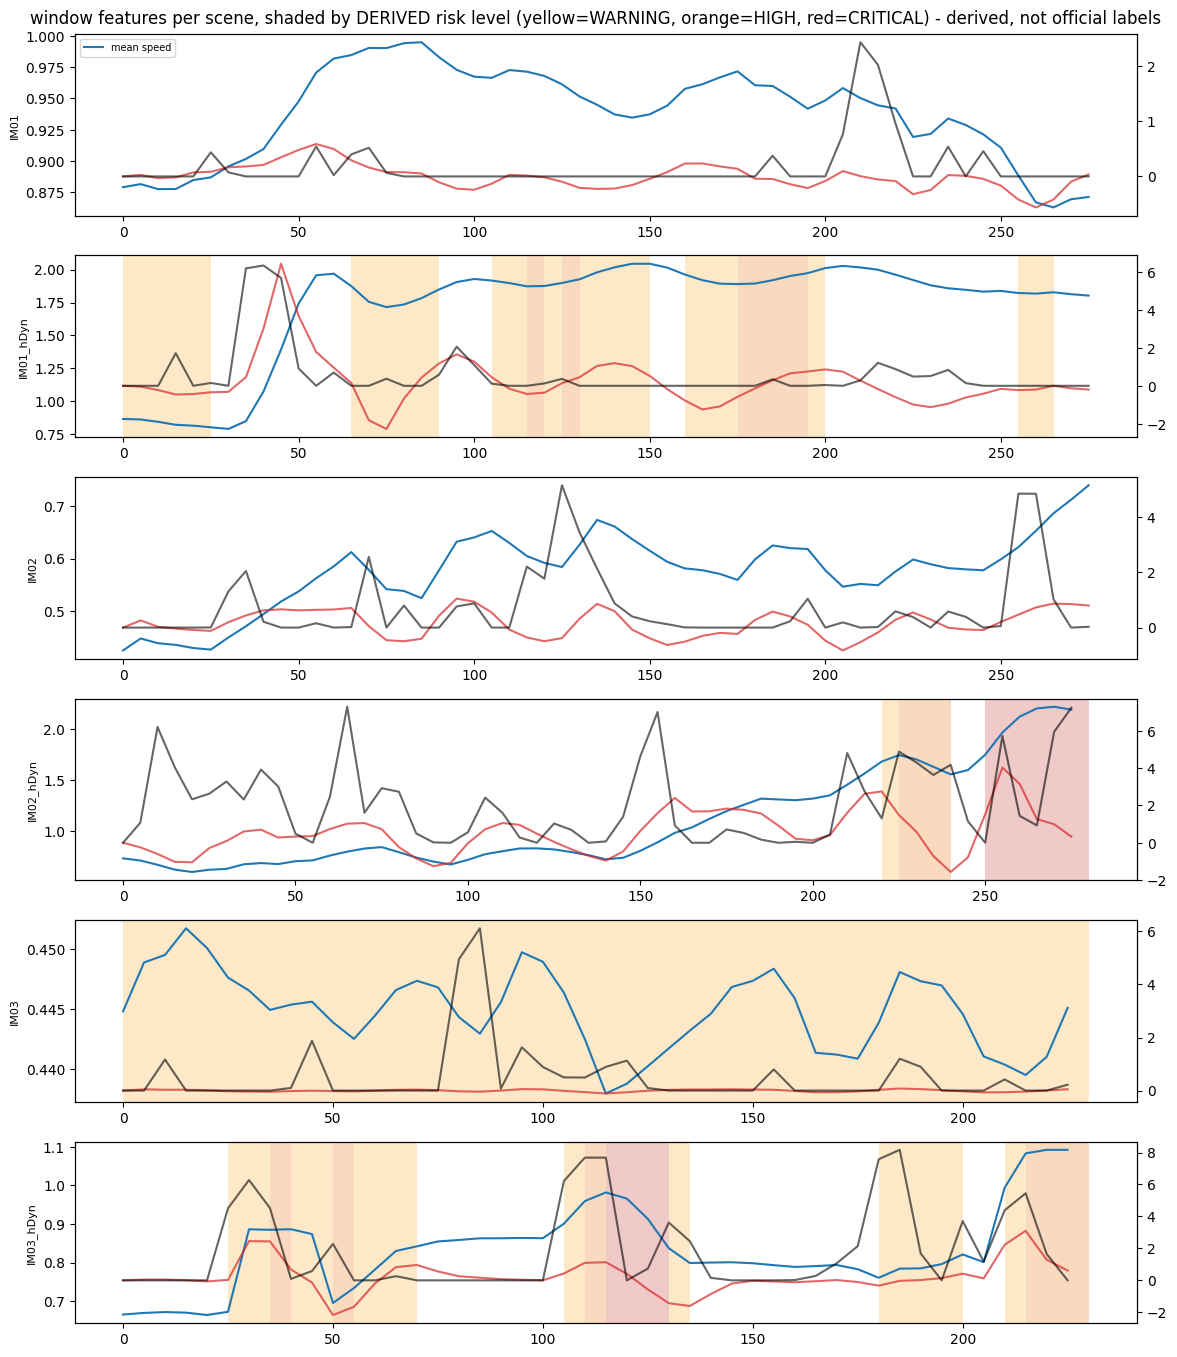

In [36]:
# ---- per-scene timelines: speed, speed change score, abnormality, shaded by DERIVED risk level ---------------------------------------------------
_nat = DF[DF.label_source == "natural_derived"]; _scs = sorted(_nat.scene.unique())[:6]; fig, axes = plt.subplots(len(_scs), 1, figsize=(12, 2.3 * len(_scs)), squeeze=False)
for _a, _s in zip(axes[:, 0], _scs):
    _d = _nat[_nat.scene == _s].sort_values("start_frame"); _x = _d.start_frame.values; _a.plot(_x, _d.mean_speed, label="mean speed"); _a2 = _a.twinx(); _a2.plot(_x, _d.speed_change_score, color="tab:red", alpha=0.7, label="speed change score"); _a2.plot(_x, 10 * _d.abnormality_score, color="k", alpha=0.6, label="abnormality x10")
    for _lv in (1, 2, 3):
        for _xv in _x[(_d.risk_label.values == _lv)]: _a.axvspan(_xv, _xv + cfg.hop, color=INTERVAL_COLORS[_lv], alpha=0.25, lw=0)
    _a.set_ylabel(_s, fontsize=8)
axes[0, 0].legend(loc="upper left", fontsize=7); plt.suptitle("window features per scene, shaded by DERIVED risk level (yellow=WARNING, orange=HIGH, red=CRITICAL) - derived, not official labels"); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "scene_timelines.png"), dpi=100); plt.show()


## 9. Evaluation of the abnormality detector (validation / test vs DERIVED truth) and hand-over

In [37]:
# ---- quality of the abnormality detector on VALIDATION and TEST against the DERIVED per-signal truth ----------------------------------------------------
_rows = []
for _split in ("val", "test"):
    _d = DF[DF.split == _split]; _act = DET._active_df(_d)
    for _s in SIGNALS:
        _t = _d[f"t_{_s}"].values.astype(float); _m = np.isfinite(_t)
        if _m.sum() >= 5 and (_t[_m] > .5).sum() >= 1:
            _p, _r, _f1, _ = precision_recall_fscore_support(_t[_m] > .5, _act[_s].values[_m], average="binary", zero_division=0); _rows.append(dict(split=_split, signal=_s, n=int(_m.sum()), truth_positive=int((_t[_m] > .5).sum()), precision=_p, recall=_r, F1=_f1))
SIGNAL_EVAL = pd.DataFrame(_rows); display(SIGNAL_EVAL.round(3)); SIGNAL_EVAL.to_csv(os.path.join(METRICS_DIR, "abnormality_signals_val_test.csv"), index=False)
ABN_EVAL = {}
for _split in ("val", "test"):
    _d = DF[DF.split == _split]; _y = _d[[f"t_{s}" for s in SIGNALS]].fillna(0).values.sum(1) >= 2
    if 0 < _y.sum() < len(_y): ABN_EVAL[_split] = dict(pr_auc=float(average_precision_score(_y, _d.abnormality_score)), roc_auc=float(roc_auc_score(_y, _d.abnormality_score)), f1_level2=float(f1_score(_y, _d.abnormality_level >= 2, zero_division=0)))
print("abnormality (>= 2 related derived signals) val/test:", {k: {a: round(b, 3) for a, b in v.items()} for k, v in ABN_EVAL.items()})
# ---- the three cases of the brief: more INDEPENDENT signals -> clearly stronger evidence (test windows) ---------------------------------------------------
_t = DF[DF.split == "test"]; _g = _t.groupby("n_active_groups").agg(windows=("abnormality_score", "size"), mean_abnormality_score=("abnormality_score", "mean"), share_derived_HIGH_or_CRITICAL=("risk_label", lambda x: float((x >= 2).mean())))
print("independent signal groups active -> evidence strength:"); display(_g.round(3))
_sh = _t[_t.sustained_high_speed.astype(bool) & (_t.n_active_signals == 0)]; print(f"SUSTAINED high speed with NO other signal: {len(_sh)} test windows, mean abnormality score {_sh.abnormality_score.mean() if len(_sh) else float('nan'):.3f}  (weak by design; high speed alone is not abnormal)")


,split,signal,n,truth_positive,precision,recall,F1
0,val,speed,136,18,0.389,0.778,0.519
1,val,acceleration,136,22,0.440,1.000,0.611
2,val,direction,136,22,0.667,0.636,0.651
3,val,density,44,8,1.000,1.000,1.000
4,val,compression,136,11,0.186,0.727,0.296
5,val,scattering,136,16,0.370,0.625,0.465
6,val,counterflow,136,8,0.000,0.000,0.000
7,val,convergence,136,11,0.229,0.727,0.348
8,val,temporal_change,136,26,0.407,0.846,0.550
9,test,speed,256,41,0.403,0.707,0.513


abnormality (>= 2 related derived signals) val/test: {'val': {'pr_auc': 0.672, 'roc_auc': 0.883, 'f1_level2': 0.659}, 'test': {'pr_auc': 0.627, 'roc_auc': 0.801, 'f1_level2': 0.553}}
independent signal groups active -> evidence strength:


,windows,mean_abnormality_score,share_derived_HIGH_or_CRITICAL
n_active_groups,,,
0,132,0.034,0.341
1,29,0.354,0.931
2,25,0.727,0.600
3,33,0.893,0.697
4,30,0.920,0.700
5,7,0.949,0.714


SUSTAINED high speed with NO other signal: 34 test windows, mean abnormality score 0.075  (weak by design; high speed alone is not abnormal)


In [38]:
# ---- hand-over to notebook 04: change model + detector (JSON), feature config, label rules, split; windows -> outputs/predictions/risk_feature_dataset.csv ------------------
AB_PATH = os.path.join(MODELS_DIR, "abnormal_motion.json")
RUN_META.update(window_len=WINDOW_LEN, hop=HOP, fps_assumption=FPS, flow_estimator=SELECTED_FLOW, work_width=WIDTH, abnormality_thresholds=DET.thr, split=SPLIT)
json.dump(json_safe(dict(change_model=CM_PRED.to_dict(), detector=DET.to_dict(), feature_config=cfg.to_dict(), label_rules=RULES, split=SPLIT, flow_estimator=SELECTED_FLOW, work_width=WIDTH, count_model_fingerprint=file_fingerprint(FINAL_COUNT_PATH),
               signals=SIGNALS, tags=ABN_TAGS, evaluation=dict(val_test_abnormality=ABN_EVAL), run_meta=RUN_META, note="Abnormal-behaviour labels / truths are DERIVED (weak) + synthetic injections; TUB has no official abnormal labels.")), open(AB_PATH, "w"), indent=1)
cfg.save(os.path.join(MODELS_DIR, "feature_config.json")); print("saved ->", AB_PATH, "\nsaved ->", os.path.join(PRED_DIR, "risk_feature_dataset.csv"), f"({len(DF)} windows)\nNext: notebook 04_Risk_Analysis_and_Video_Inference")


saved -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\abnormal_motion.json 
saved -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\outputs\predictions\risk_feature_dataset.csv (890 windows)
Next: notebook 04_Risk_Analysis_and_Video_Inference


## Limitations
All abnormal truths here are derived or synthetic (TUB has no official abnormal-event labels); the numbers measure agreement with the derivation on unseen scenes, not real-stampede detection. TUB has only a handful of scene groups, so tuned thresholds are noisy.